## Step 1. Audit and corpus preparation

### 1.1 Load the dataset and profile the raw corpus

In [1]:
from typing import TypedDict, Literal


# Dataset schema, kept explicit so the IDE and the reader see the field contract.
class Doc(TypedDict):
    doc_id: int
    title: str
    category: str
    format: Literal["text", "markdown", "html"]
    raw: str


class Query(TypedDict):
    query: str
    kind: Literal["exact", "semantic", "multi", "gap"]
    relevant_docs: list[int]
    gold: str


class KB(TypedDict):
    docs: list[Doc]
    queries: list[Query]

In [2]:
import json


with open("data/filmoskop_kb.json", encoding="utf-8") as f:
    data: KB = json.load(f)

docs: list[Doc] = data["docs"]
queries: list[Query] = data["queries"]

print("Docs: ", len(docs), "| Queries: ", len(queries))

Docs:  181 | Queries:  66


In [3]:
import pandas as pd

df = pd.DataFrame(docs)
df_q = pd.DataFrame(queries)

df["n_chars"] = df["raw"].str.len()
df["n_words"] = df["raw"].str.split().str.len()

pd.set_option("display.max_colwidth", 60)
df.head()

,doc_id,title,category,format,raw,n_chars,n_words
0,0,Промокоды,Подписка и оплата,text,Промокод даёт скидку на подписку или бесплатные дни. Вв...,441,73
1,1,Синхронизация между устройствами,Функции и контент,text,"Всё, что вы делаете в «Фильмоскопе», хранится не на устр...",1063,156
2,2,Безопасность аккаунта: общие советы,Аккаунт и профили,markdown,# Безопасность аккаунта: общие советы\n\nНесколько привы...,460,62
3,3,Что входит в подписку,Подписка и оплата,text,Подписка «Фильмоскопа» открывает доступ к полному катало...,921,130
4,4,Как мы тестируем качество видео,Устройства и качество,text,Как мы тестируем качество видео.\n\nУ «Фильмоскопа» есть...,1134,158


In [4]:
def profile_corpus(df: pd.DataFrame) -> pd.Series:
    """Compact corpus summary, reused later for the before/after comparison."""
    fmt_counts = df["format"].value_counts()
    summary = {
        "docs": len(df),
        "categories": df["category"].nunique(),
        **{f"fmt_{fmt}": n for fmt, n in fmt_counts.items()},
        "chars_min": df["n_chars"].min(),
        "chars_p10": df["n_chars"].quantile(0.10),
        "chars_median": df["n_chars"].median(),
        "chars_p90": df["n_chars"].quantile(0.90),
        "chars_max": df["n_chars"].max(),
        "words_median": df["n_words"].median(),
    }
    return pd.Series(summary, name="value").astype(int)

profile_before = profile_corpus(df)
profile_before.to_frame()

,value
docs,181
categories,5
fmt_text,132
fmt_markdown,28
fmt_html,21
chars_min,14
chars_p10,316
chars_median,664
chars_p90,1418
chars_max,3057


- 181 docs in 5 categories; plain text dominates (132), markdown (28) and HTML (21) are minorities.
- Length tails are suspicious on both ends: the shortest doc is 14 chars (a stub), the longest is 3057 chars (the long tail needs a closer look). Note that `n_words` over-counts HTML and mojibake, since tags and broken
byte sequences split into "words"; these are raw numbers, conclusions wait for the cleaned corpus.
- Only 43 of 181 docs are referenced by the 66 queries, so retrieval metrics will be computed on that subset;
the other docs act as distractors.

In [5]:
# Integrity checks before any cleaning; the last one is repeated on the cleaned corpus.
labeled_ids = {doc_id for q in queries for doc_id in q["relevant_docs"]}

assert df["doc_id"].is_unique, "duplicate doc_id"
assert df.isna().sum().sum() == 0, "missing values"
assert (df["raw"].str.strip() == "").sum() == 0, "empty raw text"
assert labeled_ids <= set(df["doc_id"]), "query references unknown doc_id"

print("Labeled docs:", len(labeled_ids), "of", len(df))
print("Queries by kind:", df_q["kind"].value_counts().to_dict())

Labeled docs: 43 of 181
Queries by kind: {'semantic': 25, 'multi': 16, 'exact': 15, 'gap': 10}


### 1.2 Category and format distribution

#### Categories and formats

In [6]:
category_counts = df["category"].value_counts()
category_counts.to_frame()

,count
category,
Устройства и качество,42
Подписка и оплата,38
Аккаунт и профили,35
Функции и контент,34
Ошибки воспроизведения,32


In [7]:
pd.crosstab(df["category"], df["format"], margins=True, margins_name="total")

format,html,markdown,text,total
category,,,,
Аккаунт и профили,3,2,30,35
Ошибки воспроизведения,4,5,23,32
Подписка и оплата,6,8,24,38
Устройства и качество,5,6,31,42
Функции и контент,3,7,24,34
total,21,28,132,181


#### Relevance label coverage

In [8]:
df["labeled"] = df["doc_id"].isin(labeled_ids)
pd.crosstab(df["category"], df["labeled"], margins=True, margins_name="total")

labeled,False,True,total
category,,,
Аккаунт и профили,26,9,35
Ошибки воспроизведения,24,8,32
Подписка и оплата,30,8,38
Устройства и качество,31,11,42
Функции и контент,27,7,34
total,138,43,181


- Categories are balanced (32-42 docs each), so a metadata filter by category cuts the candidate
  pool to roughly one fifth of the corpus; this makes the filter worth demonstrating at the retrieval step.
- All three formats appear in every category: markup problems are a property of the format, not of a topic,
  so cleaning is dispatched by `format`.
- Relevance labels cover every category (7-11 labeled docs each); no category is unobservable in the
  evaluation, though per-category metrics will be noisy with that few labeled docs.

#### Lengths by format

In [9]:
length_by_format = df.groupby("format")["n_chars"].describe(percentiles=[0.1, 0.5, 0.9]).astype(int)
length_by_format

,count,mean,std,min,10%,50%,90%,max
format,,,,,,,,
html,21,1014,945,42,149,570,2566,2818
markdown,28,980,608,420,437,802,1772,3057
text,132,733,449,14,304,659,1123,3017


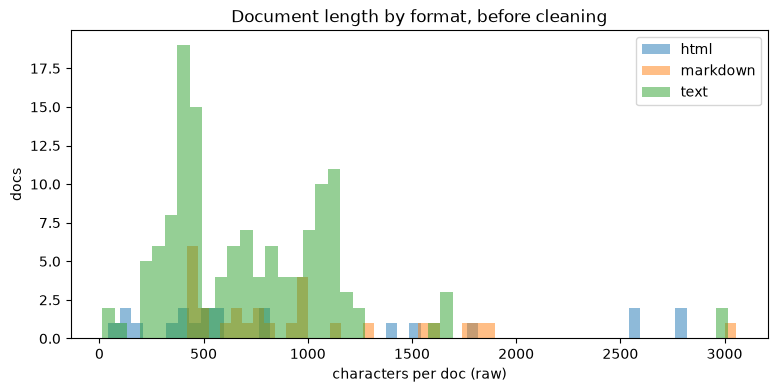

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
for fmt, group in df.groupby("format"):
    ax.hist(group["n_chars"], bins=50, alpha=0.5, label=fmt)
ax.set_xlabel("characters per doc (raw)")
ax.set_ylabel("docs")
ax.set_title("Document length by format, before cleaning")
ax.legend()
plt.show()

In [11]:
cols = ["doc_id", "format", "n_chars", "labeled", "title"]
display(df.nsmallest(8, "n_chars")[cols])
df.nlargest(5, "n_chars")[cols]

,doc_id,format,n_chars,labeled,title
153,153,text,14,False,Таблица совместимости (фрагмент)
156,156,html,42,False,Схема разделов (изображение)
145,145,text,70,False,Обновление приложения при ошибках
53,53,text,110,False,Раздел перенесён
71,71,html,129,False,Статья обновляется
74,74,html,149,False,Раздел в разработке
52,52,html,167,False,Раздел справки (архив)
39,39,text,230,False,Экспорт обращений за неделю


,doc_id,format,n_chars,labeled,title
73,73,markdown,3057,True,Аренда и покупка фильмов
159,159,text,3017,True,Вход на телевизоре по коду
22,22,text,2961,True,Объёмный звук 5.1
173,173,html,2818,True,Что делать при подозрении на взлом
110,110,html,2798,True,Что нужно для просмотра в 4K HDR


- HTML lengths fall into three clusters: p10 at ~150 chars (stubs wrapped in HTML), median ~570 (articles in a bare
  `kb-article` container), p90 at ~2570 (full pages with navigation and footer). One cleaning rule
  will not fit all three; HTML gets a parser that extracts the article container.
- Markdown has the highest median (~800 chars) with almost no markup overhead: these are simply longer
  articles plus a title line.
- The eight shortest docs (14-230 chars) are stubs and fragments by title: "фрагмент", "изображение",
  "Раздел перенесён", "Статья обновляется", "Раздел в разработке", "архив", a ticket export. None is labeled,
  so a minimum-length filter is safe for the evaluation; the threshold is going to be chosen in 1.3.
- The longest docs are plain text and markdown, not HTML, and all five are labeled. Length inflation here
  has a different mechanism than markup; we return to it in the quality heuristics.

In [12]:
def show_raw(doc_id: int, n: int = 350) -> None:
    """Print the first n characters of a doc as a Python literal, so invisible characters stay visible."""
    row = df.loc[df["doc_id"] == doc_id].iloc[0]
    print(f"doc {doc_id} | {row['format']} | {row['n_chars']} chars | {row['title']}")
    print(repr(row["raw"][:n]), end="\n\n")

In [13]:
for fmt in ["text", "markdown", "html"]:
    show_raw(df.loc[df["format"] == fmt, "doc_id"].iloc[0])

doc 0 | text | 441 chars | Промокоды
'Промокод даёт скидку на подписку или бесплатные дни. Ввести его можно в разделе «Подписка» — поле «У меня есть промокод» — или при оформлении подписки.\n\nПравила простые: один промокод на один аккаунт, скидки по промокодам не суммируются между собой и с другими акциями, у каждого кода есть срок действия — он указан в условиях акции. Если код не п'

doc 2 | markdown | 460 chars | Безопасность аккаунта: общие советы
'# Безопасность аккаунта: общие советы\n\nНесколько привычек, которые защищают аккаунт лучше любых настроек:\n\nиспользуйте уникальный пароль, который не повторяется на других сайтах; не вводите данные аккаунта на сторонних сайтах и не переходите по ссылкам из подозрительных писем «от сервиса»; не делитесь аккаунтом с людьми вне семьи; периодически прос'

doc 8 | html | 471 chars | Пользовательское соглашение (выдержка): контент
'<div class="kb-article"><h1>Пользовательское соглашение (выдержка): контент</h1>\n<p>Пользовательское согл

In [14]:
show_raw(73)
show_raw(110, n=500)

doc 73 | markdown | 3057 chars | Аренда и покупка фильмов
'# Ð\x90Ñ\x80ÐµÐ½Ð´Ð° Ð¸ Ð¿Ð¾ÐºÑ\x83Ð¿ÐºÐ° Ñ\x84Ð¸Ð»Ñ\x8cÐ¼Ð¾Ð²\n\nÐ\x9fÐ»Ð°Ñ\x82Ð½Ñ\x8bÐµ Ñ\x84Ð¸Ð»Ñ\x8cÐ¼Ñ\x8b Ð²Ð¸Ð´Ð½Ñ\x8b Ð¿Ñ\x80Ñ\x8fÐ¼Ð¾ Ð² ÐºÐ°Ñ\x82Ð°Ð»Ð¾Ð³Ðµ: Ð² ÐºÐ°Ñ\x80Ñ\x82Ð¾Ñ\x87ÐºÐµ Ð²Ð¼ÐµÑ\x81Ñ\x82Ð¾ ÐºÐ½Ð¾Ð¿ÐºÐ¸ Â«Ð¡Ð¼Ð¾Ñ\x82Ñ\x80ÐµÑ\x82Ñ\x8cÂ» Ð¿Ð¾Ñ\x8fÐ²Ð»Ñ\x8fÑ\x8eÑ\x82Ñ\x81Ñ\x8f Â«Ð\x90Ñ\x80ÐµÐ½Ð´Ð¾Ð²Ð°Ñ\x82Ñ\x8cÂ» Ð¸ Â«Ð\x9aÑ\x83Ð¿Ð¸Ñ\x82Ñ\x8cÂ», Ð° Ñ\x80Ñ\x8fÐ´Ð¾Ð¼ Ñ\x83ÐºÐ°Ð·Ð°Ð½Ð° Ñ\x86ÐµÐ½Ð°. Ð\x9eÑ\x84Ð¾Ñ\x80Ð¼Ð»Ñ\x8fÑ\x82Ñ\x8c Ñ\x87Ñ\x82Ð¾-Ñ\x82Ð¾ Ð¾Ñ\x82Ð´ÐµÐ»Ñ\x8cÐ½Ð¾ Ð½Ðµ Ð½Ñ\x83'

doc 110 | html | 2798 chars | Что нужно для просмотра в 4K HDR
'<!DOCTYPE html><html><head><title>Что нужно для просмотра в 4K HDR — Справка «Фильмоскопа»</title><meta name="viewport" content="width=device-width"></head><body>\n<nav class="main-menu"><a href="/">Главная</a> <a href="/help">Справка</a> <a href="/movies">Фильмы</a> <a href="/series">Сериалы</a></nav>\n<div class="breadcrumbs">Главная &rarr; Справка &rarr; 

Problems visible by eye, to be quantified in 1.3:

- mojibake: UTF-8 text decoded as latin-1 (doc 73), which also doubles the character count;
- full HTML pages with site boilerplate: navigation, breadcrumbs, cookie banner, footer (doc 110);
- HTML entities (`&rarr;`, `&copy;`) and a `title` suffix "— Справка «Фильмоскопа»";
- the title duplicated as the first line of the body (markdown `# ...`, HTML `<h1>`);
- stubs and fragments at the short tail of the length distribution.

### 1.3 Data quality heuristics

#### Junk character share and encoding

In [15]:
import re


def junk_ratio(text: str) -> float:
    """Share of characters that are neither word characters, whitespace nor basic punctuation."""
    junk = re.findall(r"[^\w\s.,!?;:()«»—-]", text)
    return len(junk) / len(text)


df["junk_ratio"] = df["raw"].map(junk_ratio)
df["junk_ratio"].describe(percentiles=[0.5, 0.9, 0.95]).round(3)

count    181.000
mean       0.034
std        0.076
min        0.000
50%        0.001
90%        0.140
95%        0.256
max        0.282
Name: junk_ratio, dtype: float64

In [16]:
JUNK_THRESHOLD = 0.15  # just above p90 of the distribution above; the flagged docs start at 0.155

cols = ["doc_id", "format", "n_chars", "labeled", "junk_ratio", "title"]
df[df["junk_ratio"] > JUNK_THRESHOLD].sort_values("junk_ratio", ascending=False)[cols]

,doc_id,format,n_chars,labeled,junk_ratio,title
111,111,text,777,True,0.281853,Продолжить просмотр на другом устройстве
178,178,text,1257,True,0.280827,Ошибка P-109: недостаточно места
60,60,text,843,False,0.274021,Wi-Fi или кабель: как подключить телевизор
106,106,text,717,True,0.273361,Чеки и история платежей
46,46,text,604,False,0.273179,Памятка по оценкам
54,54,text,683,False,0.263543,Приложение зависает на заставке
55,55,text,833,True,0.258103,Восстановление пароля
112,112,text,881,True,0.257662,Нет звука или звук отстаёт
22,22,text,2961,True,0.256332,Объёмный звук 5.1
43,43,text,860,False,0.255814,Аудиодорожки и оригинальная озвучка


In [17]:
# UTF-8 Cyrillic is two bytes, 0xD0/0xD1 + 0x80..0xBF; read as latin-1 that becomes
# U+00D0 or U+00D1 followed by one character from U+0080..U+00BF.
MOJIBAKE_RE = re.compile(r"[ÐÑ][\u0080-\u00bf]")


def mojibake_ratio(text: str) -> float:
    """Share of characters covered by UTF-8-as-latin-1 byte pairs."""
    return 2 * len(MOJIBAKE_RE.findall(text)) / len(text)


df["mojibake_ratio"] = df["raw"].map(mojibake_ratio)
df["is_mojibake"] = df["mojibake_ratio"] > 0.5

print("Mojibake docs:", df["is_mojibake"].sum(), "| labeled among them:", df.loc[df["is_mojibake"], "labeled"].sum())
df.loc[df["is_mojibake"], ["doc_id", "format", "n_chars", "labeled", "mojibake_ratio", "title"]].sort_values("doc_id")

Mojibake docs: 16 | labeled among them: 11


,doc_id,format,n_chars,labeled,mojibake_ratio,title
22,22,text,2961,True,0.899021,Объёмный звук 5.1
38,38,text,847,True,0.894923,Объединение аккаунтов и перенос подписки
43,43,text,860,False,0.900000,Аудиодорожки и оригинальная озвучка
46,46,text,604,False,0.890728,Памятка по оценкам
54,54,text,683,False,0.916545,Приложение зависает на заставке
55,55,text,833,True,0.885954,Восстановление пароля
60,60,text,843,False,0.863582,Wi-Fi или кабель: как подключить телевизор
73,73,markdown,3057,True,0.885182,Аренда и покупка фильмов
93,93,text,693,False,0.894661,Голосовое управление на телевизоре
106,106,text,717,True,0.895397,Чеки и история платежей


In [18]:
def try_fix_mojibake(text: str) -> str | None:
    """Reverse UTF-8-as-latin-1 decoding; None when the text is not a valid round trip."""
    try:
        return text.encode("latin-1").decode("utf-8")
    except UnicodeError:
        return None


recoverable = df.loc[df["is_mojibake"], "raw"].map(try_fix_mojibake).notna()
print("Recoverable:", recoverable.sum(), "of", len(recoverable))
print(repr(try_fix_mojibake(df.loc[df["doc_id"] == 73, "raw"].iloc[0])[:200]))

Recoverable: 16 of 16
'# Аренда и покупка фильмов\n\nПлатные фильмы видны прямо в каталоге: в карточке вместо кнопки «Смотреть» появляются «Арендовать» и «Купить», а рядом указана цена. Оформлять что-то отдельно не нужно — оп'


- `junk_ratio` > 0.15 flags 18 docs: 16 are mojibake (UTF-8 decoded as latin-1), 2 are HTML pages that
  crossed the threshold on tag characters. The coarse heuristic points at the right docs but mixes two
  unrelated problems, and misses 5 of 7 full HTML pages.
- A targeted detector (`[ÐÑ]` + one char from U+0080..U+00BF) separates the two cleanly: 16 docs with
  a ratio of 0.73-0.92, everything else exactly 0. 11 of the 16 are labeled, a quarter of all relevance
  labels; dropping them would cost recall before retrieval even starts.
- All 16 round-trip through latin-1 -> UTF-8 without errors, so the damage is reversible: repair, not drop.

#### Markup residue

In [19]:
from collections import Counter

TAG_RE = re.compile(r"<[^>]+>")
ENTITY_RE = re.compile(r"&(#\d+|#x[0-9a-fA-F]+|[a-zA-Z]+);")
MD_RE = re.compile(r"^(#{1,6} |[-*] |\d+\. )|\*\*", re.MULTILINE)


def tag_ratio(text: str) -> float:
    """Share of characters that sit inside HTML tags."""
    return sum(len(tag) for tag in TAG_RE.findall(text)) / len(text)


df["n_tags"] = df["raw"].map(lambda t: len(TAG_RE.findall(t)))
df["tag_ratio"] = df["raw"].map(tag_ratio)
df["n_entities"] = df["raw"].map(lambda t: len(ENTITY_RE.findall(t)))
df["n_md_marks"] = df["raw"].map(lambda t: len(MD_RE.findall(t)))
df["is_full_page"] = df["raw"].str.contains("<!DOCTYPE", case=False)

markup_by_format = df.groupby("format").agg(
    docs=("doc_id", "size"),
    with_tags=("n_tags", lambda s: (s > 0).sum()),
    with_entities=("n_entities", lambda s: (s > 0).sum()),
    with_md_marks=("n_md_marks", lambda s: (s > 0).sum()),
    full_pages=("is_full_page", "sum"),
)
markup_by_format

,docs,with_tags,with_entities,with_md_marks,full_pages
format,,,,,
html,21,21,7,0,7
markdown,28,0,0,28,0
text,132,0,0,1,0


In [20]:
cols = ["doc_id", "labeled", "n_chars", "n_tags", "tag_ratio", "n_entities", "is_full_page", "title"]
df.loc[df["format"] == "html", cols].sort_values("tag_ratio", ascending=False).round(2)

,doc_id,labeled,n_chars,n_tags,tag_ratio,n_entities,is_full_page,title
156,156,False,42,2,0.67,0,False,Схема разделов (изображение)
147,147,True,1418,64,0.43,3,True,Детский профиль
154,154,True,1520,62,0.40,3,True,"Что делать, если оплата не прошла"
71,71,False,129,6,0.36,0,False,Статья обновляется
47,47,True,1764,66,0.35,3,True,Ошибка P-103: контент недоступен в регионе
74,74,False,149,6,0.31,0,False,Раздел в разработке
52,52,False,167,6,0.28,0,False,Раздел справки (архив)
99,99,True,2564,74,0.25,3,True,Совместный просмотр
155,155,True,2566,74,0.25,3,True,Пробный период
173,173,True,2818,80,0.24,3,True,Что делать при подозрении на взлом


In [21]:
full_pages = df.loc[df["is_full_page"], "raw"]

for block in ["nav", "aside", "footer"]:
    n_unique = full_pages.str.extract(rf"(<{block}.*?</{block}>)", expand=False).nunique()
    print(f"unique <{block}> blocks across {len(full_pages)} pages: {n_unique}")

article_share = full_pages.map(lambda t: len(re.search(r"<article.*?</article>", t, re.DOTALL).group()) / len(t))
print("article share of the page:", article_share.round(2).tolist())
print("entities:", Counter(e for t in full_pages for e in ENTITY_RE.findall(t)))
print("elements:", Counter(tag for t in full_pages for tag in re.findall(r"<(\w+)[ >]", t)).most_common(12))

unique <nav> blocks across 7 pages: 1
unique <aside> blocks across 7 pages: 1
unique <footer> blocks across 7 pages: 1
article share of the page: [0.49, 0.66, 0.68, 0.39, 0.42, 0.66, 0.69]
entities: Counter({'rarr': 14, 'copy': 7})
elements: [('p', 53), ('a', 49), ('div', 21), ('button', 21), ('li', 14), ('html', 7), ('head', 7), ('title', 7), ('meta', 7), ('body', 7), ('nav', 7), ('main', 7)]


- Markup lives exactly where `format` says: tags only in the 21 HTML docs, markdown marks only in the
  28 markdown docs (plus one numbered list inside a plain-text memo). Cleaning can be dispatched by `format`.
- HTML splits into 7 full pages (62-80 tags, 3 entities each, all labeled) and 14 bare
  `<div class="kb-article"><h1>..</h1><p>..</p></div>` wrappers (6 tags, none labeled). `tag_ratio` ranks
  a 42-char stub above the full pages, so it measures markup density, not the amount of boilerplate;
  the structural flag `is_full_page` is the useful one.
- The 7 pages share one template verbatim (identical nav, aside, footer); the article is 39-69% of the
  page. Stripping tags without removing these blocks would inject the same navigation text, cookie notice
  and "Читайте также" links into 7 labeled docs. HTML therefore needs a parser that extracts the article
  container, and entities (`&rarr;` x14, `&copy;` x7) need decoding.

#### Title repeated in the body

In [22]:
import html

# Text-level detectors from here on run on encoding-repaired text: the repair is lossless (1.3a),
# and without it the 16 mojibake docs are opaque to every string comparison below.
df["raw_fixed"] = [try_fix_mojibake(t) or t for t in df["raw"]]


def body_heading(text: str, fmt: str) -> str:
    """The heading a reader sees first in the body: <h1> for HTML, the first non-empty line otherwise."""
    if fmt == "html":
        m = re.search(r"<h1>(.*?)</h1>", text)
        return html.unescape(m.group(1)) if m else ""
    first = next((line for line in text.splitlines() if line.strip()), "")
    return first.lstrip("#").strip() if fmt == "markdown" else first.strip()


def norm_title(s: str) -> str:
    """Case- and punctuation-insensitive form for comparing titles."""
    return re.sub(r"\W+", " ", s.lower()).strip()


df["heading"] = [body_heading(t, f) for t, f in zip(df["raw_fixed"], df["format"])]
df["title_in_body"] = [norm_title(h) == norm_title(t) for h, t in zip(df["heading"], df["title"])]

pd.crosstab(df["format"], df["title_in_body"], margins=True, margins_name="total")

title_in_body,False,True,total
format,,,
html,1,20,21
markdown,0,28,28
text,128,4,132
total,129,52,181


In [23]:
cols = ["doc_id", "format", "labeled", "title", "heading"]
display(df.loc[(df["format"] == "text") & df["title_in_body"], cols])
df.loc[(df["format"] != "text") & ~df["title_in_body"], cols]

,doc_id,format,labeled,title,heading
4,4,text,False,Как мы тестируем качество видео,Как мы тестируем качество видео.
16,16,text,False,«Фильмоскоп» обновил технологию доставки видео,«Фильмоскоп» обновил технологию доставки видео.
53,53,text,False,Раздел перенесён,Раздел перенесён.
142,142,text,False,Вакансия: инженер по качеству видео,Вакансия: инженер по качеству видео.


,doc_id,format,labeled,title,heading
156,156,html,False,Схема разделов (изображение),


In [24]:
page_rows = df.loc[df["is_full_page"]]
first_p = page_rows["raw"].str.extract(r"<h1>.*?</h1>\s*<p>(.*?)</p>", expand=False)
first_p_repeats_title = [norm_title(p).startswith(norm_title(t)) for p, t in zip(first_p, page_rows["title"])]

pd.DataFrame({"doc_id": page_rows["doc_id"].values, "first_p_repeats_title": first_p_repeats_title})

,doc_id,first_p_repeats_title
0,47,False
1,99,False
2,110,True
3,147,False
4,154,True
5,155,False
6,173,True


- The title is repeated as the first body line in all 28 markdown docs (`# ...`), as `<h1>` in 20 of 21
  HTML docs, and as a plain first line with a trailing period in 4 text docs; the 4 text cases are
  non-help content (press release, vacancy, blog post, a stub), all unlabeled.
- In 3 of the 7 full pages the title appears a third time at the start of the first paragraph, once glued
  to the paragraph text without punctuation (doc 154), so the strip rule must match a prefix, not a line.
- Decision: the title stays in metadata and is removed from the body with one rule for all formats, so the
  first chunk is not biased toward the title when it is later prepended from metadata.

#### Stubs, archive, internal and service documents

In [25]:
def plain_view(text: str) -> str:
    """Rough tag-free view for pattern search only; the real parser comes in 1.4."""
    text = re.sub(r"<head>.*?</head>", " ", text, flags=re.DOTALL)
    text = html.unescape(re.sub(r"<[^>]+>", " ", text))
    text = re.sub(r"^#+ .*$", " ", text, flags=re.MULTILINE)
    return re.sub(r"\s+", " ", text).strip()


df["plain"] = df["raw_fixed"].map(plain_view)
df["plain_len"] = df["plain"].str.len()

ARCHIVE_RE = re.compile(r"статья устарела и хранится в архиве|\(архив", re.IGNORECASE)
STUB_RE = re.compile(
    r"Статья обновляется|Раздел в разработке|Раздел перенесён|Страница не найдена|Здесь будет текст статьи"
    r"|^Черновик|\(фрагмент\)|\(изображение\)",
    re.IGNORECASE,
)
INTERNAL_RE = re.compile(r"не публиковать|внутренний документ|\(служебное\)|^(?:Протокол|Регламент|Шаблон)\b", re.IGNORECASE)
SERVICE_RE = re.compile(r"ticket_id;|^\{\"|\bSELECT\b.*\bFROM\b")


def flag(pattern: re.Pattern) -> pd.Series:
    """True when the pattern occurs in the title or in the plain view."""
    return df["title"].str.contains(pattern) | df["plain"].str.contains(pattern)


df["is_archived"] = flag(ARCHIVE_RE)
df["is_stub"] = flag(STUB_RE)
df["is_internal"] = flag(INTERNAL_RE)
df["is_service_dump"] = df["plain"].str.contains(SERVICE_RE)

content_flags = ["is_archived", "is_stub", "is_internal", "is_service_dump"]
df[content_flags].sum().to_frame("docs")

,docs
is_archived,21
is_stub,8
is_internal,8
is_service_dump,3


In [26]:
cols = ["doc_id", "format", "labeled", "plain_len", *content_flags, "title"]
df.sort_values("plain_len").head(12)[cols]

,doc_id,format,labeled,plain_len,is_archived,is_stub,is_internal,is_service_dump,title
153,153,text,False,14,False,True,False,False,Таблица совместимости (фрагмент)
156,156,html,False,14,False,True,False,False,Схема разделов (изображение)
145,145,text,False,70,False,False,False,False,Обновление приложения при ошибках
71,71,html,False,82,False,True,False,False,Статья обновляется
74,74,html,False,102,False,True,False,False,Раздел в разработке
53,53,text,False,108,False,True,True,False,Раздел перенесён
52,52,html,False,120,True,True,False,False,Раздел справки (архив)
39,39,text,False,229,False,False,False,True,Экспорт обращений за неделю
75,75,text,False,230,False,False,False,True,Конфигурация player-api
127,127,text,False,236,False,False,False,False,Опрос о работе личного кабинета


In [27]:
MIN_PLAIN_CHARS = 150  # natural gap in the length distribution: 120 -> 229, see the table above

df["is_short"] = df["plain_len"] < MIN_PLAIN_CHARS
df.loc[df["is_short"] & ~df[content_flags].any(axis=1), cols]

,doc_id,format,labeled,plain_len,is_archived,is_stub,is_internal,is_service_dump,title
145,145,text,False,70,False,False,False,False,Обновление приложения при ошибках


In [28]:
drop_flags = [*content_flags, "is_short"]
df["drop_candidate"] = df[drop_flags].any(axis=1)

print("Drop candidates:", df["drop_candidate"].sum(), "| labeled among them:", df.loc[df["drop_candidate"], "labeled"].sum())
print("By format:", df.loc[df["drop_candidate"], "format"].value_counts().to_dict())
print("By category:", df.loc[df["drop_candidate"], "category"].value_counts().to_dict())
df.loc[df["drop_candidate"] & (df[drop_flags].sum(axis=1) > 1), ["doc_id", *drop_flags, "title"]]

Drop candidates: 37 | labeled among them: 0
By format: {'text': 26, 'markdown': 7, 'html': 4}
By category: {'Подписка и оплата': 11, 'Аккаунт и профили': 7, 'Функции и контент': 7, 'Устройства и качество': 6, 'Ошибки воспроизведения': 6}


,doc_id,is_archived,is_stub,is_internal,is_service_dump,is_short,title
52,52,True,True,False,False,True,Раздел справки (архив)
53,53,False,True,True,False,True,Раздел перенесён
71,71,False,True,False,False,True,Статья обновляется
74,74,False,True,False,False,True,Раздел в разработке
80,80,False,False,True,True,False,Выгрузка по профилям (служебное)
126,126,False,True,True,False,False,Проверка вёрстки
153,153,False,True,False,False,True,Таблица совместимости (фрагмент)
156,156,False,True,False,False,True,Схема разделов (изображение)


- Four content-based detectors over a tag-free view: archived articles (21, incl. 7 markdown ones whose
  notice sits below the heading and one 404 page), CMS stubs and drafts (8), internal documents marked
  "не публиковать" or by genre (8), machine dumps: CSV, JSON, SQL (3).
- Length is almost redundant: with `MIN_PLAIN_CHARS = 150`, placed in the natural gap 120 -> 229, the only
  doc dropped by length alone is a one-sentence tip (doc 145).
- 37 drop candidates in total, spread over all formats and categories, none labeled. The check against
  labels is a safety net applied after the decisions, not a selection criterion.
- Archived articles are the most harmful class: fluent, on-topic, normal length, but factually outdated
  (7-day trial "until 2024", 4-digit TV login code). Example pair: doc 92 (archive) vs doc 155 (current).

#### Public but non-help content

In [29]:
NON_HELP_RE = re.compile(
    r"вакансия|резюме —"                       # HR
    r"|объявил о переходе|по данным компании"   # press release
    r"|кино без компромиссов|почувствуйте разницу"  # advertising copy
    r"|истории зрителей"                        # testimonials
    r"|пройдите короткий опрос|плановые работы",  # one-off notices
    re.IGNORECASE,
)

df["is_non_help"] = flag(NON_HELP_RE)

cols = ["doc_id", "format", "labeled", "category", "plain_len", "title"]
display(df.loc[df["is_non_help"], cols])
print("labeled among non-help:", df.loc[df["is_non_help"], "labeled"].sum())

,doc_id,format,labeled,category,plain_len,title
16,16,text,False,Устройства и качество,414,«Фильмоскоп» обновил технологию доставки видео
18,18,text,False,Аккаунт и профили,237,Плановые работы (объявление)
32,32,html,False,Подписка и оплата,352,Почему зрители выбирают «Максимум»
127,127,text,False,Аккаунт и профили,236,Опрос о работе личного кабинета
134,134,text,False,Функции и контент,366,Совместный просмотр: истории зрителей
142,142,text,False,Устройства и качество,465,Вакансия: инженер по качеству видео


labeled among non-help: 0


In [30]:
editorial_examples = [6, 11, 13, 79, 91, 168]
df.loc[df["doc_id"].isin(editorial_examples), ["doc_id", "labeled", "category", "title"]]

,doc_id,labeled,category,title
6,6,False,Функции и контент,10 фильмов для уютного вечера
11,11,False,Устройства и качество,История «Фильмоскопа»
13,13,False,Функции и контент,Как делают субтитры
79,79,False,Функции и контент,Как редакция собирает подборки
91,91,False,Функции и контент,Смотрим вместе: идеи для киновечера
168,168,False,Подписка и оплата,Первые дни в «Фильмоскопе»


In [31]:
drop_flags = [*content_flags, "is_short", "is_non_help"]
df["drop_candidate"] = df[drop_flags].any(axis=1)
print("Drop candidates:", df["drop_candidate"].sum(), "| labeled:", df.loc[df["drop_candidate"], "labeled"].sum(), "| remaining docs:", (~df["drop_candidate"]).sum())

Drop candidates: 43 | labeled: 0 | remaining docs: 138


- Criterion for this class: the text carries no instruction or fact about the service that a user could act
  on. Genre markers (HR, press release, advertising copy, testimonials, one-off notices) flag 6 docs, none
  labeled; three of them were already suspicious in 1.3c (title as first line) and two sat just above the
  length threshold in 1.3d.
- Why they are harmful despite being public: advertising copy competes with the tariff article for the same
  queries, and an undated maintenance notice answers "is the account unavailable" with stale certainty.
- Editorial and explainer articles (film picks, service history, how subtitles are made) stay: they answer
  plausible user questions and contradict nothing. The markers are corpus-specific by construction and are
  reported as such, not as a general classifier.
- Running total: 43 drop candidates, 138 docs remain.

#### Near-duplicates

In [32]:
import hashlib
import unicodedata

ZERO_WIDTH_RE = re.compile(r"[\u200b\u200c\u200d\ufeff]")


def dedup_key(text: str, title: str) -> str:
    """Body text with everything that does not change meaning stripped: Unicode form, case,
    yo/ye, punctuation, invisible characters and a leading copy of the title."""

    def norm(s: str) -> str:
        s = unicodedata.normalize("NFC", ZERO_WIDTH_RE.sub("", s)).lower().replace("ё", "е")
        return re.sub(r"\s+", " ", re.sub(r"[^\w\s]+", " ", s)).strip()

    body, head = norm(text), norm(title)
    while head and body.startswith(head):
        body = body[len(head):].strip()
    return body


df["dedup_key"] = [dedup_key(p, t) for p, t in zip(df["plain"], df["title"])]
df["dedup_hash"] = df["dedup_key"].map(lambda s: hashlib.sha1(s.encode()).hexdigest()[:12])

exact_dups = df[df.duplicated("dedup_hash", keep=False)].sort_values(["dedup_hash", "doc_id"])
print("Exact duplicate groups after normalization:", exact_dups["dedup_hash"].nunique())
exact_dups[["dedup_hash", "doc_id", "format", "labeled", "title"]]

Exact duplicate groups after normalization: 5


,dedup_hash,doc_id,format,labeled,title
7,8df92c1521d8,7,text,False,Удаление аккаунта
121,8df92c1521d8,121,html,False,Как удалить аккаунт
77,96bd23b8bbe8,77,text,False,Как смотреть с телефона на большом экране
175,96bd23b8bbe8,175,text,True,Трансляция через Chromecast и AirPlay
83,a73fcd2d16a7,83,text,False,Как зарегистрироваться
151,a73fcd2d16a7,151,text,False,Регистрация аккаунта
0,bb1a481c4367,0,text,False,Промокоды
95,bb1a481c4367,95,text,False,Промокоды и скидки
105,ff3bc7379c43,105,text,False,Поиск фильмов и сериалов
158,ff3bc7379c43,158,text,True,Поиск по каталогу


In [33]:
from difflib import SequenceMatcher
from itertools import combinations

keys = df["dedup_key"].tolist()
hashes = df["dedup_hash"].tolist()
ids = df["doc_id"].tolist()

fuzzy_pairs = []
for i, j in combinations(range(len(df)), 2):
    if hashes[i] == hashes[j]:
        continue  # already an exact duplicate
    a, b = keys[i], keys[j]
    if abs(len(a) - len(b)) / max(len(a), len(b)) > 0.2:
        continue  # length prefilter keeps the quadratic pass cheap
    sm = SequenceMatcher(None, a, b)
    if sm.quick_ratio() > 0.8 and sm.ratio() > 0.8:
        fuzzy_pairs.append((round(sm.ratio(), 3), ids[i], ids[j]))

fuzzy_pairs = sorted(fuzzy_pairs, reverse=True)
print("Near-duplicate pairs not caught by the hash:", fuzzy_pairs)
for _, a, b in fuzzy_pairs:
    print(a, repr(df.loc[df["doc_id"] == a, "dedup_key"].iloc[0][:70]))
    print(b, repr(df.loc[df["doc_id"] == b, "dedup_key"].iloc[0][:70]), end="\n\n")

Near-duplicate pairs not caught by the hash: [(0.982, 23, 160), (0.961, 86, 146)]
23 'ошибка p 107 в браузере ошибка p 107 появляется когда браузер не может'
160 'ошибка p 107 появляется когда браузер не может воспроизвести защищенно'

86 'на каких устройствах работает фильмоскоп телевизоры smart tv samsung t'
146 'телевизоры smart tv samsung tizen модели с 2018 года lg webos 4 0 и но'



In [34]:
dup_groups = [sorted(g["doc_id"]) for _, g in exact_dups.groupby("dedup_hash")]
dup_groups += [sorted([a, b]) for _, a, b in fuzzy_pairs]

keep_id = {max(g) for g in dup_groups}
drop_as_dup = {i for g in dup_groups for i in g if i != max(g)}
alt_titles = {max(g): [df.loc[df["doc_id"] == i, "title"].iloc[0] for i in g if i != max(g)] for g in dup_groups}

df["is_duplicate"] = df["doc_id"].isin(drop_as_dup)
print("Duplicate groups:", len(dup_groups), "| dropped as duplicates:", len(drop_as_dup), "| labeled among dropped:", df.loc[df["is_duplicate"], "labeled"].sum())
print("Labeled docs kept in groups:", sorted(i for i in keep_id if i in labeled_ids))
alt_titles

Duplicate groups: 7 | dropped as duplicates: 7 | labeled among dropped: 0
Labeled docs kept in groups: [146, 158, 175]


{121: ['Удаление аккаунта'],
 175: ['Как смотреть с телефона на большом экране'],
 151: ['Как зарегистрироваться'],
 95: ['Промокоды'],
 158: ['Поиск фильмов и сериалов'],
 160: ['Ошибка P-107 (браузер)'],
 146: ['Поддерживаемые устройства']}

In [35]:
drop_flags = [*content_flags, "is_short", "is_non_help", "is_duplicate"]
df["drop_candidate"] = df[drop_flags].any(axis=1)
print("Drop candidates:", df["drop_candidate"].sum(), "| labeled:", df.loc[df["drop_candidate"], "labeled"].sum(), "| remaining docs:", (~df["drop_candidate"]).sum())

Drop candidates: 50 | labeled: 0 | remaining docs: 131


- Duplicates are invisible to exact comparison: the pairs differ by yo/ye, quote style, dash style,
  invisible characters, HTML wrapper vs plain text, and in two docs by Unicode form (NFD: "й" stored as
  "и" + combining diaeresis). A normalization key (NFC, lowercase, yo->ye, punctuation and zero-width
  characters removed, leading title stripped) collapses 5 pairs exactly.
- A fuzzy pass (`SequenceMatcher`, length prefilter, ratio > 0.8) finds 2 more pairs at 0.96-0.98: copies
  that were renamed while the body kept the previous title line. Nothing else scores above 0.8.
- Keep rule: the higher `doc_id` is treated as the later revision; the other title is kept as an alternative
  title in metadata. Post hoc check: in all 3 labeled pairs the kept doc is the labeled one.
- Running total: 50 drop candidates, 131 docs remain.

#### Invisible characters, Unicode form, homoglyphs and hyphenation

In [36]:
CYR = "А-Яа-яЁё"

char_detectors = {
    "zero_width": re.compile(r"[\u200b\u200c\u200d\ufeff]"),
    "nbsp": re.compile(r"[\u00a0\u2007\u202f]"),
    "control": re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f-\x9f]"),
    "multi_space": re.compile(r"[ \t]{2,}"),
    "triple_newline": re.compile(r"\n{3,}"),
    "hyphen_break": re.compile(rf"[{CYR}]-\n[{CYR}]"),
    # a word that mixes Latin and Cyrillic letters, e.g. a Cyrillic word with a Latin "o" inside
    "mixed_script_word": re.compile(rf"\b(?=[^\W\d_]*[A-Za-z])(?=[^\W\d_]*[{CYR}])[^\W\d_]+\b"),
}


def count_combining(text: str) -> int:
    """Combining marks signal decomposed (NFD) letters: a base letter plus U+0308 instead of the precomposed one."""
    return sum(1 for ch in text if unicodedata.combining(ch))


char_counts = pd.DataFrame({name: df["raw_fixed"].map(lambda t, rx=rx: len(rx.findall(t))) for name, rx in char_detectors.items()})
char_counts["nfd_marks"] = df["raw_fixed"].map(count_combining)

char_summary = pd.DataFrame({
    "docs": (char_counts > 0).sum(),
    "occurrences": char_counts.sum(),
    "labeled_docs": [df.loc[char_counts[c] > 0, "labeled"].sum() for c in char_counts.columns],
    "doc_ids": [df.loc[char_counts[c] > 0, "doc_id"].tolist() for c in char_counts.columns],
})
char_summary

,docs,occurrences,labeled_docs,doc_ids
zero_width,4,20,1,"[60, 128, 151, 176]"
nbsp,4,67,2,"[20, 63, 148, 151]"
control,0,0,0,[]
multi_space,0,0,0,[]
triple_newline,1,1,1,[162]
hyphen_break,4,26,3,"[20, 97, 162, 167]"
mixed_script_word,4,30,0,"[39, 75, 80, 115]"
nfd_marks,2,15,1,"[0, 158]"


In [37]:
mixed_words = Counter(
    word for text in df["raw_fixed"] for word in char_detectors["mixed_script_word"].findall(text)
)
latin_letters_used = Counter(ch for word in mixed_words for ch in word if ch.isascii())

print("Mixed-script words:", mixed_words.most_common(12))
print("Latin letters inside Cyrillic words:", latin_letters_used)
df.loc[char_counts["mixed_script_word"] > 0, ["doc_id", "format", "labeled", "drop_candidate", "title"]]

Mixed-script words: [('чeк', 2), ('oплата', 1), ('подпискa', 1), ('оплaта', 1), ('пpoмокод', 1), ('нeделю', 1), ('мoнитoринга', 1), ('pедактировать', 1), ('вpучную', 1), ('выгрузкa', 1), ('мультипpофильным', 1), ('aккaунтам', 1)]
Latin letters inside Cyrillic words: Counter({'o': 8, 'a': 8, 'p': 7, 'e': 7, 'c': 3, 'y': 2})


,doc_id,format,labeled,drop_candidate,title
39,39,text,False,True,Экспорт обращений за неделю
75,75,text,False,True,Конфигурация player-api
80,80,text,False,True,Выгрузка по профилям (служебное)
115,115,text,False,False,Квитанции и история оплат


In [38]:
for doc_id, rx_name in [(176, "zero_width"), (20, "nbsp"), (97, "hyphen_break")]:
    text = df.loc[df["doc_id"] == doc_id, "raw_fixed"].iloc[0]
    # skip a BOM at position 0: the interesting case is an invisible character inside a word
    pos = next(m.start() for m in char_detectors[rx_name].finditer(text) if m.start() > 0)
    print(f"doc {doc_id} [{rx_name}]:", repr(text[max(0, pos - 40): pos + 40]), end="\n\n")

text = df.loc[df["doc_id"] == 0, "raw_fixed"].iloc[0]
pos = next(i for i, ch in enumerate(text) if unicodedata.combining(ch))
print("doc 0 [nfd_marks]:", repr(text[pos - 12: pos + 5]), "->", [unicodedata.name(ch) for ch in text[pos - 1: pos + 1]])

doc 176 [zero_width]: 'те по шагам.\n\nПерезапустите приложение п\ufeffолностью, а з\ufeffатем — сам телевизор, вык'

doc 20 [nbsp]: 'Готовить что-то перед поездкой не\xa0нужно: аккаунт,\xa0профили и\xa0привязанные у'

doc 97 [hyphen_break]: 'каждого профиля: раздел «История» в настр-\nойках профиля. Из истории можно удали'

doc 0 [nfd_marks]: 'Промокод даёт ск' -> ['CYRILLIC SMALL LETTER IE', 'COMBINING DIAERESIS']


- Invisible and near-invisible defects are small in volume but sit inside words: zero-width characters and
  BOMs (4 docs, 20 occurrences, incl. mid-word), non-breaking spaces (4 docs, 67), decomposed Unicode
  letters (2 docs, 15 combining marks), hyphenated line breaks splitting words (4 docs, 26), one triple
  newline. Control characters and double spaces: none.
- Latin homoglyphs inside Cyrillic words (letters a c e o p y) appear in 4 docs; three are service dumps
  already scheduled for removal, one is a genuine article about receipts (doc 115) that would be unreachable
  by lexical search as is. Fix by mapping Latin lookalikes to Cyrillic inside mixed-script words only.
- All of these are lossless character-level repairs, ordered in 1.4 as: remove zero-width -> NFC -> nbsp to
  space -> join hyphenated breaks -> homoglyph map -> collapse blank lines. The yo letter is kept in the text
  and folded only inside comparison keys.

#### Audit summary

In [39]:
def summarize(mask: pd.Series, action: str) -> dict:
    """Audit table row for one issue: docs affected, kept after filtering, labelled, and the planned action."""
    return {
        "docs": int(mask.sum()),
        "kept_docs": int((mask & ~df["drop_candidate"]).sum()),
        "labeled_docs": int(df.loc[mask, "labeled"].sum()),
        "action": action,
    }


repair_issues = {
    "junk share > threshold": df["junk_ratio"] > JUNK_THRESHOLD,
    "mojibake (double-encoded UTF-8)": df["is_mojibake"],
    "HTML tags or entities": (df["n_tags"] > 0) | (df["n_entities"] > 0),
    "full HTML page with site chrome": df["is_full_page"],
    "Markdown marks": df["n_md_marks"] > 0,
    "title repeated in the body": df["title_in_body"],
    "zero-width characters / BOM": char_counts["zero_width"] > 0,
    "non-breaking spaces": char_counts["nbsp"] > 0,
    "decomposed Unicode (NFD)": char_counts["nfd_marks"] > 0,
    "hyphenated line breaks": char_counts["hyphen_break"] > 0,
    "Latin homoglyphs in Cyrillic words": char_counts["mixed_script_word"] > 0,
    "triple newlines": char_counts["triple_newline"] > 0,
}
drop_issues = {
    "archived article": df["is_archived"],
    "stub / placeholder": df["is_stub"],
    "internal document": df["is_internal"],
    "service dump (CSV / JSON / SQL)": df["is_service_dump"],
    "too short (< MIN_PLAIN_CHARS)": df["is_short"],
    "public but non-help content": df["is_non_help"],
    "duplicate of a later revision": df["is_duplicate"],
}

audit_summary = pd.DataFrame(
    {name: summarize(mask, "repair") for name, mask in repair_issues.items()}
    | {name: summarize(mask, "drop") for name, mask in drop_issues.items()}
).T
audit_summary

,docs,kept_docs,labeled_docs,action
junk share > threshold,18,17,12,repair
mojibake (double-encoded UTF-8),16,16,11,repair
HTML tags or entities,21,15,7,repair
full HTML page with site chrome,7,7,7,repair
Markdown marks,29,20,10,repair
title repeated in the body,52,36,17,repair
zero-width characters / BOM,4,4,1,repair
non-breaking spaces,4,4,2,repair
decomposed Unicode (NFD),2,1,1,repair
hyphenated line breaks,4,4,3,repair


In [40]:
keep = ~df["drop_candidate"]
needs_repair = pd.concat(repair_issues.values(), axis=1).any(axis=1)
print(
    f"Docs: {len(df)} | drop: {df['drop_candidate'].sum()} | keep: {keep.sum()} "
    f"| kept docs needing at least one repair: {(keep & needs_repair).sum()} "
    f"| labeled docs kept: {df.loc[keep, 'labeled'].sum()} / {len(labeled_ids)}"
)

Docs: 181 | drop: 50 | keep: 131 | kept docs needing at least one repair: 59 | labeled docs kept: 43 / 43


- Two kinds of problems, two kinds of actions. Content that cannot be repaired (archived, stubs, internal,
  service dumps, non-help, duplicates, 50 docs) is dropped; every character- and markup-level defect is
  repaired in place. 59 of the 131 kept docs need at least one repair, and all 7 full HTML pages are
  labeled, so the HTML parser directly affects retrieval quality.
- Safety check: none of the 43 docs referenced by the query set falls into the drop set. Labels were not
  used as a selection criterion anywhere above, only as a post hoc check.
- The `repair_issues` and `drop_issues` masks are reused in the before/after report after cleaning.

### 1.4 Cleaning and normalization

Each step below is a pure `str -> str` function applied to the working column `text`; `raw` is kept
untouched for the before/after report. Order matters and follows the dependencies found in the audit:

- encoding first: nothing else is visible until the bytes are right;
- then structure: HTML, Markdown, the title repeated in the body;
- then character-level normalization;
- filters and deduplication last, so that they compare fully repaired texts.

#### Encoding repair

In [41]:
def fix_encoding(text: str) -> str:
    """Undo UTF-8 bytes decoded as latin-1; text is returned unchanged when it shows no mojibake
    pairs or does not round-trip."""
    if not MOJIBAKE_RE.search(text):
        return text
    fixed = try_fix_mojibake(text)
    return fixed if fixed is not None else text


df["text"] = df["raw"].map(fix_encoding)

changed = df["text"] != df["raw"]
pairs_left = df["text"].map(lambda t: len(MOJIBAKE_RE.findall(t))).sum()
print("Docs changed:", changed.sum(), "| mojibake pairs left:", pairs_left, "| changed again by a second pass:", (df["text"].map(fix_encoding) != df["text"]).sum())

repaired = df.loc[changed, ["doc_id", "format", "labeled"]].assign(
    chars_before=df.loc[changed, "raw"].str.len(),
    chars_after=df.loc[changed, "text"].str.len(),
)
repaired["ratio"] = (repaired["chars_after"] / repaired["chars_before"]).round(2)
repaired

Docs changed: 16 | mojibake pairs left: 0 | changed again by a second pass: 0


,doc_id,format,labeled,chars_before,chars_after,ratio
22,22,text,True,2961,1622,0.55
38,38,text,True,847,460,0.54
43,43,text,False,860,467,0.54
46,46,text,False,604,329,0.54
54,54,text,False,683,370,0.54
55,55,text,True,833,456,0.55
60,60,text,False,843,467,0.55
73,73,markdown,True,3057,1680,0.55
93,93,text,False,693,379,0.55
106,106,text,True,717,390,0.54


In [42]:
df["junk_ratio_after_encoding"] = df["text"].map(junk_ratio)
print("Docs above JUNK_THRESHOLD: before", (df["junk_ratio"] > JUNK_THRESHOLD).sum(), "-> after", (df["junk_ratio_after_encoding"] > JUNK_THRESHOLD).sum())
df.loc[df["junk_ratio_after_encoding"] > JUNK_THRESHOLD, ["doc_id", "format", "junk_ratio", "junk_ratio_after_encoding", "title"]].round(3)

Docs above JUNK_THRESHOLD: before 18 -> after 2


,doc_id,format,junk_ratio,junk_ratio_after_encoding,title
147,147,html,0.155,0.155,Детский профиль
156,156,html,0.167,0.167,Схема разделов (изображение)


- Encoding repair is a lossless inverse transform: `latin-1` encode + `utf-8` decode, applied only to
  texts that show the `[ÐÑ][\x80-\xBF]` byte-pair signature and only when the round trip succeeds. All 16
  diagnosed docs are repaired, no pair remains, and a second pass is a no-op (the corpus was corrupted once,
  the step is idempotent).
- Repaired texts shrink to about 0.55 of their length, as expected for two-byte Cyrillic read as two
  latin-1 characters each.
- Junk share above threshold drops from 18 docs to 2, both HTML: encoding was one of the two causes behind
  the junk symptom, markup is the other and is handled next.

#### HTML: article extraction

In [43]:
from bs4 import BeautifulSoup

ARTICLE_SELECTOR = "article.kb-article, div.kb-article"
CHROME_TAGS = ["head", "nav", "aside", "footer", "header", "script", "style", "button"]
BLOCK_TAGS = ["h1", "h2", "h3", "h4", "p", "li"]


def html_to_text(text: str) -> str:
    """Keep the article node only, drop site chrome (menu, breadcrumbs, cookie banner, related links,
    feedback widget, footer) and return block-separated plain text. Non-HTML text passes through."""
    if not TAG_RE.search(text):
        return text
    soup = BeautifulSoup(text, "lxml")
    article = soup.select_one(ARTICLE_SELECTOR)
    if article is None:  # unknown template: fall back to the body without obvious chrome
        for node in soup.find_all(CHROME_TAGS):
            node.decompose()
        article = soup.body or soup
    blocks = [node.get_text(" ", strip=True) for node in article.find_all(BLOCK_TAGS)]
    blocks = [b for b in blocks if b]
    return "\n\n".join(blocks) if blocks else article.get_text(" ", strip=True)


before_html = df["text"].copy()
df["text"] = df["text"].map(html_to_text)

changed = df["text"] != before_html
print(
    "Docs changed:", changed.sum(),
    "| tags left:", df["text"].map(lambda t: len(TAG_RE.findall(t))).sum(),
    "| entities left:", df["text"].map(lambda t: len(ENTITY_RE.findall(t))).sum(),
)

extracted = df.loc[changed, ["doc_id", "labeled", "is_full_page"]].assign(
    chars_before=before_html[changed].str.len(),
    chars_after=df.loc[changed, "text"].str.len(),
)
extracted["ratio"] = (extracted["chars_after"] / extracted["chars_before"]).round(2)
extracted.sort_values(["is_full_page", "doc_id"], ascending=[False, True])

Docs changed: 21 | tags left: 0 | entities left: 0


,doc_id,labeled,is_full_page,chars_before,chars_after,ratio
47,47,True,True,1764,802,0.45
99,99,True,True,2564,1606,0.63
110,110,True,True,2798,1811,0.65
147,147,True,True,1418,494,0.35
154,154,True,True,1520,584,0.38
155,155,True,True,2566,1613,0.63
173,173,True,True,2818,1827,0.65
8,8,False,False,471,425,0.90
19,19,False,False,372,326,0.88
23,23,False,False,778,732,0.94


In [44]:
CHROME_WORDS_RE = re.compile(r"Главная\s+Справка|Читайте также|Мы используем cookie|Статья была полезна|©")

print("Docs still containing site-chrome phrases:", df["text"].str.contains(CHROME_WORDS_RE).sum())
print(repr(df.loc[df["doc_id"] == 47, "text"].iloc[0][:300]))

Docs still containing site-chrome phrases: 0
'Ошибка P-103: контент недоступен в регионе\n\nОшибка P-103 появляется, когда выбранный фильм или сериал недоступен в вашем текущем регионе. Сообщение показывается в плеере, просмотр при этом прерывается.\n\nПерезапустите приложение и попробуйте снова. Проверьте, что установлена последняя версия приложен'


In [45]:
df["junk_ratio_after_html"] = df["text"].map(junk_ratio)
print("Docs above JUNK_THRESHOLD: raw", (df["junk_ratio"] > JUNK_THRESHOLD).sum(), "-> after encoding", (df["junk_ratio_after_encoding"] > JUNK_THRESHOLD).sum(), "-> after HTML", (df["junk_ratio_after_html"] > JUNK_THRESHOLD).sum())

Docs above JUNK_THRESHOLD: raw 18 -> after encoding 2 -> after HTML 0


- All 21 HTML docs follow two templates: 7 full pages (menu, breadcrumbs, cookie banner, article, related
  links, feedback widget, footer) and 14 bare `div.kb-article` wrappers. The article node holds only `h1`
  and `p`.
- Stripping tags with a regex would leave the menu, "Читайте также" and the footer inside the text, so the
  page is parsed and only the article node is kept; entities are decoded by the parser. Output is
  block-separated text (`h1`, then paragraphs joined by blank lines), which preserves paragraph boundaries
  for chunking and puts the heading in the same place as in plain-text docs.
- Full pages shrink to 0.35-0.65 of their length, wrappers to about 0.9. No tag, entity or site-chrome
  phrase remains; the junk share above threshold goes 18 -> 2 -> 0 across the two steps.

#### Markdown marks

In [46]:
MD_HEADING_RE = re.compile(r"^#{1,6}[ \t]+", re.MULTILINE)
MD_EMPHASIS_RE = re.compile(r"(\*\*|__)(.+?)\1")
LIST_MARKER_RE = re.compile(r"^(?:[-*] |\d+\. )", re.MULTILINE)


def strip_markdown(text: str) -> str:
    """Remove heading hashes and bold wrappers; list markers are structure, not markup, and stay."""
    return MD_EMPHASIS_RE.sub(r"\2", MD_HEADING_RE.sub("", text))


before_md = df["text"].copy()
df["text"] = df["text"].map(strip_markdown)

print(
    "Docs changed:", (df["text"] != before_md).sum(),
    "| heading/bold marks left:", df["text"].map(lambda t: len(re.findall(r"^#{1,6} |\*\*", t, re.MULTILINE))).sum(),
    "| list markers kept:", df["text"].map(lambda t: len(LIST_MARKER_RE.findall(t))).sum(),
)

Docs changed: 28 | heading/bold marks left: 0 | list markers kept: 7


#### Title removal

In [47]:
TITLE_TAIL_RE = r"[\s.!?:;)»\"']*"  # punctuation that may follow a heading, closing marks only


def title_prefix_re(title: str) -> re.Pattern | None:
    """Regex for the title at the start of a text: word tokens joined by any non-word run, so that
    quote style, nbsp and a trailing period do not break the match."""
    tokens = re.findall(r"\w+", title)
    if not tokens:
        return None
    return re.compile(r"^\W*" + r"\W+".join(map(re.escape, tokens)) + r"(?!\w)" + TITLE_TAIL_RE, re.IGNORECASE)


def starts_new_sentence(text: str) -> bool:
    """True when the first letter or digit is upper case or a digit, i.e. a sentence starts here."""
    first = next((ch for ch in text if ch.isalnum()), "")
    return first.isupper() or first.isdigit()


def strip_title(text: str, title: str, max_passes: int = 3) -> str:
    """Drop the title from the start of the body, as a heading line and as a copy glued to the first
    paragraph, but only when a new sentence follows: a title that is the subject of the first sentence
    (title as the grammatical subject, followed by a lower-case verb) stays."""
    rx = title_prefix_re(title)
    if rx is None:
        return text
    for _ in range(max_passes):
        m = rx.match(text)
        if not m or not starts_new_sentence(text[m.end():]):
            break
        text = text[m.end():]
    return text


before_title = df["text"].copy()
df["text"] = [strip_title(t, title) for t, title in zip(df["text"], df["title"])]

changed = df["text"] != before_title
title_still_first = [norm_title(body_heading(t, "text")) == norm_title(title) for t, title in zip(df["text"], df["title"])]
print("Docs changed:", changed.sum(), "| by format:", df.loc[changed, "format"].value_counts().to_dict(), "| title still the first line:", sum(title_still_first))

Docs changed: 52 | by format: {'markdown': 28, 'html': 20, 'text': 4} | title still the first line: 0


In [48]:
def title_passes(text: str, title: str) -> int:
    """How many times the title was removed from the start of the text."""
    rx, n = title_prefix_re(title), 0
    while rx and (m := rx.match(text)) and starts_new_sentence(text[m.end():]):
        text, n = text[m.end():], n + 1
    return n


df["title_passes"] = [title_passes(t, title) for t, title in zip(before_title, df["title"])]
print("Passes:", df["title_passes"].value_counts().sort_index().to_dict())
print("Removed twice (heading line + copy glued to the first paragraph):", df.loc[df["title_passes"] == 2, "doc_id"].tolist())

kept_as_subject = [d for d, t, title in zip(df["doc_id"], df["text"], df["title"]) if (rx := title_prefix_re(title)) and rx.match(t)]
print("Title kept as the subject of the first sentence:", kept_as_subject)
for doc_id in (154, 97):
    print(doc_id, repr(df.loc[df["doc_id"] == doc_id, "text"].iloc[0][:90]))

Passes: {0: 129, 1: 42, 2: 10}
Removed twice (heading line + copy glued to the first paragraph): [19, 32, 57, 74, 87, 110, 121, 154, 160, 173]
Title kept as the subject of the first sentence: [6, 34, 96, 97, 124, 126, 130, 168]
154 'Если списание не удалось, проверьте: достаточно ли средств на карте с учётом лимитов на ин'
97 'История просмотров хранится отдельно для каждого профиля: раздел «История» в настр-\nойках '


- Markdown in this corpus is light: heading hashes in all 28 docs, one bold span, four list items. Hashes and
  bold wrappers are removed; list markers (`- `, `1. `) are kept as plain-text structure that marks
  boundaries for chunking and reads naturally in an answer context.
- After HTML extraction and hash removal the title sits in the same place in every format, the first
  line, so one rule removes it for all of them: a token-based prefix match (robust to quote style, nbsp
  and a trailing period), applied up to three times to catch the heading line and a copy glued to the
  first paragraph.
- The naive prefix rule fires in 57 docs; 5 of them are articles whose title is the grammatical subject of
  the first sentence ("История просмотров хранится ..."). The guard "a new sentence must follow"
  (upper-case letter or digit) brings the count to exactly the 52 docs found in the audit and keeps those
  sentences intact. 10 docs needed two passes: the 3 full pages seen in the audit and 7 bare HTML
  wrappers whose first paragraph opened with the title.

#### Character-level normalization

In [49]:
ZERO_WIDTH_RE = re.compile(r"[\u200b\u200c\u200d\u2060\ufeff]")
NBSP_RE = re.compile(r"[\u00a0\u2007\u202f]")
HYPHEN_BREAK_RE = re.compile(rf"([{CYR}])-\n([{CYR}])")
TRAILING_WS_RE = re.compile(r"[ \t]+$", re.MULTILINE)
BLANK_LINES_RE = re.compile(r"\n{3,}")

# Latin letters that look identical to Cyrillic ones; applied inside mixed-script words only
LATIN_TO_CYR = {
    "a": "а", "c": "с", "e": "е", "o": "о", "p": "р", "x": "х", "y": "у",
    "A": "А", "B": "В", "C": "С", "E": "Е", "H": "Н", "K": "К", "M": "М", "O": "О", "P": "Р", "T": "Т", "X": "Х",
}
HOMOGLYPH_TABLE = str.maketrans(LATIN_TO_CYR)
MIXED_WORD_RE = char_detectors["mixed_script_word"]


def fix_homoglyphs(text: str) -> str:
    """Map Latin lookalikes to Cyrillic, but only inside words that mix the two scripts."""
    return MIXED_WORD_RE.sub(lambda m: m.group().translate(HOMOGLYPH_TABLE), text)


def normalize_chars(text: str) -> str:
    """Lossless character-level repairs in dependency order: invisible characters out, Unicode
    composed, spaces unified, hyphenated line breaks joined, homoglyphs mapped, whitespace tidied."""
    text = ZERO_WIDTH_RE.sub("", text)
    text = unicodedata.normalize("NFC", text)
    text = NBSP_RE.sub(" ", text)
    text = HYPHEN_BREAK_RE.sub(r"\1\2", text)
    text = fix_homoglyphs(text)
    text = TRAILING_WS_RE.sub("", text)
    text = BLANK_LINES_RE.sub("\n\n", text)
    return text.strip()


before_chars = df["text"].copy()
df["text"] = df["text"].map(normalize_chars)

changed = df["text"] != before_chars
after_counts = pd.DataFrame({name: df["text"].map(lambda t, rx=rx: len(rx.findall(t))) for name, rx in char_detectors.items()})
after_counts["nfd_marks"] = df["text"].map(count_combining)

print("Docs changed:", changed.sum(), "| idempotent:", (df["text"].map(normalize_chars) == df["text"]).all())
pd.DataFrame({"before": char_counts.sum(), "after": after_counts.sum()})

Docs changed: 42 | idempotent: True


,before,after
zero_width,20,0
nbsp,67,0
control,0,0
multi_space,0,0
triple_newline,1,0
hyphen_break,26,0
mixed_script_word,30,0
nfd_marks,15,0


In [50]:
joined_words = Counter(
    m.group(1) + m.group(2)
    for t in before_chars
    for m in re.finditer(rf"(\w*[{CYR}])-\n([{CYR}]\w*)", t)
)
print("Words joined across line breaks:", dict(joined_words))

latin_before = sum(len(re.findall(r"[A-Za-z]", t)) for t in before_chars)
latin_after = sum(len(re.findall(r"[A-Za-z]", t)) for t in df["text"])
print("Latin letters:", latin_before, "->", latin_after, "| mixed-script words left:", after_counts["mixed_script_word"].sum())
print("Latin terms untouched (docs):", {w: int(df["text"].str.contains(w, regex=False).sum()) for w in ["Smart TV", "Wi-Fi", "HDMI", "webOS"]})

for doc_id in (115, 97, 0):
    print(doc_id, repr(df.loc[df["doc_id"] == doc_id, "text"].iloc[0][:80]))

Words joined across line breaks: {'требуется': 1, 'интерфейса': 1, 'сохраняются': 1, 'Фильмоскоп': 1, 'пребывания': 1, 'возвращения': 1, 'подключения': 1, 'сохранится': 1, 'подключение': 1, 'настройках': 3, 'рекомендации': 1, 'оформлении': 2, 'Подписка': 1, 'переключиться': 1, 'помесячной': 1, 'максимальное': 1, 'списывается': 1, 'автоматически': 1, 'отключено': 1, 'подключалась': 1, 'аккаунта': 1, 'отличается': 1, 'устройстве': 1}
Latin letters: 1365 -> 1329 | mixed-script words left: 0
Latin terms untouched (docs): {'Smart TV': 4, 'Wi-Fi': 13, 'HDMI': 7, 'webOS': 2}
115 'История всех платежей хранится в разделе "Платежи" настроек аккаунта: там видны '
97 'История просмотров хранится отдельно для каждого профиля: раздел «История» в нас'
0 'Промокод даёт скидку на подписку или бесплатные дни. Ввести его можно в разделе '


- Character-level repairs run in dependency order: zero-width characters and BOMs are deleted (not replaced,
  they sit inside words), then NFC composition, non-breaking spaces to spaces, hyphenated line breaks
  joined, Latin homoglyphs mapped to Cyrillic inside mixed-script words only, trailing spaces and runs of
  blank lines collapsed. 42 docs change, every detector from the audit reads zero afterwards, and the step
  is idempotent.
- All 26 joined words are ordinary words split by a line break; the rule would damage a genuine hyphenated
  word broken at a line end ("кто-то"), which does not occur here but would need a dictionary check in a
  larger corpus. The homoglyph map covers letters that look identical in both scripts; Latin terms such as
  Smart TV, Wi-Fi and HDMI are untouched because they contain no Cyrillic letters.
- The letter yo is kept in the text; yo/ye folding happens only inside comparison keys.

#### Pipeline assembly

In [51]:
def clean_text(raw: str, title: str) -> str:
    """Full cleaning pipeline in the order established above: encoding, HTML, Markdown, title, characters."""
    text = fix_encoding(raw)
    text = html_to_text(text)
    text = strip_markdown(text)
    text = strip_title(text, title)
    return normalize_chars(text)


rebuilt = pd.Series([clean_text(r, t) for r, t in zip(df["raw"], df["title"])], index=df.index)
assert (rebuilt == df["text"]).all(), "one-shot pipeline disagrees with the step-by-step result"
print("clean_text reproduces the step-by-step result for all", len(df), "docs")

clean_text reproduces the step-by-step result for all 181 docs


#### Filters re-checked on clean text

In [52]:
def flag_clean(pattern: re.Pattern) -> pd.Series:
    """Docs whose title or cleaned text matches the pattern."""
    return df["title"].str.contains(pattern) | df["text"].str.contains(pattern)


reflagged = pd.DataFrame({
    "is_archived": flag_clean(ARCHIVE_RE),
    "is_stub": flag_clean(STUB_RE),
    "is_internal": flag_clean(INTERNAL_RE),
    "is_service_dump": df["text"].str.contains(SERVICE_RE),
    "is_non_help": flag_clean(NON_HELP_RE),
    "is_short": df["text"].str.len() < MIN_PLAIN_CHARS,
})
print("Audit flags reproduced on clean text:", {c: bool((reflagged[c] == df[c]).all()) for c in reflagged})

content_drop = df[[*content_flags, "is_short", "is_non_help"]].any(axis=1)
print("Shortest doc kept by the filters:", df.loc[~content_drop, "text"].str.len().min(), "chars | longest doc flagged short:", df.loc[df["is_short"], "text"].str.len().max(), "chars | threshold:", MIN_PLAIN_CHARS)

Audit flags reproduced on clean text: {'is_archived': True, 'is_stub': True, 'is_internal': True, 'is_service_dump': True, 'is_non_help': True, 'is_short': True}
Shortest doc kept by the filters: 275 chars | longest doc flagged short: 97 chars | threshold: 150


#### Deduplication on clean text

In [53]:
def dedup_key_clean(text: str) -> str:
    """Comparison key for cleaned text: case, yo/ye and punctuation folded (title is already gone)."""
    s = text.lower().replace("ё", "е")
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]+", " ", s)).strip()


def fuzzy_pairs(keys: list[str], hashes: list[str], ids: list[int], threshold: float = 0.8) -> list[tuple[float, int, int]]:
    """Near-duplicate pairs not caught by the hash: length prefilter, then SequenceMatcher ratio."""
    pairs = []
    for i, j in combinations(range(len(keys)), 2):
        if hashes[i] == hashes[j]:
            continue
        a, b = keys[i], keys[j]
        if abs(len(a) - len(b)) / max(len(a), len(b)) > 0.2:
            continue
        sm = SequenceMatcher(None, a, b)
        if sm.quick_ratio() > threshold and sm.ratio() > threshold:
            pairs.append((round(sm.ratio(), 3), ids[i], ids[j]))
    return sorted(pairs, reverse=True)


df["dedup_key"] = df["text"].map(dedup_key_clean)
df["dedup_hash"] = df["dedup_key"].map(lambda s: hashlib.sha1(s.encode()).hexdigest()[:12])

exact_groups = [sorted(g["doc_id"]) for _, g in df[df.duplicated("dedup_hash", keep=False)].groupby("dedup_hash")]
near_pairs = fuzzy_pairs(df["dedup_key"].tolist(), df["dedup_hash"].tolist(), df["doc_id"].tolist())
dup_groups = exact_groups + [sorted([a, b]) for _, a, b in near_pairs]

alias_ids = {i: max(g) for g in dup_groups for i in g if i != max(g)}  # dropped id -> kept id
alt_titles = {kept: [df.loc[df["doc_id"] == i, "title"].iloc[0] for i in g if i != kept] for g in dup_groups for kept in [max(g)]}

print("Exact groups:", len(exact_groups), "| near pairs:", near_pairs)
print("New group not visible in the audit:", [g for g in exact_groups if g not in [[0, 95], [7, 121], [77, 175], [83, 151], [105, 158]]])
print("Alias map (dropped -> kept):", alias_ids)

Exact groups: 6 | near pairs: [(0.982, 23, 160), (0.961, 86, 146)]
New group not visible in the audit: [[106, 115]]
Alias map (dropped -> kept): {106: 115, 7: 121, 77: 175, 83: 151, 0: 95, 105: 158, 23: 160, 86: 146}


#### Final corpus

In [54]:
df["is_duplicate"] = df["doc_id"].isin(alias_ids)
drop_flags = [*content_flags, "is_short", "is_non_help", "is_duplicate"]
df["drop_candidate"] = df[drop_flags].any(axis=1)
keep = ~df["drop_candidate"]

df_clean = df.loc[keep, ["doc_id", "title", "category", "format", "text"]].reset_index(drop=True)
df_clean["alt_titles"] = df_clean["doc_id"].map(lambda i: alt_titles.get(i, []))
df_clean["n_chars"] = df_clean["text"].str.len()

resolved = {i: alias_ids.get(i, i) for i in labeled_ids}
assert set(resolved.values()) <= set(df_clean["doc_id"]), "a labeled doc was dropped without an alias"
labeled_dropped = sorted(i for i in labeled_ids if i not in set(df_clean["doc_id"]))

print("Docs:", len(df), "-> kept:", len(df_clean), "| dropped:", df["drop_candidate"].sum(), "| labeled ids dropped but aliased:", {i: alias_ids[i] for i in labeled_dropped})
print("Kept by format:", df_clean["format"].value_counts().to_dict())
print("Characters: raw", df["raw"].str.len().sum(), "-> clean kept", df_clean["n_chars"].sum())
df_clean.head()

Docs: 181 -> kept: 130 | dropped: 51 | labeled ids dropped but aliased: {106: 115}
Kept by format: {'text': 95, 'markdown': 20, 'html': 15}
Characters: raw 145549 -> clean kept 107399


,doc_id,title,category,format,text,alt_titles,n_chars
0,1,Синхронизация между устройствами,Функции и контент,text,"Всё, что вы делаете в «Фильмоскопе», хранится не на устр...",[],1063
1,2,Безопасность аккаунта: общие советы,Аккаунт и профили,markdown,"Несколько привычек, которые защищают аккаунт лучше любых...",[],420
2,3,Что входит в подписку,Подписка и оплата,text,Подписка «Фильмоскопа» открывает доступ к полному катало...,[],921
3,4,Как мы тестируем качество видео,Устройства и качество,text,"У «Фильмоскопа» есть лаборатория, где стоит стена телеви...",[],1100
4,5,Финансовые вопросы: куда обратиться,Подписка и оплата,text,"Вопросы о деньгах разбирает та же поддержка, что и остал...",[],1085


- `clean_text` chains the five steps and reproduces the step-by-step column exactly for all 181 docs. The
  audit filters fire on the same documents when re-run on clean text, and the length threshold sits in a
  wider gap than before (97 vs 275 chars).
- Deduplication on fully repaired text finds an 8th group that the audit could not see: docs 106 and 115
  differ only by the Latin homoglyphs repaired in the previous step (and quote style). This is the
  empirical reason for running deduplication last.
- Keep rule stays "higher doc_id"; dropped ids are recorded in `alias_ids` (dropped -> kept) and the merged
  titles in `alt_titles`. Doc 106 is labeled and is dropped in favour of 115, so the safety check becomes
  "every labeled id resolves to a kept doc through the alias map", which holds for all 43. The evaluation
  stage maps `relevant_docs` through the same alias map.
- Result: 130 documents, 145,549 -> 107,399 characters; labels were never used to decide what to keep.

### 1.5 Before and after

In [55]:
df_clean["n_words"] = df_clean["text"].str.split().str.len()
profile_after = profile_corpus(df_clean)
pd.concat([profile_before.rename("before"), profile_after.rename("after")], axis=1)

,before,after
docs,181,130
categories,5,5
fmt_text,132,95
fmt_markdown,28,20
fmt_html,21,15
chars_min,14,275
chars_p10,316,378
chars_median,664,776
chars_p90,1418,1576
chars_max,3057,1837


In [56]:
clean_counts = pd.DataFrame({name: df_clean["text"].map(lambda t, rx=rx: len(rx.findall(t))) for name, rx in char_detectors.items()})
clean_counts["nfd_marks"] = df_clean["text"].map(count_combining)


def flag_after(pattern: re.Pattern) -> pd.Series:
    """Docs of the clean corpus whose title or text matches the pattern."""
    return df_clean["title"].str.contains(pattern) | df_clean["text"].str.contains(pattern)


after_issues = {
    "junk share > threshold": df_clean["text"].map(junk_ratio) > JUNK_THRESHOLD,
    "mojibake (double-encoded UTF-8)": df_clean["text"].map(mojibake_ratio) > 0.5,
    "HTML tags or entities": df_clean["text"].map(lambda t: bool(TAG_RE.search(t) or ENTITY_RE.search(t))),
    "full HTML page with site chrome": df_clean["text"].str.contains("<!DOCTYPE", case=False),
    "Markdown marks": df_clean["text"].str.contains(r"^#{1,6} |\*\*", flags=re.MULTILINE),
    "title repeated in the body": pd.Series([norm_title(body_heading(t, "text")) == norm_title(title) for t, title in zip(df_clean["text"], df_clean["title"])]),
    "zero-width characters / BOM": clean_counts["zero_width"] > 0,
    "non-breaking spaces": clean_counts["nbsp"] > 0,
    "decomposed Unicode (NFD)": clean_counts["nfd_marks"] > 0,
    "hyphenated line breaks": clean_counts["hyphen_break"] > 0,
    "Latin homoglyphs in Cyrillic words": clean_counts["mixed_script_word"] > 0,
    "triple newlines": clean_counts["triple_newline"] > 0,
    "archived article": flag_after(ARCHIVE_RE),
    "stub / placeholder": flag_after(STUB_RE),
    "internal document": flag_after(INTERNAL_RE),
    "service dump (CSV / JSON / SQL)": df_clean["text"].str.contains(SERVICE_RE),
    "too short (< MIN_PLAIN_CHARS)": df_clean["n_chars"] < MIN_PLAIN_CHARS,
    "public but non-help content": flag_after(NON_HELP_RE),
    "duplicate of a later revision": df_clean["text"].map(dedup_key_clean).duplicated(keep=False),
}
assert list(after_issues) == list(audit_summary.index), "issue list must match the audit summary"

before_after = audit_summary[["docs", "action"]].rename(columns={"docs": "before"})
before_after["after"] = [int(mask.sum()) for mask in after_issues.values()]
before_after

,before,action,after
junk share > threshold,18,repair,0
mojibake (double-encoded UTF-8),16,repair,0
HTML tags or entities,21,repair,0
full HTML page with site chrome,7,repair,0
Markdown marks,29,repair,0
title repeated in the body,52,repair,0
zero-width characters / BOM,4,repair,0
non-breaking spaces,4,repair,0
decomposed Unicode (NFD),2,repair,0
hyphenated line breaks,4,repair,0


In [57]:
kept_ids = set(df_clean["doc_id"])
query_ids = {i for q in queries for i in q["relevant_docs"]}
unresolved = sorted(i for i in query_ids if alias_ids.get(i, i) not in kept_ids)
print("Doc ids referenced by queries:", len(query_ids), "| unresolved after cleaning:", unresolved, "| via alias:", {i: alias_ids[i] for i in query_ids if i in alias_ids})

Doc ids referenced by queries: 43 | unresolved after cleaning: [] | via alias: {106: 115}


In [58]:
examples = [(73, "mojibake, markdown"), (47, "full HTML page"), (115, "Latin homoglyphs"), (97, "hyphenated line break")]
for doc_id, problem in examples:
    print(f"doc {doc_id} ({problem}): {df.loc[df['doc_id'] == doc_id, 'title'].iloc[0]}")
    print("  raw:  ", repr(df.loc[df["doc_id"] == doc_id, "raw"].iloc[0][:150]))
    print("  clean:", repr(df_clean.loc[df_clean["doc_id"] == doc_id, "text"].iloc[0][:150]), end="\n\n")

doc 73 (mojibake, markdown): Аренда и покупка фильмов
  raw:   '# Ð\x90Ñ\x80ÐµÐ½Ð´Ð° Ð¸ Ð¿Ð¾ÐºÑ\x83Ð¿ÐºÐ° Ñ\x84Ð¸Ð»Ñ\x8cÐ¼Ð¾Ð²\n\nÐ\x9fÐ»Ð°Ñ\x82Ð½Ñ\x8bÐµ Ñ\x84Ð¸Ð»Ñ\x8cÐ¼Ñ\x8b Ð²Ð¸Ð´Ð½Ñ\x8b Ð¿Ñ\x80Ñ\x8fÐ¼Ð¾ Ð² ÐºÐ°Ñ\x82Ð°Ð»Ð¾Ð³Ðµ: Ð² ÐºÐ°Ñ\x80Ñ\x82Ð¾Ñ\x87ÐºÐµ Ð²Ð¼ÐµÑ\x81Ñ\x82'
  clean: 'Платные фильмы видны прямо в каталоге: в карточке вместо кнопки «Смотреть» появляются «Арендовать» и «Купить», а рядом указана цена. Оформлять что-то '

doc 47 (full HTML page): Ошибка P-103: контент недоступен в регионе
  raw:   '<!DOCTYPE html><html><head><title>Ошибка P-103: контент недоступен в регионе — Справка «Фильмоскопа»</title><meta name="viewport" content="width=devic'
  clean: 'Ошибка P-103 появляется, когда выбранный фильм или сериал недоступен в вашем текущем регионе. Сообщение показывается в плеере, просмотр при этом преры'

doc 115 (Latin homoglyphs): Квитанции и история оплат
  raw:   'Иcтория всeх плaтежей хpанится в разделe "Платежи" настрoек аккаунта: там видны дата, сумма и спoсоб о

### Step 1 summary

- Corpus: 181 -> 130 documents, 145,549 -> 107,399 characters, all 5 categories kept. The shortest doc goes
  from 14 to 275 characters (stubs removed), the longest from 3,057 to 1,837 (mojibake halved, page chrome
  gone); median length rises from 664 to 776 because the removed docs were mostly short.
- Every problem found in the audit is re-measured on the clean corpus with the same detectors and reads
  zero: 12 repair classes fixed in place, 7 drop classes filtered out.
- Each of the 43 doc ids referenced by the query set resolves to a kept document, 42 directly and 1 through
  the alias map (106 -> 115). Labels were used only for these post hoc checks, never to decide what to keep.
- Decisions and thresholds: junk share > 0.15 as the entry symptom (two causes: encoding and markup, both
  fixed by root cause); `MIN_PLAIN_CHARS = 150` in the natural gap of the length distribution; near-duplicate
  ratio > 0.8 after a length prefilter; the higher `doc_id` wins in a duplicate group; list markers and the
  letter yo are kept on purpose.

#### Save the clean corpus

In [59]:
CLEAN_PATH = "data/filmoskop_kb_clean.json"

clean_kb = {
    "meta": {
        "source": "data/filmoskop_kb.json",
        "docs_before": len(df),
        "docs_after": len(df_clean),
        "pipeline": ["fix_encoding", "html_to_text", "strip_markdown", "strip_title", "normalize_chars"],
        "filters": [*content_flags, "is_short", "is_non_help", "is_duplicate"],
    },
    "docs": df_clean[["doc_id", "title", "alt_titles", "category", "format", "text"]].to_dict(orient="records"),
    "alias_ids": {str(dropped): kept for dropped, kept in sorted(alias_ids.items())},
}
with open(CLEAN_PATH, "w", encoding="utf-8") as f:
    json.dump(clean_kb, f, ensure_ascii=False, indent=1)

reloaded = json.load(open(CLEAN_PATH, encoding="utf-8"))
assert [d["doc_id"] for d in reloaded["docs"]] == df_clean["doc_id"].tolist()
assert all(d["text"] == t for d, t in zip(reloaded["docs"], df_clean["text"]))
print("Saved", len(reloaded["docs"]), "docs and", len(reloaded["alias_ids"]), "aliases to", CLEAN_PATH)

Saved 130 docs and 8 aliases to data/filmoskop_kb_clean.json


## Step 2. Chunking and embeddings

### 2.1 Load the clean corpus and the test queries

In [60]:
import json

import pandas as pd

CLEAN_PATH = "data/filmoskop_kb_clean.json"

with open(CLEAN_PATH, encoding="utf-8") as f:
    clean_kb = json.load(f)

df_clean = pd.DataFrame(clean_kb["docs"])
alias_ids = {int(dropped): kept for dropped, kept in clean_kb["alias_ids"].items()}

print("Docs:", len(df_clean), "| columns:", df_clean.columns.to_list())
print("Aliases (dropped -> kept):", alias_ids)

Docs: 130 | columns: ['doc_id', 'title', 'alt_titles', 'category', 'format', 'text']
Aliases (dropped -> kept): {0: 95, 7: 121, 23: 160, 77: 175, 83: 151, 86: 146, 105: 158, 106: 115}


In [61]:
SOURCE_PATH = "data/filmoskop_kb.json"

with open(SOURCE_PATH, encoding="utf-8") as f:
    queries = json.load(f)["queries"]

df_q = pd.DataFrame(queries)
df_q["relevant"] = df_q["relevant_docs"].map(lambda ids: {alias_ids.get(i, i) for i in ids})
df_q["answerable"] = df_q["kind"] != "gap"
kept_ids = set(df_clean.doc_id)
assert all(ids <= kept_ids for ids in df_q["relevant"]), "a query points to a doc missing from the clean corpus"
assert (df_q.loc[~df_q["answerable"], "relevant"].map(len) == 0).all(), "gap queries must have no relevant docs"

print("Queries:", len(df_q), "| answerable:", df_q["answerable"].sum(), "| gap:", (~df_q["answerable"]).sum())
pd.crosstab(df_q["kind"], df_q["relevant"].map(len).rename("relevant docs"))

Queries: 66 | answerable: 56 | gap: 10


relevant docs,0,1,2
kind,,,
exact,0,14,1
gap,10,0,0
multi,0,0,16
semantic,0,23,2


### 2.2 The embedder and its window

In [62]:
import gc

import torch

from dotenv import load_dotenv
load_dotenv()

from sentence_transformers import SentenceTransformer

EMBED_MODEL = "intfloat/multilingual-e5-base"
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"


def free_memory() -> None:
    """Drop unreferenced Python objects and return cached MPS / CUDA blocks to the system."""
    gc.collect()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()
    elif torch.cuda.is_available():
        torch.cuda.empty_cache()


embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
free_memory()
tokenizer = embedder.tokenizer
MAX_TOKENS = embedder.max_seq_length

print("Device:", embedder.device)
print("Window:", MAX_TOKENS, "tokens | embedding dimension:", embedder.get_embedding_dimension())
print("Tokenizer:", type(tokenizer).__name__, "| vocabulary:", tokenizer.vocab_size)
print(embedder)

W1114 18:25:42.955000 73236 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Device: mps:0
Window: 512 tokens | embedding dimension: 768
Tokenizer: XLMRobertaTokenizer | vocabulary: 250002
SentenceTransformer(
  (0): Transformer({'transformer_task': 'feature-extraction', 'modality_config': {'text': {'method': 'forward', 'method_output_name': 'last_hidden_state'}}, 'module_output_name': 'token_embeddings', 'architecture': 'XLMRobertaModel'})
  (1): Pooling({'embedding_dimension': 768, 'pooling_mode': 'mean', 'include_prompt': True})
  (2): Normalize({'module_input_name': 'sentence_embedding', 'module_output_name': 'sentence_embedding'})
)


In [63]:
def n_tokens(text: str) -> int:
    """Length of a text in embedder tokens, without special tokens"""
    return len(tokenizer.encode(text, add_special_tokens=False))

PASSAGE_PREFIX = "passage: "
SPECIAL_TOKENS = tokenizer.num_special_tokens_to_add()
TOKEN_BUDGET = MAX_TOKENS - SPECIAL_TOKENS - n_tokens(PASSAGE_PREFIX)

df_clean["n_tokens"] = df_clean["text"].map(n_tokens)

print("Special tokens:", SPECIAL_TOKENS, "| prefix tokens:", n_tokens(PASSAGE_PREFIX), "| budget for text:", TOKEN_BUDGET)
print("Docs over the budget:", (df_clean["n_tokens"] > TOKEN_BUDGET).sum(), "of", len(df_clean))
print("Chars per token:", round(df_clean["text"].str.len().sum() / df_clean["n_tokens"].sum(), 2))
df_clean["n_tokens"].describe(percentiles=[0.5, 0.9]).round(0)

Special tokens: 2 | prefix tokens: 2 | budget for text: 508
Docs over the budget: 0 of 130
Chars per token: 4.01


count    130.0
mean     206.0
std      105.0
min       69.0
50%      178.0
90%      378.0
max      462.0
Name: n_tokens, dtype: float64

### 2.3 Strategy A: fixed-size windows with overlap

In [64]:
CHUNK_TOKENS = 128
CHUNK_OVERLAP = 32

def fixed_size_chunks(text: str, size: int = CHUNK_TOKENS, overlap: int = CHUNK_OVERLAP) -> list[str]:
    """Split a text into windows of `size` embedder tokens; neighbours share `overlap` tokens."""
    offsets = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)["offset_mapping"]
    step = size - overlap
    chunks = []
    for start in range(0, len(offsets), step):
        window = offsets[start:start + size]
        chunks.append(text[window[0][0]:window[-1][1]].strip())
        if start + size >= len(offsets):
            break
    return chunks

sample = df_clean.loc[df_clean["doc_id"] == 113].iloc[0]
sample_chunks = fixed_size_chunks(sample["text"])

print(sample["title"], "|", sample["n_tokens"], "tokens ->", len(sample_chunks), "chunks")
for i, chunk in enumerate(sample_chunks):
    print(f"\n[{i}] {n_tokens(chunk)} tokens")
    print(" starts:", repr(chunk[:60]))
    print(" ends:  ", repr(chunk[-60:]))

Тарифы «Фильмоскопа» | 462 tokens -> 5 chunks

[0] 128 tokens
 starts: 'Тариф выбирается при оформлении подписки и в любой момент ви'
 ends:   'рофилей от тарифа не зависят — эти лимиты одинаковы для всех'

[1] 128 tokens
 starts: 'качивание на мобильные устройства. Число привязанных к аккау'
 ends:   'чивание на мобильные устройства. «Максимум» — 599 ₽ в месяц.'

[2] 128 tokens
 starts: 'одновременно, качество до Full HD (1080p), доступно скачиван'
 ends:   ' вынесены в отдельный раздел справки. Способ оплаты при этом'

[3] 128 tokens
 starts: 'й тариф можно оплатить не помесячно, а сразу на год — услови'
 ends:   ' настройках подписки.\n\nТариф действует на весь аккаунт, а не'

[4] 79 tokens
 starts: '. Проверить, применён ли промокод, можно там же, в настройка'
 ends:   'я просмотров и список «Моё» при этом у каждого профиля свои.'


In [65]:
for i, (prev, nxt) in enumerate(zip(sample_chunks, sample_chunks[1:])):
    shared = prev[prev.rfind(nxt[:30]):]
    print(f"[{i}] -> [{i + 1}] | {len(shared)} chars, {n_tokens(shared)} tokens")
    print("  ", repr(shared))

[0] -> [1] | 143 chars, 32 tokens
   'качивание на мобильные устройства. Число привязанных к аккаунту устройств и число профилей от тарифа не зависят — эти лимиты одинаковы для всех'
[1] -> [2] | 115 chars, 32 tokens
   'одновременно, качество до Full HD (1080p), доступно скачивание на мобильные устройства. «Максимум» — 599 ₽ в месяц.'
[2] -> [3] | 136 chars, 32 tokens
   'й тариф можно оплатить не помесячно, а сразу на год — условия годовой оплаты вынесены в отдельный раздел справки. Способ оплаты при этом'
[3] -> [4] | 110 chars, 33 tokens
   '. Проверить, применён ли промокод, можно там же, в настройках подписки.\n\nТариф действует на весь аккаунт, а не'


In [66]:
def build_chunks(chunker, strategy: str) -> pd.DataFrame:
    """Apply a chunker to every document; one row per chunk with its source doc."""
    rows = []
    for doc in df_clean.itertuples():
        for position, chunk in enumerate(chunker(doc.text)):
            rows.append({
                "strategy": strategy,
                "doc_id": doc.doc_id,
                "position": position,
                "title": doc.title,
                "category": doc.category,
                "text": chunk,
            })
    chunks = pd.DataFrame(rows)
    chunks["n_tokens"] = chunks["text"].map(n_tokens)
    return chunks


chunks_fixed = build_chunks(fixed_size_chunks, "fixed")

per_doc = chunks_fixed.groupby("doc_id").size()
print("Chunks:", len(chunks_fixed), "from", chunks_fixed["doc_id"].nunique(), "docs")
print("Chunks per doc -> number of docs:", per_doc.value_counts().sort_index().to_dict())
chunks_fixed.head(4)

Chunks: 293 from 130 docs
Chunks per doc -> number of docs: {1: 48, 2: 24, 3: 42, 4: 9, 5: 7}


,strategy,doc_id,position,title,category,text,n_tokens
0,fixed,1,0,Синхронизация между устройствами,Функции и контент,"Всё, что вы делаете в «Фильмоскопе», хранится не на устр...",128
1,fixed,1,1,Синхронизация между устройствами,Функции и контент,"щее внутри профиля: список «Моё», оценки «Нравится» и «Н...",129
2,fixed,1,2,Синхронизация между устройствами,Функции и контент,": скачанные файлы и настройки, которые относятся к самой...",84
3,fixed,2,0,Безопасность аккаунта: общие советы,Аккаунт и профили,"Несколько привычек, которые защищают аккаунт лучше любых...",100


### 2.4 Strategy B: recursive split on text structure

In [67]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

SEPARATORS = ["\n\n", "\n", r"(?<=[.!?])\s+", " ", ""]

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_TOKENS,
    chunk_overlap=CHUNK_OVERLAP,
    length_function=n_tokens,
    separators=SEPARATORS,
    is_separator_regex=True
)

def recursive_chunks(text: str) -> list[str]:
    """Split a text by paragraphs, then sentences, then words, up to CHUNK_TOKENS embedder tokens."""
    return recursive_splitter.split_text(text)

sample_recursive = recursive_chunks(sample["text"])

print(sample["title"], "|", sample["n_tokens"], "tokens ->", len(sample_recursive), "chunks")
for i, chunk in enumerate(sample_recursive):
    print(f"\n[{i}] {n_tokens(chunk)} tokens")
    print("  starts:", repr(chunk[:60]))
    print("  ends:  ", repr(chunk[-60:]))

Тарифы «Фильмоскопа» | 462 tokens -> 5 chunks

[0] 66 tokens
  starts: 'Тариф выбирается при оформлении подписки и в любой момент ви'
  ends:   'ругой — порядок перехода описан в отдельном разделе справки.'

[1] 77 tokens
  starts: 'От тарифа зависит только то, как вы смотрите: сколько экрано'
  ends:   'подписок.\n\nСервис работает по подписке. Доступны три тарифа:'

[2] 122 tokens
  starts: 'Сервис работает по подписке. Доступны три тарифа:\n\n«Мобильны'
  ends:   'ество до 4K HDR, звук 5.1, скачивание и все функции сервиса.'

[3] 87 tokens
  starts: 'Во все тарифы входит полный каталог фильмов и сериалов без р'
  ends:   'ка любого тарифа оплачивается привязанной банковской картой.'

[4] 122 tokens
  starts: 'Промокоды и акционные предложения действуют поверх выбранног'
  ends:   'я просмотров и список «Моё» при этом у каждого профиля свои.'


In [68]:
chunks_recursive = build_chunks(recursive_chunks, "recursive")
chunks_whole = build_chunks(lambda text: [text], "whole")

chunk_sets = {"whole": chunks_whole, "fixed": chunks_fixed, "recursive": chunks_recursive}

for name, chunks in chunk_sets.items():
    per_doc = chunks.groupby("doc_id").size()
    print(f"{name:9s} | chunks: {len(chunks):3d} | docs: {chunks['doc_id'].nunique()} | chunks per doc -> docs:", per_doc.value_counts().sort_index().to_dict())

whole     | chunks: 130 | docs: 130 | chunks per doc -> docs: {1: 130}
fixed     | chunks: 293 | docs: 130 | chunks per doc -> docs: {1: 48, 2: 24, 3: 42, 4: 9, 5: 7}
recursive | chunks: 300 | docs: 130 | chunks per doc -> docs: {1: 48, 2: 21, 3: 37, 4: 21, 5: 3}


### 2.5 Split statistics

In [69]:
MIN_CHUNK_TOKENS = CHUNK_TOKENS // 4
corpus_tokens = df_clean["n_tokens"].sum()

rows = []
for name, chunks in chunk_sets.items():
    sizes = chunks["n_tokens"]
    rows.append({
        "strategy": name,
        "chunks": len(chunks),
        "min": sizes.min(),
        "p10": int(sizes.quantile(0.1)),
        "median": int(sizes.median()),
        "p90": int(sizes.quantile(0.9)),
        "max": sizes.max(),
        "short": (sizes < MIN_CHUNK_TOKENS).sum(),
        "over window": (sizes > TOKEN_BUDGET).sum(),
        "tokens vs corpus": round(sizes.sum() / corpus_tokens, 2),
    })

size_stats = pd.DataFrame(rows).set_index("strategy")
print("Short chunk: fewer than", MIN_CHUNK_TOKENS, "tokens | window budget:", TOKEN_BUDGET, "tokens")
size_stats

Short chunk: fewer than 32 tokens | window budget: 508 tokens


,chunks,min,p10,median,p90,max,short,over window,tokens vs corpus
strategy,,,,,,,,,
whole,130,69,97,177,377,462,0,0,1.00
fixed,293,33,64,128,128,129,0,0,1.20
recursive,300,17,44,96,121,128,8,0,1.01


In [70]:
short = chunks_recursive[chunks_recursive["n_tokens"] < MIN_CHUNK_TOKENS]

for row in short.itertuples():
    siblings = (chunks_recursive["doc_id"] == row.doc_id).sum()
    print(f"doc {row.doc_id} | chunk {row.position + 1} of {siblings} | {row.n_tokens} tokens")
    print("  ", row.text)

doc 5 | chunk 4 of 4 | 26 tokens
   Где посмотреть сведения о прошлых списаниях в самом сервисе, описано в отдельном разделе справки об оплате.
doc 24 | chunk 4 of 4 | 26 tokens
   Тариф выбирается не навсегда: если ошиблись, его можно сменить — порядок перехода описан в отдельной статье.
doc 42 | chunk 4 of 4 | 26 tokens
   Если аккаунтов в семье почему-то оказалось несколько, что с ними делать — разобрано в отдельном разделе справки.
doc 60 | chunk 1 of 2 | 17 tokens
   Стабильность просмотра сильно зависит от того, как телевизор подключён к сети.
doc 69 | chunk 4 of 4 | 31 tokens
   Какие фильмы идут с многоканальной дорожкой и что нужно, чтобы услышать её в сервисе, описано в отдельном разделе справки.
doc 117 | chunk 3 of 3 | 28 tokens
   Если войти не удаётся ни одним из способов, порядок действий описан в отдельном разделе — «Восстановление пароля».
doc 146 | chunk 2 of 2 | 18 tokens
   На устройствах вне этого списка работа приложения не гарантируется, даже если его удалось уст

### 2.6 Embeddings

In [71]:
import numpy as np

QUERY_PREFIX = "query: "

def embed(texts: list[str], prefix: str) -> np.ndarray:
    """Encode texts with an E5 prefix; one L2-normalized row per text."""
    vectors = embedder.encode(
        [prefix + text for text in texts],
        batch_size=32,
        normalize_embeddings=True,
        show_progress_bar=False,
    )
    free_memory()
    return vectors

df_eval = df_q[df_q["answerable"]].reset_index(drop=True)
query_vectors = embed(df_eval["query"].tolist(), QUERY_PREFIX)

norms = np.linalg.norm(query_vectors, axis=1)
print("Query vectors:", query_vectors.shape, query_vectors.dtype)
print("Norms: min", norms.min().round(4), "| max", norms.max().round(4))
print("First query:", df_eval.loc[0, "query"])
print("First 5 values:", query_vectors[0, :5].round(4))

Query vectors: (56, 768) float32
Norms: min 1.0 | max 1.0
First query: что означает ошибка P-102
First 5 values: [-0.0031  0.0274 -0.0347  0.0017 -0.0023]


In [72]:
import time

chunk_vectors = {}
for name, chunks in chunk_sets.items():
    started = time.perf_counter()
    chunk_vectors[name] = embed(chunks["text"].tolist(), PASSAGE_PREFIX)
    elapsed = time.perf_counter() - started
    assert len(chunk_vectors[name]) == len(chunks), "one vector per chunk expected"
    print(f"{name:9s} | vectors: {chunk_vectors[name].shape} | {elapsed:4.1f} s | {len(chunks) / elapsed:4.0f} chunks/s")

whole     | vectors: (130, 768) |  1.4 s |   92 chunks/s
fixed     | vectors: (293, 768) |  1.4 s |  205 chunks/s
recursive | vectors: (300, 768) |  1.3 s |  232 chunks/s


### 2.7 Dense search

In [73]:
scores = query_vectors @ chunk_vectors["fixed"].T

query_idx = 6
top = np.argsort(-scores[query_idx])[:5]

print("Scores matrix:", scores.shape, "| range:", scores.min().round(3), "-", scores.max().round(3))
print("Query:", df_eval.loc[query_idx, "query"], "| relevant docs:", df_eval.loc[query_idx, "relevant"])
for rank, chunk_idx in enumerate(top, start=1):
    hit = chunks_fixed.loc[chunk_idx]
    print(f"{rank}. score {scores[query_idx, chunk_idx]:.3f} | doc {hit['doc_id']} | chunk {hit['position']} | {hit['title']}")
    print("    ", hit["text"][:90])

Scores matrix: (56, 293) | range: 0.706 - 0.902
Query: сколько стоит тариф Максимум и что в него входит | relevant docs: {113}
1. score 0.850 | doc 113 | chunk 2 | Тарифы «Фильмоскопа»
     одновременно, качество до Full HD (1080p), доступно скачивание на мобильные устройства. «М
2. score 0.837 | doc 113 | chunk 1 | Тарифы «Фильмоскопа»
     качивание на мобильные устройства. Число привязанных к аккаунту устройств и число профилей
3. score 0.837 | doc 24 | chunk 0 | Какой тариф подойдёт именно вам
     В «Фильмоскопе» три тарифа: «Мобильный», «Стандарт» и «Максимум». Они отличаются числом од
4. score 0.835 | doc 29 | chunk 1 | Как меняются цены
     , как вы получили предупреждение. Если подписка прерывалась и вы оформляете её заново, дей
5. score 0.833 | doc 24 | chunk 2 | Какой тариф подойдёт именно вам
     , на каких из них доступно максимальное качество. Тем, кто чаще включает кино фоном, эта р


In [74]:
def rank_docs(strategy: str, depth: int = 20) -> list[list[int]]:
    """For every eval query: doc ids ordered by their best chunk, no repeats, at most `depth` docs."""
    scores = query_vectors @ chunk_vectors[strategy].T
    doc_ids = chunk_sets[strategy]["doc_id"].to_numpy()
    ranked = []
    for row in scores:
        order = np.argsort(-row)
        ranked.append(list(dict.fromkeys(doc_ids[order].tolist()))[:depth])
    return ranked


ranked_fixed = rank_docs("fixed")

print("Queries:", len(ranked_fixed), "| docs per query:", len(ranked_fixed[query_idx]))
print("Query:", df_eval.loc[query_idx, "query"], "| relevant docs:", df_eval.loc[query_idx, "relevant"])
print("Top-5 chunks, their docs:", chunks_fixed.loc[top, "doc_id"].tolist())
print("Top-5 docs:              ", ranked_fixed[query_idx][:5])

Queries: 56 | docs per query: 20
Query: сколько стоит тариф Максимум и что в него входит | relevant docs: {113}
Top-5 chunks, their docs: [113, 113, 24, 29, 24]
Top-5 docs:               [113, 24, 29, 152, 128]


### 2.8 Retrieval metrics

In [75]:
def recall_at_k(ranked: list[int], relevant: set[int], k: int = 5) -> float:
    """Share of the relevant docs found among the first k results."""
    return len(set(ranked[:k]) & relevant) / len(relevant)


def hit_at_k(ranked: list[int], relevant: set[int], k: int = 5) -> float:
    """1.0 if at least one relevant doc is among the first k results, else 0.0."""
    return float(bool(set(ranked[:k]) & relevant))


def reciprocal_rank(ranked: list[int], relevant: set[int]) -> float:
    """1 / rank of the first relevant doc; 0.0 if the list has none."""
    for rank, doc_id in enumerate(ranked, start=1):
        if doc_id in relevant:
            return 1 / rank
    return 0.0


for idx in (6, 41, 15):
    ranked, relevant = ranked_fixed[idx], df_eval.loc[idx, "relevant"]
    print(df_eval.loc[idx, "kind"], "|", df_eval.loc[idx, "query"])
    print("   relevant:", relevant, "| top-5 docs:", ranked[:5])
    print(f"   recall@5 {recall_at_k(ranked, relevant):.2f} | hit@5 {hit_at_k(ranked, relevant):.0f} | reciprocal rank {reciprocal_rank(ranked, relevant):.2f}")

exact | сколько стоит тариф Максимум и что в него входит
   relevant: {113} | top-5 docs: [113, 24, 29, 152, 128]
   recall@5 1.00 | hit@5 1 | reciprocal rank 1.00
multi | сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении
   relevant: {113, 85} | top-5 docs: [44, 85, 24, 166, 40]
   recall@5 0.50 | hit@5 1 | reciprocal rank 0.50
semantic | вечером фильмы постоянно тормозят и крутится кружок загрузки, что делать
   relevant: {101} | top-5 docs: [94, 138, 49, 98, 109]
   recall@5 0.00 | hit@5 0 | reciprocal rank 0.07


In [76]:
def evaluate(strategy: str) -> pd.DataFrame:
    """Per-query retrieval metrics of one strategy; rows follow df_eval."""
    pairs = list(zip(rank_docs(strategy), df_eval["relevant"]))
    return pd.DataFrame({
        "kind": df_eval["kind"],
        "recall@5": [recall_at_k(ranked, relevant) for ranked, relevant in pairs],
        "hit@5": [hit_at_k(ranked, relevant) for ranked, relevant in pairs],
        "MRR": [reciprocal_rank(ranked, relevant) for ranked, relevant in pairs],
    })


per_query = {name: evaluate(name) for name in chunk_sets}

METRICS = ["recall@5", "hit@5", "MRR"]
summary = pd.DataFrame({name: table[METRICS].mean() for name, table in per_query.items()}).T
print("Queries:", len(df_eval), "| one query weighs", round(1 / len(df_eval), 3))
summary.round(3)

Queries: 56 | one query weighs 0.018


,recall@5,hit@5,MRR
whole,0.812,0.875,0.658
fixed,0.759,0.839,0.661
recursive,0.741,0.839,0.674


In [77]:
long = pd.concat(per_query, names=["strategy"]).reset_index(level="strategy")
by_kind = long.pivot_table(index="kind", columns="strategy", values=METRICS, sort=False)

print("Queries per kind:", df_eval["kind"].value_counts(sort=False).to_dict())
by_kind.round(3)

Queries per kind: {'exact': 15, 'semantic': 25, 'multi': 16}


recall@5                  hit@5                    MRR         \
strategy    whole  fixed recursive whole fixed recursive  whole  fixed   
kind                                                                     
exact       1.000  1.000     1.000  1.00  1.00     1.000  0.883  0.967   
semantic    0.700  0.640     0.640  0.72  0.64     0.680  0.510  0.400   
multi       0.812  0.719     0.656  1.00  1.00     0.938  0.679  0.783   

                    
strategy recursive  
kind                
exact        0.933  
semantic     0.469  
multi        0.751

### 2.9 Experiment: document title in the embedded text

In [78]:
STRATEGIES = ["whole", "fixed", "recursive"]
TITLE_SEP = "\n"

for name in STRATEGIES:
    chunks = chunk_sets[name]
    titled = name + "+title"
    embed_texts = (chunks["title"] + TITLE_SEP + chunks["text"]).tolist()
    assert max(n_tokens(text) for text in embed_texts) <= TOKEN_BUDGET, "title pushed a chunk over the window"
    chunk_sets[titled] = chunks
    chunk_vectors[titled] = embed(embed_texts, PASSAGE_PREFIX)
    per_query[titled] = evaluate(titled)

title_effect = pd.DataFrame({name: table[METRICS].mean() for name, table in per_query.items()}).T
title_effect.round(3)

,recall@5,hit@5,MRR
whole,0.812,0.875,0.658
fixed,0.759,0.839,0.661
recursive,0.741,0.839,0.674
whole+title,0.777,0.857,0.634
fixed+title,0.830,0.929,0.698
recursive+title,0.759,0.839,0.701


### 2.10 How much of the difference is noise

In [79]:
N_BOOT = 10_000
rng = np.random.default_rng(42)
boot_idx = rng.integers(0, len(df_eval), size=(N_BOOT, len(df_eval)))

rows = []
for name, table in per_query.items():
    values = table["recall@5"].to_numpy()
    boot_means = values[boot_idx].mean(axis=1)
    low, high = np.percentile(boot_means, [2.5, 97.5])
    rows.append({"strategy": name, "recall@5": values.mean(), "ci low": low, "ci high": high, "width": high - low})

recall_ci = pd.DataFrame(rows).set_index("strategy")
print("Resamples:", boot_idx.shape)
recall_ci.round(3)

Resamples: (10000, 56)


,recall@5,ci low,ci high,width
strategy,,,,
whole,0.812,0.714,0.902,0.188
fixed,0.759,0.660,0.857,0.197
recursive,0.741,0.643,0.839,0.196
whole+title,0.777,0.670,0.866,0.196
fixed+title,0.830,0.750,0.902,0.152
recursive+title,0.759,0.652,0.857,0.205


In [80]:
def paired_bootstrap(candidate: str, baseline: str, metric: str = "recall@5") -> dict:
    """Bootstrap the per-query difference candidate - baseline on the shared resamples."""
    diff = per_query[candidate][metric].to_numpy() - per_query[baseline][metric].to_numpy()
    boot_diffs = diff[boot_idx].mean(axis=1)
    low, high = np.percentile(boot_diffs, [2.5, 97.5])
    return {
        "candidate": candidate,
        "baseline": baseline,
        "diff": diff.mean(),
        "ci low": low,
        "ci high": high,
        "better": int((diff > 0).sum()),
        "worse": int((diff < 0).sum()),
        "same": int((diff == 0).sum()),
    }


PAIRS = [
    ("fixed+title", "fixed"),
    ("recursive+title", "recursive"),
    ("fixed+title", "recursive+title"),
    ("fixed+title", "whole"),
    ("recursive+title", "whole"),
]

paired = pd.DataFrame([paired_bootstrap(candidate, baseline) for candidate, baseline in PAIRS])
paired.round(3)

,candidate,baseline,diff,ci low,ci high,better,worse,same
0,fixed+title,fixed,0.071,0.000,0.152,7,3,46
1,recursive+title,recursive,0.018,-0.036,0.071,3,1,52
2,fixed+title,recursive+title,0.071,0.000,0.152,6,2,48
3,fixed+title,whole,0.018,-0.071,0.116,6,7,43
4,recursive+title,whole,-0.054,-0.143,0.036,3,8,45


### 2.11 Where the two strategies disagree

In [81]:
A, B = "fixed+title", "recursive+title"
ranked = {name: rank_docs(name) for name in (A, B)}
diff = per_query[A]["recall@5"] - per_query[B]["recall@5"]


def rank_of(docs: list[int], doc_id: int) -> str:
    """Position of a doc in a ranked list, counting from 1; '>N' if it is not among the N docs."""
    return str(docs.index(doc_id) + 1) if doc_id in docs else f">{len(docs)}"


for idx in diff[diff != 0].index:
    row = df_eval.loc[idx]
    print(f"[{idx}] {row['kind']} | {row['query']}")
    for doc_id in sorted(row["relevant"]):
        print(f"     doc {doc_id}: rank {rank_of(ranked[A][idx], doc_id):>3} in {A} | {rank_of(ranked[B][idx], doc_id):>3} in {B}")
    print("     better:", A if diff[idx] > 0 else B)

[20] semantic | не пускает в аккаунт, пароль вылетел из головы
     doc 55: rank   5 in fixed+title |   6 in recursive+title
     better: fixed+title
[22] semantic | начал в метро с телефона, дома хочу досмотреть на большом экране с той же секунды
     doc 111: rank   3 in fixed+title |   6 in recursive+title
     better: fixed+title
[24] semantic | кажется, кто-то чужой заходит в мой аккаунт
     doc 9: rank   6 in fixed+title |   5 in recursive+title
     doc 173: rank   2 in fixed+title |   2 in recursive+title
     better: recursive+title
[30] semantic | боюсь, что ребёнок случайно купит фильм с моей карты
     doc 140: rank   2 in fixed+title |   7 in recursive+title
     better: fixed+title
[38] semantic | у меня нет интернета в поезде, а посмотреть хочется
     doc 144: rank   4 in fixed+title |   6 in recursive+title
     better: fixed+title
[47] multi | за границей при запуске фильма появляется P-103, хотя дома всё работало
     doc 20: rank   4 in fixed+title |   7 in recursi

In [82]:
def show_doc_chunks(strategy: str, idx: int, doc_id: int) -> None:
    """Print every chunk of one doc with its score and chunk-level rank for one query."""
    chunks = chunk_sets[strategy]
    scores = query_vectors[idx] @ chunk_vectors[strategy].T
    ranks = (-scores).argsort().argsort() + 1
    print(f"--- {strategy}")
    for chunk_idx in chunks.index[chunks["doc_id"] == doc_id]:
        row = chunks.loc[chunk_idx]
        print(f"chunk {row['position']} | {row['n_tokens']} tokens | score {scores[chunk_idx]:.3f} | chunk rank {ranks[chunk_idx]}")
        print("   ", row["text"])


idx, doc_id = 30, 140
print("Query:", df_eval.loc[idx, "query"])
print("Doc:", doc_id, "|", df_clean.loc[df_clean["doc_id"] == doc_id, "title"].iloc[0])
for name in (A, B):
    show_doc_chunks(name, idx, doc_id)

Query: боюсь, что ребёнок случайно купит фильм с моей карты
Doc: 140 | ПИН-код
--- fixed+title
chunk 0 | 128 tokens | score 0.777 | chunk rank 118
    Пароль и ПИН-код решают разные задачи. Пароль закрывает вход в аккаунт снаружи, а ПИН-код ограничивает действия внутри уже открытого приложения — там, где сервисом пользуются несколько человек и вводить пароль каждый раз неудобно.

По умолчанию ПИН-код не задан: сервис работает и без него. Обычно его включают там, где к телевизору или планшету есть доступ у детей. Сам по себе код ничего не отключает — он только добавляет подтверждение к части действий.

ПИН-код — четырёхзначный код, который защища
chunk 1 | 128 tokens | score 0.824 | chunk rank 2
    ничего не отключает — он только добавляет подтверждение к части действий.

ПИН-код — четырёхзначный код, который защищает действия в аккаунте от посторонних, в первую очередь от детей.

Установить его можно в настройках аккаунта, раздел «Безопасность». ПИН-код запрашивается при выходе из дет

In [83]:
idx, doc_id = 53, 140
print("Query:", df_eval.loc[idx, "query"])
for name in (A, B):
    show_doc_chunks(name, idx, doc_id)

Query: заплатил за новинку отдельно — сколько она у меня будет и зачем спрашивают код
--- fixed+title
chunk 0 | 128 tokens | score 0.791 | chunk rank 109
    Пароль и ПИН-код решают разные задачи. Пароль закрывает вход в аккаунт снаружи, а ПИН-код ограничивает действия внутри уже открытого приложения — там, где сервисом пользуются несколько человек и вводить пароль каждый раз неудобно.

По умолчанию ПИН-код не задан: сервис работает и без него. Обычно его включают там, где к телевизору или планшету есть доступ у детей. Сам по себе код ничего не отключает — он только добавляет подтверждение к части действий.

ПИН-код — четырёхзначный код, который защища
chunk 1 | 128 tokens | score 0.808 | chunk rank 26
    ничего не отключает — он только добавляет подтверждение к части действий.

ПИН-код — четырёхзначный код, который защищает действия в аккаунте от посторонних, в первую очередь от детей.

Установить его можно в настройках аккаунта, раздел «Безопасность». ПИН-код запрашивается при выход

### 2.12 Final chunks and embeddings

In [84]:
import os

FINAL_STRATEGY = "recursive+title"
CHUNKS_PATH = "data/filmoskop_chunks.json"
VECTORS_PATH = "data/filmoskop_chunk_vectors.npy"

final_chunks = chunk_sets[FINAL_STRATEGY].drop(columns="strategy").reset_index(names="chunk_id")
final_chunks["embed_text"] = final_chunks["title"] + TITLE_SEP + final_chunks["text"]
final_vectors = chunk_vectors[FINAL_STRATEGY]

payload = {
    "meta": {
        "strategy": FINAL_STRATEGY,
        "chunk_tokens": CHUNK_TOKENS,
        "chunk_overlap": CHUNK_OVERLAP,
        "embed_model": EMBED_MODEL,
        "passage_prefix": PASSAGE_PREFIX,
        "query_prefix": QUERY_PREFIX,
        "chunks": len(final_chunks),
        "dim": final_vectors.shape[1],
    },
    "chunks": final_chunks.to_dict(orient="records"),
}
with open(CHUNKS_PATH, "w", encoding="utf-8") as f:
    json.dump(payload, f, ensure_ascii=False, indent=2)
np.save(VECTORS_PATH, final_vectors)

saved_vectors = np.load(VECTORS_PATH)
assert np.array_equal(saved_vectors, final_vectors), "vectors changed on the way to disk"
print("Strategy:", FINAL_STRATEGY, "|", title_effect.loc[FINAL_STRATEGY].round(3).to_dict())
print("Chunks:", len(final_chunks), "| columns:", final_chunks.columns.to_list())
print("Vectors:", saved_vectors.shape, saved_vectors.dtype)
print("Saved:", CHUNKS_PATH, f"{os.path.getsize(CHUNKS_PATH) / 1024:.0f} KB |", VECTORS_PATH, f"{os.path.getsize(VECTORS_PATH) / 1024:.0f} KB")

Strategy: recursive+title | {'recall@5': 0.759, 'hit@5': 0.839, 'MRR': 0.701}
Chunks: 300 | columns: ['chunk_id', 'doc_id', 'position', 'title', 'category', 'text', 'n_tokens', 'embed_text']
Vectors: (300, 768) float32
Saved: data/filmoskop_chunks.json 481 KB | data/filmoskop_chunk_vectors.npy 900 KB


### Step 2 summary

- **Unit of measure.** Chunk size is counted in tokens of the embedder itself (`intfloat/multilingual-e5-base`,
  window 512, 508 left for text after 2 special tokens and the `passage: ` prefix). No document exceeds the
  window (median 178, max 462 tokens), so chunking is not forced by truncation here and the whole document
  is a legitimate baseline.
- **Two strategies, same budget (128 tokens, overlap 32).** A - fixed-size token windows: 293 chunks, 20%
  of the text duplicated by overlap, chunks start and end mid-word. B - recursive split on paragraphs, then
  sentences, then words: 300 chunks, 1% duplicated, every chunk is whole paragraphs, 8 chunks are shorter
  than 32 tokens (6 of them are closing cross-reference sentences). 48 of 130 documents are a single chunk
  under both.
- **Dense retrieval, doc-level metrics on 56 answerable queries** (a document is ranked by its best chunk):

  | embedded text | recall@5 | hit@5 | MRR |
  |---|---|---|---|
  | whole document | 0.812 | 0.875 | 0.658 |
  | fixed windows | 0.759 | 0.839 | 0.661 |
  | recursive | 0.741 | 0.839 | 0.674 |
  | title + whole document | 0.777 | 0.857 | 0.634 |
  | title + fixed windows | 0.830 | 0.929 | 0.698 |
  | title + recursive | 0.759 | 0.839 | 0.701 |

- **By query kind.** `exact` is solved by every variant (recall@5 = 1.0). `semantic` is the weakest for all
  of them (0.64-0.70): a vocabulary gap that chunking cannot fix. `multi` is where chunking costs the most:
  a narrow chunk matches one half of a two-part question, and the second document misses the top 5
  (0.66-0.72 against 0.81 for whole documents).
- **Title in the embedded text** restores the topic a chunk loses: recall@5 +0.071 for windows and +0.018 for
  recursive, MRR +0.04 and +0.03. It does not help whole documents. Adopted: the title goes into the
  embedded text only, the chunk text itself is unchanged.
- **How much is noise.** One query weighs 0.018 and the 95% bootstrap interval of recall@5 is about 0.19
  wide. In the paired bootstrap no interval lies strictly on one side of zero; title + windows against
  title + recursive gives +0.071, CI [0.000, 0.152], 6 queries better and 2 worse.
- **Manual review of the 8 disagreements.** Five are rank swaps around the cut-off (ranks 4-8). On the largest
  gap (doc 140, "ПИН-код") both strategies retrieve the same paragraph; scores 0.824 and 0.811 put it 9
  chunk positions apart, because all scores sit in a narrow 0.71-0.90 band. On another query the windows
  are credited for the right document through a 39-token tail that does not contain the answer, while the
  answering chunk is at chunk rank 26.
- **Choice: recursive split with the title prepended.** The metrics do not separate the two strategies, and
  the lead of the windows is not backed by better chunks. Recursive chunks are complete paragraphs: readable
  on their own, usable as a cited source and as LLM context, with almost no duplicated text. The price is a
  lower point estimate of recall@5 (0.759 against 0.830), inside the measured noise, and 8 short chunks.
- **Carried forward.** Dense baseline recall@5 = 0.759 against the 0.85 target. Relevant documents that miss
  the top 5 mostly sit at ranks 6-14, which is what reranking and hybrid search address. Doc-level recall
  can credit a document for a non-answering chunk, and documents are short (<= 462 tokens), so passing the
  parent document to the generator is an option. The 6 cross-reference chunks ("... is described in a
  separate section") name a topic without answering it, and a short chunk gets an inflated score because
  nothing dilutes the matching words; whether they push the right document out of the top 5 was not
  measured here. The remedy, if they show up in the error analysis, is to merge any chunk shorter than 32
  tokens into its neighbour from the same document. The narrow score band will make a "no answer" threshold
  hard to set.
- **Artifacts.** `data/filmoskop_chunks.json` (300 chunks with `text`, `embed_text` and metadata) and
  `data/filmoskop_chunk_vectors.npy` (300 x 768, float32, L2-normalized).

## Step 3. Vector store and retrieval pipeline

### 3.1 Load chunks and vectors

In [85]:
import numpy as np
from langchain_core.documents import Document

CHUNKS_PATH = "data/filmoskop_chunks.json"
VECTORS_PATH = "data/filmoskop_chunk_vectors.npy"

with open(CHUNKS_PATH, encoding="utf-8") as f:
    chunk_store = json.load(f)

chunk_meta = chunk_store["meta"]
df_chunks = pd.DataFrame(chunk_store["chunks"])
saved_vectors = np.load(VECTORS_PATH)

assert len(df_chunks) == len(saved_vectors) == chunk_meta["chunks"], "chunks and vectors are out of sync"
assert saved_vectors.shape[1] == chunk_meta["dim"], "vector size differs from the saved meta"
assert df_chunks["chunk_id"].tolist() == list(range(len(df_chunks))), "chunk_id must match the vector row"

METADATA_FIELDS = ["chunk_id", "doc_id", "position", "title", "category"]
documents = [
    Document(page_content=chunk["embed_text"], metadata={field: chunk[field] for field in METADATA_FIELDS}) for chunk in chunk_store["chunks"]
]

print("Chunk file meta:")
for key, value in chunk_meta.items():
    print(f"  {key}: {value!r}")
print()
print(f"Chunks: {len(df_chunks)} from {df_chunks['doc_id'].nunique()} docs | vectors: {saved_vectors.shape} {saved_vectors.dtype}")
print(f"Documents: {len(documents)}")
print()
sample_doc = documents[0]
print("metadata    :", sample_doc.metadata)
print("page_content:", repr(sample_doc.page_content[:160]))

Chunk file meta:
  strategy: 'recursive+title'
  chunk_tokens: 128
  chunk_overlap: 32
  embed_model: 'intfloat/multilingual-e5-base'
  passage_prefix: 'passage: '
  query_prefix: 'query: '
  chunks: 300
  dim: 768

Chunks: 300 from 130 docs | vectors: (300, 768) float32
Documents: 300

metadata    : {'chunk_id': 0, 'doc_id': 1, 'position': 0, 'title': 'Синхронизация между устройствами', 'category': 'Функции и контент'}
page_content: 'Синхронизация между устройствами\nВсё, что вы делаете в «Фильмоскопе», хранится не на устройстве, а в аккаунте. Поэтому телефон, планшет, браузер и телевизор пок'


### 3.2 Embedding wrapper

In [86]:
from langchain_huggingface import HuggingFaceEmbeddings

embedder = None
free_memory()

embeddings = HuggingFaceEmbeddings(
    model_name=chunk_meta["embed_model"],
    model_kwargs={"device": DEVICE},
    encode_kwargs={"normalize_embeddings": True, "batch_size": 32, "prompt": chunk_meta["passage_prefix"]},
    query_encode_kwargs={"normalize_embeddings": True, "prompt": chunk_meta["query_prefix"]},
)

wrapper_vectors = np.array(embeddings.embed_documents([doc.page_content for doc in documents]), dtype=np.float32)
free_memory()
max_diff = np.abs(wrapper_vectors - saved_vectors).max()
assert np.allclose(wrapper_vectors, saved_vectors, atol=1e-5), "wrapper vectors differ from the Step 2 vectors"

probe = df_q.loc[0, "query"]
as_query = np.array(embeddings.embed_query(probe))
as_passage = np.array(embeddings.embed_documents([probe])[0])

print(f"Wrapper vectors: {wrapper_vectors.shape} | max abs difference from saved vectors: {max_diff:.1e}")
print(f"Probe text: {probe!r}")
print(f"cosine(query vector, passage vector) = {as_query @ as_passage:.3f}")
print(f"query vector norm = {np.linalg.norm(as_query):.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Wrapper vectors: (300, 768) | max abs difference from saved vectors: 0.0e+00
Probe text: 'что означает ошибка P-102'
cosine(query vector, passage vector) = 0.906
query vector norm = 1.000


### 3.3 Qdrant collection

In [87]:
import time

from langchain_qdrant import QdrantVectorStore
from qdrant_client import QdrantClient, models

COLLECTION = "filmoskop_chunks"

qdrant = QdrantClient(":memory:")
qdrant.create_collection(
    COLLECTION,
    vectors_config=models.VectorParams(size=chunk_meta["dim"], distance=models.Distance.COSINE),
)

vector_store = QdrantVectorStore(client=qdrant, collection_name=COLLECTION, embedding=embeddings)
start = time.perf_counter()
vector_store.add_documents(documents, ids=[doc.metadata["chunk_id"] for doc in documents])
elapsed = time.perf_counter() - start
free_memory()

info = qdrant.get_collection(COLLECTION)
vector_params = info.config.params.vectors
print(f"Collection {COLLECTION!r}: {info.points_count} points, loaded in {elapsed:.1f} s")
print(f"Vector params: size={vector_params.size}, distance={vector_params.distance.value}")
print(f"Raw vectors: {saved_vectors.nbytes / 1024 ** 2:.2f} MB")
print()
point = qdrant.retrieve(COLLECTION, ids=[0])[0]
print("Point id:", point.id)
print("Payload keys:", list(point.payload))
print("Payload metadata:", point.payload["metadata"])

Collection 'filmoskop_chunks': 300 points, loaded in 1.4 s
Vector params: size=768, distance=Cosine
Raw vectors: 0.88 MB

Point id: 0
Payload keys: ['page_content', 'metadata']
Payload metadata: {'chunk_id': 0, 'doc_id': 1, 'position': 0, 'title': 'Синхронизация между устройствами', 'category': 'Функции и контент'}


**Why Qdrant.** The pipeline needs a metadata filter inside the search; FAISS has none, so the filter would
be a Python post-filter that shortens the top-K. Chroma and Qdrant both cover that at this size. Qdrant is
chosen because it returns cosine similarity as the score (the threshold in 3.5 is read in the same units as
the Step 2 scores), has typed payload filters and native dense + sparse hybrid search, and the same client
code runs in-process and against a server: `QdrantClient(":memory:")` -> `QdrantClient(url=...)`. The
notebook therefore needs no running service.

**Index parameters.** `size=768` is the embedder dimension; `distance=Cosine` matches the L2-normalized
vectors (cosine = dot product). Local mode performs exact brute-force search: 300 vectors x 768 floats is
0.88 MB, one matrix product per query, the same operation as the numpy search in Step 2. Recall of the
index against exact search is 1.0 by construction, so every retrieval miss below comes from the embedder
or the chunking, not from the index. HNSW parameters (`m`, `ef_construct`, `hnsw_ef`) are not set because
nothing would use them: a Qdrant server also keeps a plain index until a segment exceeds
`indexing_threshold` (20,000 KB by default, about 6-7 thousand vectors of this size).

**When to revisit.** Local mode is meant for up to 20,000 points. Beyond tens of thousands of chunks, or
with concurrent clients or a latency budget, move to a Qdrant server: HNSW with the default `m=16` and
`ef_construct=100`, `hnsw_ef` tuned so that recall against exact search stays >= 0.95 (about 0.9 is enough
with a reranker behind it), a payload index on `category`, and scalar quantization once RAM becomes the
limit (millions of vectors).

### 3.4 Retrieval pipeline

In [88]:
TOP_K = 5

def retrieve(
        query: str, k: int = TOP_K, threshold: float | None = None, category: str | None = None
) -> list[tuple[Document, float]]:
    """Embed the query, search the collection, drop chunks below the threshold, return up to k (chunk, score)."""
    query_filter = None
    if category is not None:
        query_filter = models.Filter(
            must=[models.FieldCondition(key="metadata.category", match=models.MatchValue(value=category))]
        )
    return vector_store.similarity_search_with_score(query, k=k, filter=query_filter, score_threshold=threshold)

def show_hits(
        hits: list[tuple[Document, float]], relevant: set[int] | None = None
) -> None:
    """Print one line per retrieved chunk; '+' marks chunks from a relevant doc."""
    relevant = relevant or set()
    if not hits:
        print("  (nothing above the threshold)")
    for doc, score in hits:
        meta = doc.metadata
        mark = "+" if meta["doc_id"] in relevant else " "
        print(f"  {mark} {score:.3f} | doc {meta['doc_id']:>3} chunk {meta['position']} | {meta['category']} | {meta['title']}")

sample_q = df_q.loc[6]
print(f"Query 6 ({sample_q['kind']}): {sample_q['query']}")
print("Relevant docs:", sorted(sample_q["relevant"]))
print()
print(f"Top {TOP_K}, no threshold:")
show_hits(retrieve(sample_q["query"]), sample_q["relevant"])
print()
print(f"Top {TOP_K}, trial threshold 0.85:")
show_hits(retrieve(sample_q["query"], threshold=0.85), sample_q["relevant"])

Query 6 (exact): сколько стоит тариф Максимум и что в него входит
Relevant docs: [113]

Top 5, no threshold:
    0.856 | doc  24 chunk 0 | Подписка и оплата | Какой тариф подойдёт именно вам
  + 0.838 | doc 113 chunk 2 | Подписка и оплата | Тарифы «Фильмоскопа»
    0.831 | doc  24 chunk 2 | Подписка и оплата | Какой тариф подойдёт именно вам
    0.826 | doc  24 chunk 3 | Подписка и оплата | Какой тариф подойдёт именно вам
    0.821 | doc  29 chunk 1 | Подписка и оплата | Как меняются цены

Top 5, trial threshold 0.85:
    0.856 | doc  24 chunk 0 | Подписка и оплата | Какой тариф подойдёт именно вам


### 3.5 Similarity threshold

Top-1 score per query:
            count   mean    std    min    10%    50%    90%    max
group                                                             
answerable   56.0  0.853  0.024  0.795  0.824  0.856  0.879  0.907
gap          10.0  0.825  0.034  0.760  0.792  0.822  0.873  0.874

Scores of the top-5 chunks, answerable queries only:
          count   mean    std    min    10%    50%    90%    max
relevant                                                        
False     185.0  0.834  0.018  0.778  0.811  0.836  0.856  0.881
True       95.0  0.848  0.023  0.784  0.820  0.850  0.871  0.907


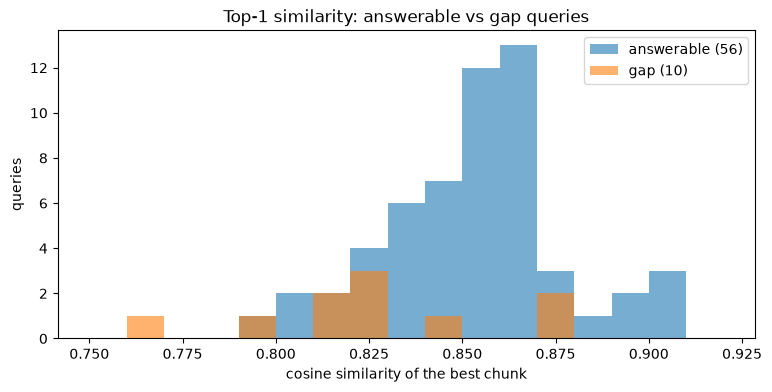

In [89]:
import matplotlib.pyplot as plt

rows = []
for q in df_q.itertuples():
    for rank, (doc, score) in enumerate(retrieve(q.query), start=1):
        rows.append({
            "query_id": q.Index,
            "group": "answerable" if q.answerable else "gap",
            "rank": rank,
            "score": score,
            "relevant": doc.metadata["doc_id"] in q.relevant,
        })
df_scores = pd.DataFrame(rows)
free_memory()

PERCENTILES = [0.1, 0.5, 0.9]
top1 = df_scores[df_scores["rank"] == 1]
print("Top-1 score per query:")
print(top1.groupby("group")["score"].describe(percentiles=PERCENTILES).round(3).to_string())
print()
print(f"Scores of the top-{TOP_K} chunks, answerable queries only:")
answerable_scores = df_scores[df_scores["group"] == "answerable"]
print(answerable_scores.groupby("relevant")["score"].describe(percentiles=PERCENTILES).round(3).to_string())

bins = np.arange(0.75, 0.92, 0.01)
fig, ax = plt.subplots(figsize=(9, 4))
for group, part in top1.groupby("group"):
    ax.hist(part["score"], bins=bins, alpha=0.6, label=f"{group} ({len(part)})")
ax.set_xlabel("cosine similarity of the best chunk")
ax.set_ylabel("queries")
ax.set_title("Top-1 similarity: answerable vs gap queries")
ax.legend()
plt.show()

In [90]:
top1_by_group = {group: part["score"] for group, part in top1.groupby("group")}

table_rows = []
for threshold in [t / 100 for t in range(76, 87)]:
    cut = answerable_scores[answerable_scores["score"] < threshold]
    table_rows.append({
        "threshold": threshold,
        "gap queries left empty": int((top1_by_group["gap"] < threshold).sum()),
        "answerable queries left empty": int((top1_by_group["answerable"] < threshold).sum()),
        "relevant chunks cut": int(cut["relevant"].sum()),
        "irrelevant chunks cut": int((~cut["relevant"]).sum()),
    })
threshold_table = pd.DataFrame(table_rows)

print(f"Queries: {len(top1_by_group['answerable'])} answerable, {len(top1_by_group['gap'])} gap")
print(f"Top-{TOP_K} chunks of answerable queries: {answerable_scores['relevant'].sum()} relevant, {(~answerable_scores['relevant']).sum()} irrelevant")
print()
print(threshold_table.to_string(index=False))

SCORE_THRESHOLD = 0.78

lowest_gap = top1[top1["group"] == "gap"].sort_values("score").iloc[0]
gap_query = df_q.loc[lowest_gap["query_id"], "query"]
print()
print(f"SCORE_THRESHOLD = {SCORE_THRESHOLD}")
print(f"Gap query with the lowest top-1 score ({lowest_gap['score']:.3f}): {gap_query}")
show_hits(retrieve(gap_query, threshold=SCORE_THRESHOLD))

Queries: 56 answerable, 10 gap
Top-5 chunks of answerable queries: 95 relevant, 185 irrelevant

 threshold  gap queries left empty  answerable queries left empty  relevant chunks cut  irrelevant chunks cut
      0.76                       0                              0                    0                      0
      0.77                       1                              0                    0                      0
      0.78                       1                              0                    0                      3
      0.79                       1                              0                    1                      3
      0.80                       2                              1                    1                      7
      0.81                       2                              3                    4                     18
      0.82                       4                              5                   10                     37
      0.83              

**Threshold = 0.78.** The two score distributions overlap almost entirely, so no threshold separates
answerable from gap queries. 0.78 is the highest value that removes no chunk of a relevant document; it
empties 1 of 10 gap queries and drops 3 irrelevant chunks. Emptying 7 of 10 gap queries would take 0.83,
which also empties 9 of 56 answerable queries and cuts 19 of 95 relevant chunks. The threshold is therefore
kept as a floor against clearly unrelated queries, and refusing to answer is left to the generation prompt.
It was picked on the same 66 queries the system is evaluated on; with 10 gap queries there is no held-out
set to confirm it.

### 3.6 Metadata filter

In [91]:
FILTER_CATEGORY = "Подписка и оплата"

filter_q = df_q.loc[21]
print(f"Query 21 ({filter_q['kind']}): {filter_q['query']}")
print("Relevant docs:", sorted(filter_q["relevant"]))
print()
print("No filter:")
show_hits(retrieve(filter_q["query"], threshold=SCORE_THRESHOLD), filter_q["relevant"])
print()
print(f"Filter category == {FILTER_CATEGORY!r}:")
filtered_hits = retrieve(filter_q["query"], threshold=SCORE_THRESHOLD, category=FILTER_CATEGORY)
show_hits(filtered_hits, filter_q["relevant"])
assert all(doc.metadata["category"] == FILTER_CATEGORY for doc, _ in filtered_hits), "filter let another category through"
print()
print(f"Chunks in the category: {(df_chunks['category'] == FILTER_CATEGORY).sum()} of {len(df_chunks)}")

Query 21 (semantic): передумал пользоваться сервисом, как отказаться и вернуть деньги
Relevant docs: [64]

No filter:
  + 0.843 | doc  64 chunk 4 | Подписка и оплата | Отмена подписки и возврат средств
    0.835 | doc 173 chunk 2 | Аккаунт и профили | Что делать при подозрении на взлом
  + 0.832 | doc  64 chunk 3 | Подписка и оплата | Отмена подписки и возврат средств
  + 0.831 | doc  64 chunk 2 | Подписка и оплата | Отмена подписки и возврат средств
  + 0.830 | doc  64 chunk 0 | Подписка и оплата | Отмена подписки и возврат средств

Filter category == 'Подписка и оплата':
  + 0.843 | doc  64 chunk 4 | Подписка и оплата | Отмена подписки и возврат средств
  + 0.832 | doc  64 chunk 3 | Подписка и оплата | Отмена подписки и возврат средств
  + 0.831 | doc  64 chunk 2 | Подписка и оплата | Отмена подписки и возврат средств
  + 0.830 | doc  64 chunk 0 | Подписка и оплата | Отмена подписки и возврат средств
  + 0.826 | doc  64 chunk 1 | Подписка и оплата | Отмена подписки и возврат средств


### 3.7 Baseline metrics

In [92]:
MAX_K = 20


def precision_at_k(chunk_docs: list[int], relevant: set[int], k: int = TOP_K) -> float:
    """Share of the top-k chunks that come from a relevant doc."""
    return sum(doc_id in relevant for doc_id in chunk_docs[:k]) / k


def recall_at_k(chunk_docs: list[int], relevant: set[int], k: int = TOP_K) -> float:
    """Share of the relevant docs that have at least one chunk among the top-k chunks."""
    return len(set(chunk_docs[:k]) & relevant) / len(relevant)


def reciprocal_rank(chunk_docs: list[int], relevant: set[int]) -> float:
    """1 / rank of the first relevant doc among the unique docs of the retrieved chunks; 0.0 if none."""
    for rank, doc_id in enumerate(dict.fromkeys(chunk_docs), start=1):
        if doc_id in relevant:
            return 1 / rank
    return 0.0


answerable_q = df_q[df_q["answerable"]]
chunk_docs_by_query = {
    q.Index: [doc.metadata["doc_id"] for doc, _ in retrieve(q.query, k=MAX_K, threshold=SCORE_THRESHOLD)]
    for q in answerable_q.itertuples()
}
free_memory()

pairs = [(chunk_docs_by_query[q.Index], q.relevant) for q in answerable_q.itertuples()]
baseline = pd.DataFrame({
    "kind": answerable_q["kind"],
    "precision@5": [precision_at_k(chunk_docs, relevant) for chunk_docs, relevant in pairs],
    "recall@5": [recall_at_k(chunk_docs, relevant) for chunk_docs, relevant in pairs],
    "MRR": [reciprocal_rank(chunk_docs, relevant) for chunk_docs, relevant in pairs],
})

BASELINE_METRICS = ["precision@5", "recall@5", "MRR"]
baseline_table = pd.concat([
    baseline[BASELINE_METRICS].mean().to_frame("all").T,
    baseline.groupby("kind", sort=False)[BASELINE_METRICS].mean(),
])
baseline_table.insert(0, "queries", [len(baseline), *baseline["kind"].value_counts(sort=False)])
print(baseline_table.round(3).to_string())

          queries  precision@5  recall@5    MRR
all            56        0.339     0.705  0.701
exact          15        0.440     0.967  0.967
semantic       25        0.240     0.600  0.529
multi          16        0.400     0.625  0.721


          recall@1  recall@3  recall@5  recall@10  recall@20
all          0.482     0.634     0.705      0.866      0.946
exact        0.900     0.967     0.967      1.000      1.000
semantic     0.360     0.520     0.600      0.860      0.940
multi        0.281     0.500     0.625      0.750      0.906


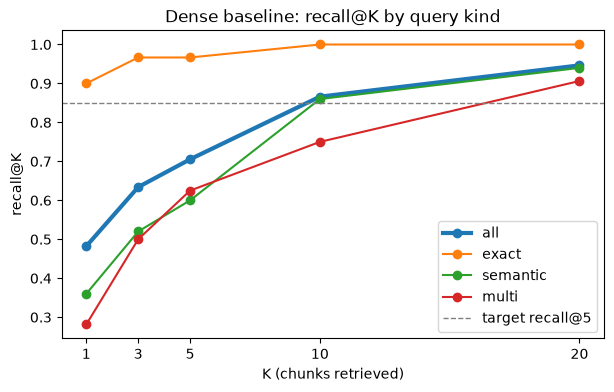

In [93]:
K_VALUES = [1, 3, 5, 10, 20]

for k in K_VALUES:
    baseline[f"recall@{k}"] = [recall_at_k(chunk_docs, relevant, k) for chunk_docs, relevant in pairs]

CURVE = [f"recall@{k}" for k in K_VALUES]
curve_table = pd.concat([
    baseline[CURVE].mean().to_frame("all").T,
    baseline.groupby("kind", sort=False)[CURVE].mean(),
])
print(curve_table.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for name, row in curve_table.iterrows():
    ax.plot(K_VALUES, row.to_numpy(), marker="o", linewidth=3 if name == "all" else 1.5, label=name)
ax.axhline(0.85, color="gray", linestyle="--", linewidth=1, label="target recall@5")
ax.set_xticks(K_VALUES)
ax.set_xlabel("K (chunks retrieved)")
ax.set_ylabel("recall@K")
ax.set_title("Dense baseline: recall@K by query kind")
ax.legend()
plt.show()

### Step 3 summary

- **Approach.** The pipeline is assembled with LangChain (`Document`, `HuggingFaceEmbeddings`,
  `QdrantVectorStore`) so that the same components plug into the generation chain later. The wrapper was
  checked rather than trusted: its 300 passage vectors equal the Step 2 vectors exactly (max difference 0),
  so prefixes and normalization match. It also replaces every "\n" with a space before encoding; this is
  harmless for the XLM-R tokenizer but would silently shift vectors for a tokenizer that keeps line breaks.
- **Vector store.** Qdrant in local mode: metadata filter inside the search, cosine similarity returned as
  the score, the same client code against a server later. Collection: 300 points, size 768, cosine.
- **Index.** Exact brute-force search over 0.88 MB of vectors; index recall against exact search is 1.0 by
  construction. To be revisited beyond tens of thousands of chunks or under concurrent load: Qdrant server
  with HNSW, a payload index on `category`, quantization at millions of vectors.
- **Retrieval pipeline.** `retrieve(query, k, threshold, category)`: query embedding with the `query: `
  prefix -> cosine search -> score threshold -> up to K chunks with metadata (`doc_id`, `position`, `title`,
  `category`).
- **Threshold = 0.78.** Top-1 similarity is 0.795-0.907 for answerable queries and 0.760-0.874 for gap
  queries; the distributions overlap, and inside the top 5 the medians of relevant and irrelevant chunks
  differ by 0.014. 0.78 is the highest value that cuts no chunk of a relevant document; it empties 1 of 10
  gap queries. A threshold of 0.83 would empty 7 gap queries but also 9 of 56 answerable ones. The threshold
  is a floor against clearly unrelated queries; refusals are left to the generation prompt. It was picked on
  the evaluation queries themselves, with no held-out set.
- **Metadata filter.** Filtering by `metadata.category == "Подписка и оплата"` (63 of 300 chunks) removes
  the out-of-category chunk, and the top 5 is refilled from the category because the filter is applied
  inside the search. It is not used in the baseline: the category of a query is not known in advance, and a
  wrong category hides the answer.
- **Baseline, 56 answerable queries.** Top-K chunks -> unique source documents -> comparison with the labels.

| | precision@5 | recall@5 | MRR | recall@1 | recall@3 | recall@10 | recall@20 |
|---|---|---|---|---|---|---|---|
| all (56) | 0.339 | 0.705 | 0.701 | 0.482 | 0.634 | 0.866 | 0.946 |
| exact (15) | 0.440 | 0.967 | 0.967 | 0.900 | 0.967 | 1.000 | 1.000 |
| semantic (25) | 0.240 | 0.600 | 0.529 | 0.360 | 0.520 | 0.860 | 0.940 |
| multi (16) | 0.400 | 0.625 | 0.721 | 0.281 | 0.500 | 0.750 | 0.906 |

- **Reading the numbers.** recall@5 = 0.705 against the 0.85 target. It is lower than the 0.759 of Step 2
  because the unit changed: there the top 5 were unique documents, here they are chunks, and several chunks
  of one document take several of the five slots. precision@5 has a low ceiling: most queries have one
  relevant document, and a document has 2.3 chunks on average. One query weighs 0.018, so a difference of
  one or two queries is noise.
- **Carried forward.** The curve crosses the target between K = 5 and K = 10 and reaches 0.946 at K = 20:
  relevant documents are retrieved but ranked too low, mostly for `semantic` and `multi` queries, while
  `exact` is nearly solved. That is a ranking problem, which points to reranking the top 20 (ceiling 0.946);
  the remaining 0.054 of recall lies outside the top 20 and needs a different remedy. `baseline` keeps the
  per-query metrics for the before/after comparison.

## Step 4. Retrieval diagnosis and improvement

### 4.1 Where the relevant documents rank

In [94]:
all_chunk_docs = {
    q.Index: [doc.metadata["doc_id"] for doc, _ in retrieve(q.query, k=len(documents))] for q in answerable_q.itertuples()
}
free_memory()

rank_rows = []
for q in answerable_q.itertuples():
    for doc_id in sorted(q.relevant):
        rank_rows.append({
            "query_id": q.Index,
            "kind": q.kind,
            "doc_id": doc_id,
            "rank": all_chunk_docs[q.Index].index(doc_id) + 1
        })
doc_ranks = pd.DataFrame(rank_rows)
doc_ranks["bucket"] = pd.cut(doc_ranks["rank"], bins=[0, 5, 10, 20, len(documents)], labels=["1-5", "6-10", "11-20", "21+"])
print("Rank of the best chunk of each relevant doc (dense search, no threshold):")
print(pd.crosstab(doc_ranks["kind"], doc_ranks["bucket"], margins=True).to_string())
print()
print("Deepest rank:", doc_ranks["rank"].max())

low = baseline[baseline["recall@5"] < 1]
print()
print(f"Queries with recall@5 < 1: {len(low)} of {len(baseline)}, {(low['recall@5'] == 0).sum()} of them with recall@5 = 0")
for query_id, row in low.iterrows():
    ranks = doc_ranks.loc[doc_ranks["query_id"] == query_id, "rank"].tolist()
    print(f"{query_id:>3} {row['kind']:<8} | recall@5 {row['recall@5']:.1f} | ranks {ranks} | {df_q.loc[query_id, 'query']}")

Rank of the best chunk of each relevant doc (dense search, no threshold):
bucket    1-5  6-10  11-20  21+  All
kind                                
exact      15     1      0    0   16
multi      20     4      5    3   32
semantic   16     7      2    2   27
All        51    12      7    5   75

Deepest rank: 38

Queries with recall@5 < 1: 23 of 56, 10 of them with recall@5 = 0
 11 exact    | recall@5 0.5 | ranks [1, 7] | на каком тарифе доступен звук 5.1
 18 semantic | recall@5 0.5 | ranks [22, 2] | как сделать, чтобы деньги сами не снимались каждый месяц
 20 semantic | recall@5 0.0 | ranks [7] | не пускает в аккаунт, пароль вылетел из головы
 22 semantic | recall@5 0.0 | ranks [6] | начал в метро с телефона, дома хочу досмотреть на большом экране с той же секунды
 24 semantic | recall@5 0.5 | ranks [9, 2] | кажется, кто-то чужой заходит в мой аккаунт
 28 semantic | recall@5 0.0 | ranks [7] | случайно зарегистрировался дважды, оплата ушла на старую регистрацию
 30 semantic | recall@5 

### 4.2 Manual review

In [95]:
import textwrap


def show_miss(query_id: int, text_chars: int = 400) -> None:
    """Print the top-5 chunks of a query and the best chunk of every relevant doc that missed the top 5."""
    q = df_q.loc[query_id]
    hits = retrieve(q["query"], k=len(documents))
    print(f"Query {query_id} ({q['kind']}): {q['query']}")
    print("Gold:", q["gold"])
    print("Relevant docs:", sorted(q["relevant"]))
    show_hits(hits[:TOP_K], q["relevant"])
    found = {doc.metadata["doc_id"] for doc, _ in hits[:TOP_K]}
    for doc_id in sorted(q["relevant"] - found):
        chunk_ranks = {
            doc.metadata["position"]: rank
            for rank, (doc, _) in enumerate(hits, start=1)
            if doc.metadata["doc_id"] == doc_id
        }
        best_rank = min(chunk_ranks.values())
        best_doc, best_score = hits[best_rank - 1]
        print(f"  missed doc {doc_id}: best chunk at rank {best_rank}, score {best_score:.3f} | chunk -> rank: {chunk_ranks}")
        print(textwrap.indent(textwrap.fill(best_doc.page_content[:text_chars], width=110), "      "))
    print()


for query_id in (20, 37, 40):
    show_miss(query_id)

Query 20 (semantic): не пускает в аккаунт, пароль вылетел из головы
Gold: нажать «Забыли пароль?» на экране входа; ссылка придёт на почту, код — в СМС
Relevant docs: [55]
    0.814 | doc  72 chunk 0 | Аккаунт и профили | Почему не удаётся войти в аккаунт
    0.805 | doc  72 chunk 1 | Аккаунт и профили | Почему не удаётся войти в аккаунт
    0.802 | doc 117 chunk 2 | Аккаунт и профили | Способы входа в аккаунт
    0.802 | doc 130 chunk 2 | Аккаунт и профили | Настройки профиля
    0.799 | doc 166 chunk 3 | Устройства и качество | Привязанные устройства и их лимит
  missed doc 55: best chunk at rank 7, score 0.798 | chunk -> rank: {0: 7}
      Восстановление пароля Если не получается войти, нажмите «Забыли пароль?» на экране входа.  Восстановление
      работает через то, что привязано к аккаунту: на почту придёт ссылка для смены пароля, на телефон — СМС с
      кодом. После смены пароля все ранее выполненные входы сохраняются. Если доступа к привязанной почте и номеру
      больше нет, 

**Diagnosis.** The misses were checked against four possible causes.

1. *The document is retrieved but ranked too low* - the main cause: 19 of 24 missed documents sit at ranks
   6-20. In query 20 the answering chunk is at rank 7 with 0.798 against 0.799 for the fifth chunk; chunks
   that share the topic ("cannot sign in") outrank the chunk that answers ("reset the password").
2. *The query wording is far from the document text* - 5 documents at ranks 21-38 (queries 18, 37, 40, 54,
   55). Query 37 never says "notifications" and its top 5 is about app failures. In `multi` queries one
   vector has to cover two topics and leans to one of them: 11 of the 16 `multi` queries miss a document,
   at ranks 6-38.
3. *Exact terms and codes are handled badly by dense search* - not observed: `exact` recall@5 is 0.967 and
   the single miss is at rank 7.
4. *Chunking or data* - a contributing cause for the tariffs document (doc 113), missed in 4 queries (11,
   40, 41, 51). Its facts live in one list-like chunk (chunk 2), and in query 40 a different chunk of the
   document ranks first (rank 38, about promo codes) while the answering chunk is at rank 53. A
   document-level hit can therefore come from a chunk that does not hold the answer.

### 4.3 Reranker

**Choice of method.** The diagnosis points to ranking: 19 of 24 missed documents are already among the
first 20 chunks, and every relevant document is within the first 38. A cross-encoder reranker addresses
exactly this: dense search supplies the candidates, the cross-encoder reads the query and the chunk
together and reorders them. Methods not applied, by the same diagnosis: hybrid search with BM25 (exact
terms are not the problem, `exact` recall@5 is 0.967); query expansion and HyDE (each costs an LLM call per
query, while the documents they would bring in are reachable by widening the candidate pool); RRF is a
fusion step for those methods and is not needed without them.

In [96]:
from sentence_transformers import CrossEncoder

RERANK_MODEL = "BAAI/bge-reranker-v2-m3"

reranker = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)
free_memory()


def retrieve_reranked(
    query: str, k: int = TOP_K, fetch_k: int = 20, threshold: float | None = None, category: str | None = None
) -> list[tuple[Document, float]]:
    """Dense search for fetch_k candidates, cross-encoder scores for (query, chunk) pairs, top k by the new score."""
    candidates = retrieve(query, k=fetch_k, threshold=threshold, category=category)
    if not candidates:
        return []
    scores = reranker.predict([(query, doc.page_content) for doc, _ in candidates], batch_size=32, show_progress_bar=False)
    order = np.argsort(-scores)[:k]
    return [(candidates[i][0], float(scores[i])) for i in order]


n_params = sum(p.numel() for p in reranker.model.parameters())
print(f"Reranker: {RERANK_MODEL} | {n_params / 1e6:.0f}M parameters | device {DEVICE}")
print()
for query_id in (20, 37):
    q = df_q.loc[query_id]
    print(f"Query {query_id} ({q['kind']}): {q['query']}")
    print("Relevant docs:", sorted(q["relevant"]))
    show_hits(retrieve_reranked(q["query"], threshold=SCORE_THRESHOLD), q["relevant"])
    print()
free_memory()

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Reranker: BAAI/bge-reranker-v2-m3 | 568M parameters | device mps

Query 20 (semantic): не пускает в аккаунт, пароль вылетел из головы
Relevant docs: [55]
    0.149 | doc  72 chunk 0 | Аккаунт и профили | Почему не удаётся войти в аккаунт
    0.096 | doc 117 chunk 2 | Аккаунт и профили | Способы входа в аккаунт
    0.041 | doc 173 chunk 0 | Аккаунт и профили | Что делать при подозрении на взлом
  + 0.040 | doc  55 chunk 0 | Аккаунт и профили | Восстановление пароля
    0.039 | doc  72 chunk 2 | Аккаунт и профили | Почему не удаётся войти в аккаунт

Query 37 (semantic): в приложении всё включено, а на телефон ничего не приходит
Relevant docs: [124]
    0.016 | doc  98 chunk 0 | Ошибки воспроизведения | Универсальный чек-лист при любой ошибке
    0.010 | doc  94 chunk 1 | Ошибки воспроизведения | Ошибка P-101: нет соединения
    0.004 | doc  41 chunk 0 | Аккаунт и профили | Уведомления о входе в аккаунт
    0.002 | doc  54 chunk 0 | Ошибки воспроизведения | Приложение зависает на заставке

### 4.4 Before and after

In [97]:
def evaluate_retrieval(search) -> pd.DataFrame:
    """Per-query metrics of a search function; search(query) returns up to MAX_K (chunk, score) pairs."""
    rows = []
    for q in answerable_q.itertuples():
        chunk_docs = [doc.metadata["doc_id"] for doc, _ in search(q.query)]
        row = {
            "kind": q.kind,
            "precision@5": precision_at_k(chunk_docs, q.relevant),
            "MRR": reciprocal_rank(chunk_docs, q.relevant),
        }
        for k in K_VALUES:
            row[f"recall@{k}"] = recall_at_k(chunk_docs, q.relevant, k)
        rows.append(row)
    return pd.DataFrame(rows, index=answerable_q.index)


results = {"dense baseline": baseline}
for fetch_k in (20, 40):
    results[f"rerank, fetch_k={fetch_k}"] = evaluate_retrieval(
        lambda query: retrieve_reranked(query, k=MAX_K, fetch_k=fetch_k, threshold=SCORE_THRESHOLD)
    )
    free_memory()

COMPARE = ["precision@5", "recall@5", "MRR", "recall@1", "recall@3", "recall@10", "recall@20"]
overall = pd.DataFrame({name: table[COMPARE].mean() for name, table in results.items()}).T
print(f"All {len(baseline)} answerable queries:")
print(overall.round(3).to_string())
print()
kind_recall = pd.DataFrame({name: table.groupby("kind", sort=False)["recall@5"].mean() for name, table in results.items()}).T
print("recall@5 by query kind:")
print(kind_recall.round(3).to_string())

All 56 answerable queries:
                    precision@5  recall@5    MRR  recall@1  recall@3  recall@10  recall@20
dense baseline            0.339     0.705  0.701     0.482     0.634      0.866      0.946
rerank, fetch_k=20        0.407     0.893  0.850     0.625     0.830      0.946      0.946
rerank, fetch_k=40        0.407     0.938  0.867     0.634     0.839      0.964      0.982

recall@5 by query kind:
kind                exact  semantic  multi
dense baseline      0.967      0.60  0.625
rerank, fetch_k=20  1.000      0.88  0.812
rerank, fetch_k=40  1.000      0.94  0.875


In [98]:
for name, table in results.items():
    if name == "dense baseline":
        continue
    diff = table["recall@5"] - baseline["recall@5"]
    unsolved = table.index[table["recall@5"] < 1]
    print(f"{name}: better {(diff > 0).sum()}, worse {(diff < 0).sum()}, same {(diff == 0).sum()} | recall@5 < 1 in {len(unsolved)} queries")
    for query_id in unsolved:
        print(f"  {query_id:>3} {table.loc[query_id, 'kind']:<8} | recall@5 {baseline.loc[query_id, 'recall@5']:.1f} -> {table.loc[query_id, 'recall@5']:.1f} | {df_q.loc[query_id, 'query']}")
    print()

rerank, fetch_k=20: better 14, worse 1, same 41 | recall@5 < 1 in 10 queries
   18 semantic | recall@5 0.5 -> 0.5 | как сделать, чтобы деньги сами не снимались каждый месяц
   23 semantic | recall@5 1.0 -> 0.0 | скачанная серия перестала открываться без интернета
   24 semantic | recall@5 0.5 -> 0.5 | кажется, кто-то чужой заходит в мой аккаунт
   37 semantic | recall@5 0.0 -> 0.0 | в приложении всё включено, а на телефон ничего не приходит
   40 multi    | recall@5 0.5 -> 0.5 | чем Стандарт отличается от Максимума и потеряю ли оплаченные дни при переходе
   41 multi    | recall@5 0.5 -> 0.5 | сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении
   48 multi    | recall@5 0.5 -> 0.5 | скачал сериал в дорогу, а место на телефоне кончилось и загрузка сорвалась
   50 multi    | recall@5 0.5 -> 0.5 | сменил пароль — нужно ли что-то делать с устройствами, где я уже вошёл
   54 multi    | recall@5 0.5 -> 0.5 | у меня телевизор AM-9, приложение не ставится — ка

### 4.5 Cost of the improvement

In [99]:
def time_search(search) -> np.ndarray:
    """Latency of search(query) in milliseconds, one value per answerable query, after one warm-up call."""
    search(answerable_q["query"].iloc[0])
    timings = []
    for query in answerable_q["query"]:
        start = time.perf_counter()
        search(query)
        timings.append((time.perf_counter() - start) * 1000)
    return np.array(timings)


searches = {
    "dense baseline": lambda query: retrieve(query, threshold=SCORE_THRESHOLD),
    "rerank, fetch_k=20": lambda query: retrieve_reranked(query, fetch_k=20, threshold=SCORE_THRESHOLD),
    "rerank, fetch_k=40": lambda query: retrieve_reranked(query, fetch_k=40, threshold=SCORE_THRESHOLD),
}
cost_rows = []
for name, search in searches.items():
    timings = time_search(search)
    free_memory()
    cost_rows.append({
        "variant": name,
        "recall@5": results[name]["recall@5"].mean(),
        "mean ms": timings.mean(),
        "p95 ms": np.percentile(timings, 95),
    })
cost_table = pd.DataFrame(cost_rows).set_index("variant")
print(cost_table.round({"recall@5": 3, "mean ms": 0, "p95 ms": 0}).to_string())

reranker_gb = sum(p.numel() * p.element_size() for p in reranker.model.parameters()) / 1024 ** 3
print()
print(f"Reranker weights: {reranker_gb:.2f} GB in memory")

FETCH_K = 40
print(f"FETCH_K = {FETCH_K}")

                    recall@5  mean ms  p95 ms
variant                                      
dense baseline         0.705      8.0    10.0
rerank, fetch_k=20     0.893    356.0   389.0
rerank, fetch_k=40     0.938    651.0   723.0

Reranker weights: 2.12 GB in memory
FETCH_K = 40


**Cost of the improvement.**

| | dense baseline | rerank, fetch_k=20 | rerank, fetch_k=40 |
|---|---|---|---|
| recall@5 | 0.705 | 0.893 | 0.938 |
| latency per query (mean, MPS) | about 10 ms | about 350 ms | about 650 ms |
| extra model | - | 568M parameters, 2.12 GB | the same model |
| pipeline | one search call | search + one model call | search + one model call |

- **Latency.** Reranking costs about 16-17 ms per candidate and grows linearly with `fetch_k`. The numbers are
  for an Apple M4 Pro on MPS; on CPU-only hardware they have to be measured again.
- **Extra model.** 568M parameters and 2.12 GB of weights, about twice the size of the embedder: one more
  model to download, keep in memory and version.
- **Complexity.** One extra stage with one parameter (`fetch_k`); no LLM call and no second index. It also
  brings a failure mode the baseline did not have: the reranker can push a correct chunk out of the top 5
  (query 23).
- **Decision: `fetch_k = 40`.** Doubling the pool adds 0.045 to recall@5 (four more queries fixed, none
  broken) for about 0.3 s per query, which is small next to answer generation. Three of those four queries
  cannot be fixed at `fetch_k = 20`: their document ranks below 20 in dense search.

### Step 4 summary

- **Low-metric queries.** 23 of 56 answerable queries have recall@5 < 1, 10 of them have recall@5 = 0; all
  ten are `semantic` or `multi`. Of the 75 relevant documents 51 have a chunk at ranks 1-5, 19 at ranks
  6-20 and 5 at ranks 21-38. No document is lost: the deepest rank is 38 of 300.
- **Diagnosis.** The main cause is ranking: the document is retrieved but stands too low (19 of 24 misses).
  The second cause is wording: 5 documents at ranks 21-38, and `multi` queries where one vector has to cover
  two topics. Exact terms are not a problem (`exact` recall@5 = 0.967). Chunking contributes for the tariffs
  document: in query 40 its best-ranked chunk is not the one that holds the answer.
- **Method.** A cross-encoder reranker (`BAAI/bge-reranker-v2-m3`): dense search returns 40 candidates, the
  reranker scores each (query, chunk) pair and keeps the top 5. Hybrid search, query expansion and HyDE were
  not applied because the diagnosis does not call for them; no LLM call is added to retrieval.
- **Before and after, same 56 queries and metrics.**

| | precision@5 | recall@5 | MRR | recall@1 | recall@3 | recall@10 | recall@20 |
|---|---|---|---|---|---|---|---|
| dense baseline | 0.339 | 0.705 | 0.701 | 0.482 | 0.634 | 0.866 | 0.946 |
| rerank, fetch_k=20 | 0.407 | 0.893 | 0.850 | 0.625 | 0.830 | 0.946 | 0.946 |
| rerank, fetch_k=40 | 0.407 | 0.938 | 0.867 | 0.634 | 0.839 | 0.964 | 0.982 |

| recall@5 by kind | exact (15) | semantic (25) | multi (16) |
|---|---|---|---|
| dense baseline | 0.967 | 0.600 | 0.625 |
| rerank, fetch_k=20 | 1.000 | 0.880 | 0.812 |
| rerank, fetch_k=40 | 1.000 | 0.940 | 0.875 |

- **Result.** recall@5 rises from 0.705 to 0.938 against the 0.85 target. Per query at `fetch_k = 40`: 18
  better, 1 worse, 37 unchanged. One query weighs 0.018, so the gain equals about 13 queries and is well
  beyond noise; the difference between 20 and 40 candidates is 4 queries and is a smaller, less certain gain.
- **What remains.** 6 queries: 23, 24, 40, 48, 50, 54. Query 23 is a regression: the reranker removed its
  relevant document from the top 5 (recall@5 1.0 -> 0.0). Four of the six are `multi`: every relevant
  document is within the 40 candidates, but a chunk that answers one half of a two-part question scores low
  against the whole question. Splitting such questions into parts is the natural next step.
- **Cost.** About 650 ms per query instead of about 10 ms (16-17 ms per candidate, Apple M4 Pro on MPS) and
  one more model of 568M parameters, 2.12 GB. One extra stage with one parameter.
- **Limits.** `fetch_k = 40` was chosen on these 56 queries (the deepest relevant rank is 38); it is a
  configuration value to re-check when the corpus or the queries change. Recall is counted per document, so
  a hit can come from a chunk that does not hold the answer; whether the generator gets the answer is
  measured in Step 6.
- **Carried forward.** Retrieval for generation is
  `retrieve_reranked(query, k=TOP_K, fetch_k=FETCH_K, threshold=SCORE_THRESHOLD)`. `results` keeps the
  per-query metrics of all three variants, and `evaluate_retrieval` is reused for the final profile.

## Step 5. Answer generation

### 5.1 LLM client

In [100]:
import time
from langchain_openai import ChatOpenAI

LLM_URL = "http://localhost:8080/v1"
LLM_MODEL = "qwen3.5"
MAX_TOKENS = 200

llm = ChatOpenAI(
    base_url=LLM_URL,
    api_key="not-needed",
    model=LLM_MODEL,
    temperature=0,
    max_tokens=MAX_TOKENS,
    extra_body={"chat_template_kwargs": {"enable_thinking": False}},
)

probe_question = "Что такое стриминговый сервис? Ответь одним предложением."
start = time.perf_counter()
reply = llm.invoke(probe_question)
elapsed = time.perf_counter() - start
repeat = llm.invoke(probe_question)

print("Model on the server:", reply.response_metadata["model_name"])
print("Answer:", reply.content)
print(f"Tokens: {reply.usage_metadata['input_tokens']} in, {reply.usage_metadata['output_tokens']} out, {elapsed:.1f} s")
print("Finish reason:", reply.response_metadata["finish_reason"])
print("Same answer on repeat:", repeat.content == reply.content)

Model on the server: unsloth/Qwen3.5-4B-GGUF:Q4_K_M
Answer: Стриминговый сервис — это онлайн-платформа, которая предоставляет пользователям доступ к каталогу фильмов, сериалов и музыки для просмотра или прослушивания в реальном времени без необходимости скачивания файлов на устройство.
Tokens: 26 in, 49 out, 2.1 s
Finish reason: stop
Same answer on repeat: True


### 5.2 Prompt

In [101]:
from langchain_core.prompts import ChatPromptTemplate

REFUSAL = "В базе знаний ответа нет."

SYSTEM_PROMPT = (
    "Ты ассистент службы поддержки онлайн-кинотеатра Фильмоскоп. "
    "Отвечай только по фрагментам базы знаний из сообщения пользователя. "
    "Не используй собственные знания и ничего не додумывай. "
    f"Если во фрагментах нет ответа на вопрос, ответь ровно одной фразой: {REFUSAL} "
    "Если в вопросе несколько частей, ответь на каждую. "
    "Отвечай по-русски, кратко, одним-тремя предложениями, без вступлений и без номеров фрагментов."
)
USER_TEMPLATE = "Фрагменты базы знаний:\n{context}\n\nВопрос: {question}"

prompt = ChatPromptTemplate.from_messages([("system", SYSTEM_PROMPT), ("human", USER_TEMPLATE)])


def format_docs(docs: list[Document]) -> str:
    """Join the retrieved chunks into one numbered context block."""
    return "\n\n".join(f"[{n}] {doc.page_content}" for n, doc in enumerate(docs, start=1))


probe_query = df_q.loc[6, "query"]
probe_docs = [doc for doc, _ in retrieve_reranked(probe_query, k=TOP_K, fetch_k=FETCH_K, threshold=SCORE_THRESHOLD)]
free_memory()
messages = prompt.format_messages(context=format_docs(probe_docs), question=probe_query)
reply = llm.invoke(messages)

for message in messages:
    print(f"--- {message.type} ---")
    print(message.content)
print("--- answer ---")
print(reply.content)
print("Gold:", df_q.loc[6, "gold"])
print(f"Prompt tokens: {reply.usage_metadata['input_tokens']}, answer tokens: {reply.usage_metadata['output_tokens']}")

--- system ---
Ты ассистент службы поддержки онлайн-кинотеатра Фильмоскоп. Отвечай только по фрагментам базы знаний из сообщения пользователя. Не используй собственные знания и ничего не додумывай. Если во фрагментах нет ответа на вопрос, ответь ровно одной фразой: В базе знаний ответа нет. Если в вопросе несколько частей, ответь на каждую. Отвечай по-русски, кратко, одним-тремя предложениями, без вступлений и без номеров фрагментов.
--- human ---
Фрагменты базы знаний:
[1] Тарифы «Фильмоскопа»
Сервис работает по подписке. Доступны три тарифа:

«Мобильный» — 199 ₽ в месяц. Просмотр на одном устройстве, только телефон или планшет. Качество до 720p. «Стандарт» — 399 ₽ в месяц. Просмотр на двух устройствах одновременно, качество до Full HD (1080p), доступно скачивание на мобильные устройства. «Максимум» — 599 ₽ в месяц. Просмотр на четырёх устройствах одновременно, качество до 4K HDR, звук 5.1, скачивание и все функции сервиса.

[2] Какой тариф подойдёт именно вам
В «Фильмоскопе» три тари

### 5.3 RAG chain

In [102]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnablePassthrough


def retrieve_docs(question: str) -> list[Document]:
    """Chunks for the prompt: dense search above the threshold, cross-encoder rerank, top k."""
    hits = retrieve_reranked(question, k=TOP_K, fetch_k=FETCH_K, threshold=SCORE_THRESHOLD)
    return [doc for doc, _ in hits]


generate = prompt | llm | StrOutputParser()


def answer_from_docs(state: dict) -> str:
    """Refuse without calling the LLM when retrieval returned nothing, otherwise generate from the chunks."""
    if not state["docs"]:
        return REFUSAL
    return generate.invoke({"context": format_docs(state["docs"]), "question": state["question"]})


rag_chain = (
    {"question": RunnablePassthrough(), "docs": RunnableLambda(retrieve_docs)}
    | RunnablePassthrough.assign(answer=RunnableLambda(answer_from_docs))
)

start = time.perf_counter()
result = rag_chain.invoke(probe_query)
elapsed = time.perf_counter() - start
free_memory()

print("Keys:", list(result))
print("Question:", result["question"])
print("Answer:", result["answer"])
print("Sources:")
for n, doc in enumerate(result["docs"], start=1):
    print(f"  [{n}] doc {doc.metadata['doc_id']:>3} chunk {doc.metadata['position']} | {doc.metadata['title']}")
print(f"Time: {elapsed:.1f} s")
print("Same answer as the manual call in 5.2:", result["answer"] == reply.content)

Keys: ['question', 'docs', 'answer']
Question: сколько стоит тариф Максимум и что в него входит
Answer: Тариф «Максимум» стоит 599 рублей в месяц. В него входит просмотр на четырёх устройствах одновременно, качество до 4K HDR со звуком 5.1, а также возможность скачивания и все функции сервиса.
Sources:
  [1] doc 113 chunk 2 | Тарифы «Фильмоскопа»
  [2] doc  24 chunk 0 | Какой тариф подойдёт именно вам
  [3] doc 152 chunk 0 | Качество изображения и автоподстройка
  [4] doc 113 chunk 3 | Тарифы «Фильмоскопа»
  [5] doc   3 chunk 0 | Что входит в подписку
Time: 1.6 s
Same answer as the manual call in 5.2: True


### 5.4 Check on query kinds

In [103]:
import textwrap

CHECK_QUERIES = [0, 20, 41, 40, 59, 62]


def show_answer(query_id: int) -> dict:
    """Run the chain on one labelled query, print the answer, the gold answer and the sources; return a summary row."""
    q = df_q.loc[query_id]
    result = rag_chain.invoke(q["query"])
    found = {doc.metadata["doc_id"] for doc in result["docs"]} & q["relevant"]
    print(f"[{query_id}] {q['kind']} | {q['query']}")
    print(textwrap.fill(f"Answer: {result['answer']}", width=120, subsequent_indent="  "))
    print(textwrap.fill(f"Gold:   {q['gold']}", width=120, subsequent_indent="  "))
    print("Sources:")
    if not result["docs"]:
        print("  (nothing above the threshold)")
    for doc in result["docs"]:
        meta = doc.metadata
        mark = "+" if meta["doc_id"] in q["relevant"] else " "
        print(f"  {mark} doc {meta['doc_id']:>3} chunk {meta['position']} | {meta['title']}")
    print()
    return {
        "query_id": query_id,
        "kind": q["kind"],
        "chunks": len(result["docs"]),
        "relevant docs found": f"{len(found)} of {len(q['relevant'])}",
        "refused": result["answer"] == REFUSAL,
    }


check_rows = [show_answer(query_id) for query_id in CHECK_QUERIES]
free_memory()
pd.DataFrame(check_rows).set_index("query_id")

[0] exact | что означает ошибка P-102
Answer: Ошибка P-102 означает, что число одновременных просмотров на аккаунте превышает лимит тарифа.
Gold:   превышено число одновременных просмотров по тарифу; нужно остановить просмотр на другом устройстве или перейти
  на тариф с большим лимитом
Sources:
  + doc  85 chunk 0 | Ошибка P-102: превышен лимит просмотров
    doc 165 chunk 0 | Ошибка P-112: аккаунт заблокирован
    doc  90 chunk 0 | Ошибка P-110: сбой на стороне сервиса
  + doc  85 chunk 1 | Ошибка P-102: превышен лимит просмотров
    doc  94 chunk 0 | Ошибка P-101: нет соединения

[20] semantic | не пускает в аккаунт, пароль вылетел из головы
Answer: Проверьте, что логин и пароль введены без пробелов и с учетом регистра букв. Если пароль не помните, нажмите
  кнопку «Забыли пароль?», чтобы восстановить доступ через почту или телефон.
Gold:   нажать «Забыли пароль?» на экране входа; ссылка придёт на почту, код — в СМС
Sources:
    doc  72 chunk 0 | Почему не удаётся войти в аккаунт
  

,kind,chunks,relevant docs found,refused
query_id,,,,
0,exact,5,1 of 1,False
20,semantic,5,1 of 1,False
41,multi,5,2 of 2,False
40,multi,5,1 of 2,False
59,gap,0,0 of 0,True
62,gap,5,0 of 0,True


### Step 5 summary

- **Generator.** `Qwen3.5-4B` (GGUF, Q4_K_M) on a local `llama-server`, called through `ChatOpenAI`.
  `temperature=0`: two identical calls in a row return the same text. Between full runs one answer of 56
  changed in Step 6, so the metrics are reproducible to within one query. The reasoning mode is switched
  off so that the 200-token budget goes to the answer; the probe answer ends with `finish_reason = stop`.
- **Prompt.** All four techniques from the task are applied: grounding (answer only from the retrieved
  fragments, no own knowledge), an explicit refusal with one fixed phrase kept in `REFUSAL`, separation of
  rules (system message) from the fragments and the question (user message, each under its own label), and
  a strict format (Russian, one to three sentences, no preamble, no fragment numbers). A separate line asks
  to answer every part of a multi-part question, because `multi` is the weakest kind after Step 4. Chunks
  are numbered and start with the article title. The prompt with five chunks takes 761 tokens of the 4096
  available.
- **Chain.** `rag_chain`: question -> `retrieve_reranked` (40 candidates above the 0.78 threshold, top 5
  after reranking) -> numbered context -> prompt -> LLM -> text. The chain returns the question, the
  retrieved chunks and the answer. The chain output equals the manual step-by-step call. One query takes
  about 2 s on an Apple M4 Pro.
- **Empty retrieval.** When the threshold leaves no chunks, the chain returns `REFUSAL` without calling the
  LLM: there is nothing to answer from, and the refusal is exact by construction.
- **Check on six queries.**

| query | kind | relevant docs in top 5 | result |
|---|---|---|---|
| 0 | exact | 1 of 1 | correct, shorter than the gold answer: the meaning of the error without the fix |
| 20 | semantic | 1 of 1 | correct; the answering chunk is fifth and is still used |
| 41 | multi | 2 of 2 | both parts answered; the last clause replaces "stop playback" with "unlink the device" |
| 40 | multi | 1 of 2 | second part correct, first part generic: the tariffs article is not retrieved |
| 59 | gap | - | refusal from the code, retrieval is empty |
| 62 | gap | - | refusal from the prompt with five payment chunks in the context |

- **Reading the check.** The system answers from the context and refuses when the answer is absent, also
  when the context is topically close (query 62). With half of the documents missing (query 40) the model
  gives a generic answer instead of inventing tariff details: the error comes from retrieval, not from
  generation. Query 41 shows the opposite case: retrieval is complete and the model distorts a detail.
- **Limits.** Six hand-picked queries are a functional check, not a measurement. The prompt was written for
  this model and this knowledge base and was not tuned on a held-out set. Whether an answer is correct is
  judged here by eye.
- **Carried forward.** `rag_chain.invoke(query)` returns `question`, `docs` and `answer`; Step 6 runs it on
  all 66 queries and scores faithfulness, answer relevance and correctness with an LLM judge. `REFUSAL` is
  the reference for counting refusals on `gap` queries.

## Step 6. Evaluation and final diagnosis

### 6.1 LLM judge

In [104]:
from pydantic import BaseModel, Field

JUDGE_MAX_TOKENS = 1000

judge_llm = ChatOpenAI(
    base_url=LLM_URL,
    api_key="not-needed",
    model=LLM_MODEL,
    temperature=0,
    max_tokens=JUDGE_MAX_TOKENS,
    extra_body={"chat_template_kwargs": {"enable_thinking": False}},
)


class Score(BaseModel):
    """Judge output on a 1-5 scale: the reason first, then the score."""

    reason: str
    score: int = Field(ge=1, le=5)


JUDGE_SYSTEM = (
    "Ты строгий эксперт по оценке ответов службы поддержки. Оценивай беспристрастно, "
    "длина ответа не является достоинством. Сначала кратко обоснуй, затем поставь оценку."
)

FAITH_PROMPT = """Оцени ВЕРНОСТЬ КОНТЕКСТУ: следует ли каждое утверждение ответа из фрагментов.
Соответствие вопросу не оценивай, только происхождение фактов.

Шкала:
5 - все утверждения следуют из фрагментов;
4 - добавлено только безобидное обобщение;
3 - добавлена неподтвержденная деталь;
2 - часть утверждений выдумана или противоречит фрагментам;
1 - ключевые факты отсутствуют во фрагментах или искажены.
Ответ «{refusal}» ничего не утверждает и получает 5.

Фрагменты:
{context}

Ответ: {answer}"""


def make_judge(template: str, schema: type[BaseModel]):
    """Chain for one metric: judge prompt -> LLM whose JSON output is constrained to the schema."""
    judge_prompt = ChatPromptTemplate.from_messages([("system", JUDGE_SYSTEM), ("human", template)])
    return judge_prompt | judge_llm.with_structured_output(schema, method="json_schema")


faith_judge = make_judge(FAITH_PROMPT, Score)

probe_context = format_docs(result["docs"])
probe_answers = {
    "chain answer": result["answer"],
    "made-up answer": "Тариф «Максимум» стоит 799 рублей в месяц и включает просмотр на шести устройствах.",
}
for name, answer in probe_answers.items():
    verdict = faith_judge.invoke({"context": probe_context, "answer": answer, "refusal": REFUSAL})
    print(f"{name}: faithfulness = {verdict.score}")
    print(textwrap.fill(f"Answer: {answer}", width=120, subsequent_indent="  "))
    print(textwrap.fill(f"Reason: {verdict.reason}", width=120, subsequent_indent="  "))
    print()

chain answer: faithfulness = 5
Answer: Тариф «Максимум» стоит 599 рублей в месяц. В него входит просмотр на четырёх устройствах одновременно, качество
  до 4K HDR со звуком 5.1, а также возможность скачивания и все функции сервиса.
Reason: Утверждение о цене (599 ₽), количестве устройств (4), качестве (4K HDR), звуке (5.1) и наличии скачивания
  полностью соответствует описанию тарифа «Максимум» в фрагменте [1]. Все детали из ответа имеют прямое подтверждение в
  источнике.

made-up answer: faithfulness = 2
Answer: Тариф «Максимум» стоит 799 рублей в месяц и включает просмотр на шести устройствах.
Reason: В предоставленных фрагментах указано, что тариф «Максимум» стоит 599 ₽ в месяц и позволяет просмотр на четырёх
  устройствах одновременно. В ответе утверждается цена 799 ₽ и количество устройств — шесть. Это не только противоречит
  данным фрагментов, но и содержит выдуманные факты.



In [105]:
class Correctness(BaseModel):
    """Judge output for the binary check: the reason first, then 1 or 0."""

    reason: str
    correct: int = Field(ge=0, le=1)


REL_PROMPT = """Оцени РЕЛЕВАНТНОСТЬ: отвечает ли ответ на заданный вопрос по существу.
Правдивость не проверяй, только соответствие вопросу.

Шкала:
5 - прямой и полный ответ;
4 - ответ по существу с небольшими отступлениями;
3 - закрыта только часть вопроса;
2 - текст на нужную тему, но ответа нет;
1 - другая тема или отказ отвечать.

Вопрос: {question}

Ответ: {answer}"""

CORRECT_PROMPT = """Сравни ОТВЕТ с ЭТАЛОНОМ и поставь correct.
1 - ответ передает главный факт эталона, формулировка может отличаться, лишние верные детали допустимы;
0 - ответ противоречит эталону, не содержит его главного факта или отказывается отвечать, хотя эталон содержит факт.
Если эталон говорит, что в базе знаний ответа нет, то 1 ставится за отказ отвечать, а 0 за любой содержательный ответ.

Вопрос: {question}

Эталон: {gold}

Ответ: {answer}"""

rel_judge = make_judge(REL_PROMPT, Score)
correct_judge = make_judge(CORRECT_PROMPT, Correctness)

EMPTY_CONTEXT = "(фрагментов нет)"
JUDGE_METRICS = ["faithfulness", "answer relevance", "correctness"]


def judge_answer(question: str, docs: list[Document], answer: str, gold: str) -> dict:
    """Three judge calls for one answer: faithfulness and answer relevance on a 1-5 scale, correctness as 0 or 1."""
    context = format_docs(docs) if docs else EMPTY_CONTEXT
    faith = faith_judge.invoke({"context": context, "answer": answer, "refusal": REFUSAL})
    rel = rel_judge.invoke({"question": question, "answer": answer})
    correct = correct_judge.invoke({"question": question, "gold": gold, "answer": answer})
    return {
        "faithfulness": faith.score,
        "answer relevance": rel.score,
        "correctness": correct.correct,
        "faith reason": faith.reason,
        "relevance reason": rel.reason,
        "correct reason": correct.reason,
    }


for query_id in (41, 40, 62):
    q = df_q.loc[query_id]
    case = rag_chain.invoke(q["query"])
    scores = judge_answer(q["query"], case["docs"], case["answer"], q["gold"])
    print(f"[{query_id}] {q['kind']} | {q['query']}")
    print(textwrap.fill(f"Answer: {case['answer']}", width=120, subsequent_indent="  "))
    print(textwrap.fill(f"Gold:   {q['gold']}", width=120, subsequent_indent="  "))
    print("Scores:", {metric: scores[metric] for metric in JUDGE_METRICS})
    print(textwrap.fill(f"Correctness reason: {scores['correct reason']}", width=120, subsequent_indent="  "))
    print()
free_memory()

[41] multi | сколько устройств могут смотреть одновременно на Стандарте и что будет при превышении
Answer: На тарифе «Стандарт» одновременно могут смотреть два устройства. Если превышен лимит просмотров, появится ошибка
  P-102, просмотр прерывается, и нужно перезапустить приложение или отвязать устройство с другого экрана.
Gold:   на «Стандарте» два одновременных просмотра; при превышении появляется ошибка P-102
Scores: {'faithfulness': 5, 'answer relevance': 5, 'correctness': 1}
Correctness reason: Ответ содержит все ключевые факты из эталона: указан лимит в два устройства для тарифа «Стандарт» и
  описана ошибка P-102 при превышении. Дополнительные рекомендации по перезапуску приложения или отвязке устройства не
  противоречат эталону и лишь дополняют ответ, что допустимо согласно правилам оценки.

[40] multi | чем Стандарт отличается от Максимума и потеряю ли оплаченные дни при переходе
Answer: В тарифах «Стандарт» и «Максимум» различается число одновременных просмотров, максимальн

### 6.2 Full run and profile

In [106]:
def evaluate_rag(queries: pd.DataFrame) -> pd.DataFrame:
    """Run the chain and the judge on every query; one row per query with the answer, the chunks and the judge scores."""
    rows = []
    start = time.perf_counter()
    for n, q in enumerate(queries.itertuples(), start=1):
        case = rag_chain.invoke(q.query)
        row = {
            "kind": q.kind,
            "query": q.query,
            "gold": q.gold,
            "answer": case["answer"],
            "refused": case["answer"] == REFUSAL,
            "docs": case["docs"],
        }
        row.update(judge_answer(q.query, case["docs"], case["answer"], q.gold))
        rows.append(row)
        if n % 11 == 0:
            free_memory()
            print(f"{n} of {len(queries)} queries, {time.perf_counter() - start:.0f} s")
    return pd.DataFrame(rows, index=queries.index)


report = evaluate_rag(df_q)

RETRIEVAL_METRICS = ["precision@5", "recall@5", "MRR"]
final_retrieval = results[f"rerank, fetch_k={FETCH_K}"]
report = report.join(final_retrieval[RETRIEVAL_METRICS])

chain_recall = [
    recall_at_k([doc.metadata["doc_id"] for doc in report.loc[i, "docs"]], df_q.loc[i, "relevant"])
    for i in answerable_q.index
]
assert np.allclose(chain_recall, report.loc[answerable_q.index, "recall@5"]), "the chain retrieves differently from Step 4"

print(f"Rows: {len(report)}, with retrieval metrics: {report['recall@5'].notna().sum()}")
print(f"Answers equal to the refusal phrase: {report['refused'].sum()}")
report[["kind", *RETRIEVAL_METRICS, *JUDGE_METRICS, "refused"]].head(8)

11 of 66 queries, 106 s
22 of 66 queries, 218 s
33 of 66 queries, 349 s
44 of 66 queries, 472 s
55 of 66 queries, 628 s
66 of 66 queries, 766 s
Rows: 66, with retrieval metrics: 56
Answers equal to the refusal phrase: 8


,kind,precision@5,recall@5,MRR,faithfulness,answer relevance,correctness,refused
0,exact,0.4,1.0,1.0,5,5,1,False
1,exact,0.2,1.0,1.0,2,5,0,False
2,exact,0.6,1.0,1.0,5,5,1,False
3,exact,0.2,1.0,1.0,3,3,0,False
4,exact,0.4,1.0,1.0,5,5,1,False
5,exact,0.2,1.0,1.0,5,5,1,False
6,exact,0.4,1.0,1.0,5,5,1,False
7,exact,0.8,1.0,1.0,5,5,1,False


In [107]:
TARGET_RECALL = 0.85
TARGET_CORRECTNESS = 0.90
PROFILE_METRICS = [*RETRIEVAL_METRICS, *JUDGE_METRICS]
KIND_ORDER = ["exact", "semantic", "multi", "gap"]

by_kind = report.groupby("kind")[PROFILE_METRICS].mean().loc[KIND_ORDER]
profile = pd.concat([report[PROFILE_METRICS].mean().to_frame("all").T, by_kind])
profile.insert(0, "queries", [len(report), *report["kind"].value_counts().loc[KIND_ORDER]])
profile["correct"] = [report["correctness"].sum(), *report.groupby("kind")["correctness"].sum().loc[KIND_ORDER]]

gap_report = report[report["kind"] == "gap"]
recall_final = report["recall@5"].mean()
correctness_final = report["correctness"].mean()
targets = pd.DataFrame([
    {
        "target": "recall@5, queries with an answer",
        "goal": f">= {TARGET_RECALL:.2f}",
        "value": f"{recall_final:.3f}",
        "met": recall_final >= TARGET_RECALL,
    },
    {
        "target": "correctness, all queries",
        "goal": f">= {TARGET_CORRECTNESS:.2f}",
        "value": f"{correctness_final:.3f}",
        "met": correctness_final >= TARGET_CORRECTNESS,
    },
    {
        "target": "gap queries answered with the refusal phrase",
        "goal": f"{len(gap_report)} of {len(gap_report)}",
        "value": f"{gap_report['refused'].sum()} of {len(gap_report)}",
        "met": gap_report["refused"].all(),
    },
])

display(profile.round(3))
display(targets)
print(f"Correct answers: {report['correctness'].sum()} of {len(report)}; the target needs {int(np.ceil(TARGET_CORRECTNESS * len(report)))}")
print(f"Faithfulness below 4: {(report['faithfulness'] < 4).sum()} answers")
print(f"Refusals on queries with an answer: {report.loc[report['kind'] != 'gap', 'refused'].sum()}")

,queries,precision@5,recall@5,MRR,faithfulness,answer relevance,correctness,correct
all,66,0.407,0.938,0.867,4.697,4.212,0.848,56
exact,15,0.400,1.000,1.000,4.667,4.867,0.867,13
semantic,25,0.320,0.940,0.761,4.600,4.720,0.840,21
multi,16,0.550,0.875,0.906,4.875,4.375,0.812,13
gap,10,NaN,NaN,NaN,4.700,1.700,0.900,9


,target,goal,value,met
0,"recall@5, queries with an answer",>= 0.85,0.938,True
1,"correctness, all queries",>= 0.90,0.848,False
2,gap queries answered with the refusal phrase,10 of 10,8 of 10,False


Correct answers: 56 of 66; the target needs 60
Faithfulness below 4: 8 answers
Refusals on queries with an answer: 0


### 6.3 Diagnosis matrix

In [108]:
FAITH_OK = 4
DIAGNOSIS_ORDER = [
    "no problem",
    "correct, low faithfulness",
    "correct, retrieval incomplete",
    "retrieval: document missing",
    "retrieval + generation: missing and made up",
    "generation: unsupported statement",
    "context: faithful but wrong",
    "gap: refusal phrase",
    "gap: no refusal phrase",
]


def diagnose(row: pd.Series) -> str:
    """Cell of the diagnosis matrix for one query: retrieval coverage x faithfulness x correctness."""
    if row["kind"] == "gap":
        return "gap: refusal phrase" if row["refused"] else "gap: no refusal phrase"
    found = row["recall@5"] == 1
    faithful = row["faithfulness"] >= FAITH_OK
    if row["correctness"] == 1:
        if not found:
            return "correct, retrieval incomplete"
        return "no problem" if faithful else "correct, low faithfulness"
    if not found:
        return "retrieval: document missing" if faithful else "retrieval + generation: missing and made up"
    return "context: faithful but wrong" if faithful else "generation: unsupported statement"


report["diagnosis"] = report.apply(diagnose, axis=1)
matrix = pd.crosstab(report["diagnosis"], report["kind"]).reindex(index=DIAGNOSIS_ORDER, columns=KIND_ORDER, fill_value=0)
matrix["total"] = matrix.sum(axis=1)
display(matrix)

errors = report[(report["correctness"] == 0) & (report["kind"] != "gap")]
full_retrieval = errors["recall@5"] == 1
print(f"Wrong answers on queries with an answer: {len(errors)}")
print(f"  all relevant docs in the top 5: {full_retrieval.sum()}, queries {list(errors.index[full_retrieval])}")
print(f"  a relevant doc missing:          {(~full_retrieval).sum()}, queries {list(errors.index[~full_retrieval])}")
for diagnosis in DIAGNOSIS_ORDER:
    if diagnosis not in ("no problem", "gap: refusal phrase"):
        print(f"{diagnosis}: {list(report.index[report['diagnosis'] == diagnosis])}")

kind,exact,semantic,multi,gap,total
diagnosis,,,,,
no problem,13,18,10,0,41
"correct, low faithfulness",0,2,1,0,3
"correct, retrieval incomplete",0,1,2,0,3
retrieval: document missing,0,0,2,0,2
retrieval + generation: missing and made up,0,1,0,0,1
generation: unsupported statement,2,1,0,0,3
context: faithful but wrong,0,2,1,0,3
gap: refusal phrase,0,0,0,8,8
gap: no refusal phrase,0,0,0,2,2


Wrong answers on queries with an answer: 9
  all relevant docs in the top 5: 6, queries [1, 3, 27, 33, 35, 55]
  a relevant doc missing:          3, queries [23, 40, 48]
correct, low faithfulness: [34, 38, 44]
correct, retrieval incomplete: [24, 50, 54]
retrieval: document missing: [40, 48]
retrieval + generation: missing and made up: [23]
generation: unsupported statement: [1, 3, 27]
context: faithful but wrong: [33, 35, 55]
gap: no refusal phrase: [63, 65]


**Reading the matrix.**

- **Profile level.** recall@5 = 0.938 and faithfulness = 4.70 are high while correctness = 0.848 is below the
  target. In the diagnosis matrix this is the row "high recall and faithfulness, low correctness": the model
  mostly follows the context, and the losses come from what the context holds and how it is used, not from
  missing documents.
- **Query level.** 9 answers are wrong on queries with an answer. In 6 of them every relevant document is
  in the top 5: three answers contain a statement the context does not support (queries 1, 3, 27) and three
  are faithful to the context but wrong (33, 35, 55). In 3 a relevant document is missing (23, 40, 48); these
  are known from Step 4 as queries the reranker did not fix.
- **Problem area.** The part of the pipeline after document retrieval: which chunks of a found document
  reach the prompt and how the generator uses them. Document retrieval explains 3 of the 9 errors.
- **Queries without an answer.** 8 of 10 get the refusal phrase. Queries 63 and 65 do not; whether they
  invent facts is checked in the manual review.
- **Limits of the matrix.** The split between the "generation" and "context" rows depends on the
  faithfulness score of a small judge model. Three correct answers are flagged with low faithfulness
  (34, 38, 44). The cause of each error is confirmed by reading the chunks in 6.4.

### 6.4 Manual review

In [109]:
def show_case(query_id: int) -> None:
    """Print one evaluated query for manual review: answer, gold, judge scores and reasons, full text of the prompt chunks."""
    row = report.loc[query_id]
    relevant = df_q.loc[query_id, "relevant"]
    in_prompt = {doc.metadata["chunk_id"] for doc in row["docs"]}
    print("=" * 120)
    print(f"[{query_id}] {row['kind']} | {row['query']}")
    print(
        f"Diagnosis: {row['diagnosis']} | faithfulness {row['faithfulness']}, "
        f"relevance {row['answer relevance']}, correctness {row['correctness']}"
    )
    fields = [
        ("Answer", row["answer"]),
        ("Gold", row["gold"]),
        ("Correctness reason", row["correct reason"]),
        ("Faithfulness reason", row["faith reason"]),
    ]
    for label, text in fields:
        print(textwrap.fill(f"{label}: {text}", width=120, subsequent_indent="  "))
    print("Chunks in the prompt:")
    for n, doc in enumerate(row["docs"], start=1):
        meta = doc.metadata
        mark = "+" if meta["doc_id"] in relevant else " "
        print(f"{mark} [{n}] doc {meta['doc_id']} chunk {meta['position']} | {meta['title']}")
        body = " ".join(doc.page_content.split("\n", 1)[-1].split())
        print(textwrap.fill(body, width=120, initial_indent="      ", subsequent_indent="      "))
    missing = df_chunks[df_chunks["doc_id"].isin(relevant) & ~df_chunks["chunk_id"].isin(in_prompt)]
    if len(missing):
        left_out = [f"doc {doc_id} chunk {position}" for doc_id, position in zip(missing["doc_id"], missing["position"])]
        print("Chunks of the relevant docs left out of the prompt:", ", ".join(left_out))
    print()


FULL_RETRIEVAL_ERRORS = [1, 3, 27, 33, 35, 55]
for query_id in FULL_RETRIEVAL_ERRORS:
    show_case(query_id)

[1] exact | какая версия webOS или Tizen нужна для приложения на телевизоре
Diagnosis: generation: unsupported statement | faithfulness 2, relevance 5, correctness 0
Answer: Для Samsung TV требуется webOS 4.0 и новее, а для LG — Tizen с 2018 года и новее.
Gold: LG с webOS 4.0 и новее, Samsung на Tizen с моделей 2018 года
Correctness reason: Ответ содержит фактические ошибки, прямо противоречащие эталону. В эталоне указано: LG использует
  webOS (с 4.0+), а Samsung — Tizen (с 2018 года). В ответе эти операционные системы и бренды перепутаны: для Samsung
  указан webOS, а для LG — Tizen. Это фундаментальное несоответствие делает ответ неверным.
Faithfulness reason: Утверждение содержит фактические ошибки, прямо противоречащие фрагментам. Фрагмент [1] указывает,
  что для Samsung TV требуется Tizen (с 2018 года), а для LG — webOS 4.0 и новее. В ответе эти операционные системы и
  бренды местами перепутаны: приписано LG Tizen (неверно) и Samsung webOS (неверно).
Chunks in the prompt:
+ [1]

In [110]:
OTHER_CASES = [23, 40, 48, 63, 65]
for query_id in OTHER_CASES:
    show_case(query_id)

[23] semantic | скачанная серия перестала открываться без интернета
Diagnosis: retrieval + generation: missing and made up | faithfulness 2, relevance 5, correctness 0
Answer: Скачанная серия перестала открываться без интернета, если на устройстве нет интернета или он слишком медленный.
  Проверьте, что приложение обновлено, и перезапустите его или само устройство. Если проблема не решена, возможно,
  серверы временно недоступны или у контента есть ограничения по показу.
Gold: истёк срок действия загрузки (30 дней); нужно подключиться к интернету для продления или скачать заново
Correctness reason: Ответ содержит информацию о проверке интернета и обновлении приложения, но полностью игнорирует
  главный факт из эталона — истечение срока действия загрузки (30 дней) и необходимость подключения к интернету для
  продления или повторной загрузки. Это ключевая причина проблемы, которая отсутствует в ответе.
Faithfulness reason: Ответ содержит три утверждения. Первое: 'Скачанная серия переста

**Manual review.** 11 cases were read: the 9 wrong answers and the 2 gap queries without the refusal phrase.

| query | where the gold fact is | what the system did | cause |
|---|---|---|---|
| 1 | chunk [1] | swapped the pairs: Samsung with webOS, LG with Tizen | generation: misread a list |
| 27 | chunk [1] | dropped "main screen of the child profile", called the child profile a separate account | generation: omission and distortion |
| 33 | chunk [1] | said watched films cannot be removed; the chunk says an entry can be removed from the history | generation: wrong inference |
| 3 | chunk [1] | answered the literal question (HDMI ARC), left out the optical cable and the tariff, added "restart playback" from chunk [2] | generation: detail taken from an unrelated chunk; the gold is wider than the question |
| 35 | chunk [1] | "search by actor" is given, sorting by year is left out | generation: incomplete answer, a borderline case |
| 55 | chunks [3] and [5] | followed "nothing has to be prepared before the trip" from chunk [2] and did not link the changed catalogue with downloading in advance | generation: no synthesis across two documents |
| 23 | not in the prompt (doc 49, error P-111) | built an answer from general troubleshooting chunks | retrieval: the regression of Step 4 |
| 40 | not in the prompt (doc 113, the tariff table) | first half of the answer is generic | retrieval |
| 48 | not in the prompt (doc 178, error P-109) | sensible advice (free the space, download again) without the error code | retrieval |
| 63 | chunk [1]: "downloading does not work on TVs" | grounded answer that states this restriction | judge error: the gold accepts this answer |
| 65 | absent from the knowledge base | refused in its own words | the refusal phrase is not followed |

- **The hypothesis of 6.3 is not confirmed.** In all six errors with complete retrieval the chunk with the
  answer is in the prompt, in five of them at position 1. The cause is the generator, not the choice of
  chunks: it misreads, drops a part, borrows a detail from a neighbouring chunk or fails to combine two
  documents.
- **Retrieval, 3 errors.** A relevant document is missing in each. In queries 23 and 48 it is an error-code
  article (P-111, P-109) while the query describes the symptom without the code.
- **Queries without an answer.** None of the ten answers invents a fact. Query 63 is answered from the
  context and correctly, so it is not a real gap; query 65 is a refusal in other words.
- **Judge.** 3 errors in 11 cases: correctness of query 63 (0 instead of 1), faithfulness of query 33
  (5 for a wrong inference) and of query 65 (2 for a refusal). With query 63 corrected, correctness is
  57 of 66 = 0.864, still below the 0.90 target.
- **Limits.** Only the answers marked wrong were re-read. Errors of the judge in favour of the system are
  not covered by this review.

### 6.5 Gold-context run

In [112]:
def gold_documents(relevant: set[int]) -> list[Document]:
    """Full text of the labelled relevant docs as prompt documents: title first, in doc_id order."""
    rows = df_clean[df_clean["doc_id"].isin(relevant)].sort_values("doc_id")
    return [Document(page_content=f"{row.title}\n{row.text}", metadata={"doc_id": row.doc_id}) for row in rows.itertuples()]


gold_rows = []
start = time.perf_counter()
for q in answerable_q.itertuples():
    answer = generate.invoke({"context": format_docs(gold_documents(q.relevant)), "question": q.query})
    verdict = correct_judge.invoke({"question": q.query, "gold": q.gold, "answer": answer})
    gold_rows.append({"kind": q.kind, "answer": answer, "correctness": verdict.correct, "correct reason": verdict.reason})
gold_report = pd.DataFrame(gold_rows, index=answerable_q.index)
free_memory()
print(f"{len(gold_report)} queries, {time.perf_counter() - start:.0f} s")

compare = pd.DataFrame({
    "kind": gold_report["kind"],
    "RAG": report.loc[answerable_q.index, "correctness"],
    "gold context": gold_report["correctness"],
})
RUNS = ["RAG", "gold context"]
gold_summary = pd.concat([compare[RUNS].mean().to_frame("all").T, compare.groupby("kind")[RUNS].mean().loc[KIND_ORDER[:3]]])
gold_summary["difference"] = gold_summary["gold context"] - gold_summary["RAG"]
display(gold_summary.round(3))

transitions = {
    "wrong -> correct": (compare["RAG"] == 0) & (compare["gold context"] == 1),
    "wrong -> wrong": (compare["RAG"] == 0) & (compare["gold context"] == 0),
    "correct -> wrong": (compare["RAG"] == 1) & (compare["gold context"] == 0),
}
for name, mask in transitions.items():
    print(f"{name}: {mask.sum()}, queries {list(compare.index[mask])}")
print(f"Refusals on the gold context: {(gold_report['answer'] == REFUSAL).sum()}")
print()
for query_id in compare.index[transitions["correct -> wrong"]]:
    print(f"[{query_id}] {df_q.loc[query_id, 'query']}")
    print(textwrap.fill(f"Gold-context answer: {gold_report.loc[query_id, 'answer']}", width=120, subsequent_indent="  "))
    print(textwrap.fill(f"Gold: {df_q.loc[query_id, 'gold']}", width=120, subsequent_indent="  "))

56 queries, 176 s


,RAG,gold context,difference
all,0.839,0.821,-0.018
exact,0.867,0.867,0.000
semantic,0.840,0.840,0.000
multi,0.812,0.750,-0.062


wrong -> correct: 4, queries [1, 23, 33, 48]
wrong -> wrong: 5, queries [3, 27, 35, 40, 55]
correct -> wrong: 5, queries [5, 25, 28, 50, 53]
Refusals on the gold context: 0

[5] что значит ошибка P-111
Gold-context answer: Ошибка P-111 означает, что истёк срок действия скачанного файла, из-за чего просмотр прерывается.
Gold: срок действия скачанного файла истёк; нужно подключиться к интернету для продления или скачать заново
[25] карта не проходит при оплате, хотя деньги на ней есть
Gold-context answer: Проверьте, не истек ли срок действия карты и не заблокировал ли платёж банк. Сервис автоматически
  повторяет попытку списания три раза в течение трёх дней. Если все попытки неудачны, подписка ставится на паузу до
  успешной оплаты.
Gold: проверить лимиты на интернет-платежи, срок действия карты и поддержку банком; попробовать другой способ оплаты
[28] случайно зарегистрировался дважды, оплата ушла на старую регистрацию
Gold-context answer: Объединить два аккаунта невозможно, поэтому ис

**Reading the gold-context run.**

- **Contribution of retrieval.** With the labelled documents in the prompt correctness is 0.821 (46 of 56)
  against 0.839 (47 of 56) with the retrieved chunks. `Q_gold - Q_rag` = -0.018, one query, which is within
  noise: a perfect retrieval does not raise correctness. The remaining `1 - Q_gold` = 0.179 cannot be
  recovered by any improvement of retrieval.
- **Close totals hide 9 changes.** The gold context repairs 4 answers. Queries 23 and 48 are the retrieval
  errors of 6.4. Queries 1 and 33 already had the answering chunk in the prompt, so their repair is not
  an effect of retrieval. It also breaks 5 answers that were correct on the retrieved chunks (5, 25, 28,
  50, 53). In queries 5, 25 and 53 the answer drops a part of the gold fact, in query 50 the model draws
  the wrong conclusion. The answer to query 28 states the gold fact (the accounts cannot be merged, choose
  the main one), so its 0 is a judge error.
- **Five answers stay wrong with a perfect context** (3, 27, 35, 40, 55). Query 40 was classified as a
  retrieval error; with the tariffs article in the prompt its answer is still judged wrong.
- **Conclusion.** The bottleneck is the generator. A 4B model reads the same facts differently when the
  context changes, and about one answer in six is wrong even with the right documents in the prompt.
  Retrieval can add two or three queries at most.
- **Limits.** One query weighs 0.018, and the judge is the same small model, so the run cannot resolve a
  difference of one or two queries. At `temperature=0` the local server still gave a different answer to
  query 28 in a repeated run of this cell, so totals can move by one query between runs. The gold context
  is whole documents, not only the answering chunk.

### Step 6 summary

- **Judge.** The same local model scores every answer on three metrics: faithfulness and answer relevance
  on a 1-5 scale, correctness as 0 or 1 against `gold`. The output is JSON constrained by a schema, with the
  reason written before the score. Each metric sees only its own inputs: faithfulness gets the chunks and
  the answer, relevance the question and the answer, correctness the question, the gold fact and the answer.
  For queries without an answer a refusal counts as correct.
- **Profile, 66 queries.** Retrieval metrics cover the 56 queries with an answer.

| | queries | precision@5 | recall@5 | MRR | faithfulness | answer relevance | correctness |
|---|---|---|---|---|---|---|---|
| all | 66 | 0.407 | 0.938 | 0.867 | 4.70 | 4.21 | 0.848 |
| exact | 15 | 0.400 | 1.000 | 1.000 | 4.67 | 4.87 | 0.867 |
| semantic | 25 | 0.320 | 0.940 | 0.761 | 4.60 | 4.72 | 0.840 |
| multi | 16 | 0.550 | 0.875 | 0.906 | 4.88 | 4.38 | 0.812 |
| gap | 10 | - | - | - | 4.70 | 1.70 | 0.900 |

- **Reading the profile.** 56 of 66 answers are correct. `multi` is the weakest kind. Answer relevance of
  `gap` is low by design of the scale: a refusal does not answer the question. There is no refusal on a
  query that has an answer.
- **Diagnosis matrix.** 9 answers are wrong on queries with an answer: in 6 every relevant document is in
  the top 5, in 3 a relevant document is missing. The problem area is the part of the pipeline after
  document retrieval.
- **Manual review of 11 cases.** Generation 6, retrieval 3, judge error 1, refusal phrase not followed 1. In
  all six generation errors the chunk with the answer is in the prompt, in five at position 1: the model
  misreads a list, drops a part, borrows a detail from a neighbouring chunk or does not combine two
  documents. No answer to a `gap` query invents a fact. With the judge error on query 63 corrected,
  correctness is 57 of 66 = 0.864.
- **Gold-context run.** With the labelled documents instead of the retrieved chunks correctness is 0.821
  against 0.839 on the same 56 queries. A perfect retrieval does not raise correctness; five answers stay
  wrong with a perfect context.
- **Limits.** The judge is the generator model itself, a 4B model; four judge errors were found by reading.
  Only the answers marked wrong were re-read, so errors in favour of the system are not covered. One query
  weighs 0.015, and a repeated run changed one answer at `temperature=0`, so correctness is known to about
  +-0.03. The threshold, `fetch_k` and the prompt were chosen on these same 66 queries; there is no held-out
  set.

## Verdict

**Targets.**

| target | goal | result | met |
|---|---|---|---|
| recall@5, queries with an answer | >= 0.85 | 0.938 | yes |
| correctness, all queries | >= 0.90 | 0.848 (0.864 after the manual correction) | no |
| queries without an answer: no invented facts, one refusal phrase | 10 of 10 | no invented facts in 10 of 10, the exact phrase in 8 of 10 | partly |

**Readiness.** The system is not ready for an unattended pilot. Retrieval is ready: the dense search with
the cross-encoder reranker raised recall@5 from 0.705 to 0.938. The system does not invent answers to
questions outside the knowledge base. But about one answer in six to a question that has an answer is
wrong, and some of the wrong answers are confident statements that would mislead a customer: swapped TV
platforms (query 1), "watched films cannot be removed" (query 33). The target needs 60 correct answers of
66; the system gives 56. A pilot is possible only with an operator in the loop: the assistant drafts the
answer and shows the source chunks, a person sends it.

**Three recommendations, in order.**

1. **Replace the generator with a stronger model and repeat this evaluation unchanged.** Six of the nine
   errors happen with the answer already in the prompt, and with a perfect context correctness is 0.821:
   this is the ceiling of the current 4B model, below the 0.90 target. No change in retrieval can cross it.
   Four more correct answers are needed, and this is where they are.
2. **Fix the answer contract in the prompt with examples.** Add few-shot examples: a complete answer that
   covers every part of the question and names the action to take, and a refusal that consists of the exact
   phrase. Answers that drop a part of the gold fact (queries 3 and 35; 5, 25 and 53 in the gold-context
   run) and the refusal in other words (query 65) are the reason. The change must be checked on queries that
   were not used to write the prompt.
3. **Make the measurement reliable before trusting any improvement.** Use a judge that is a different and
   stronger model, label a sample of answers by hand to measure the judge's error, extend the test set, and
   report the before/after difference with a paired bootstrap interval. The gap to the target is 4 queries,
   while the judge errs on about 4 and a repeated run moves the total by 1: today a gain of two or three
   queries cannot be told from noise.

**What is deliberately not in the top three.** Further work on retrieval. The gold-context run limits its
effect to two or three queries. When it becomes the bottleneck, the next step is to split multi-part
questions into sub-questions and retrieve for each: `multi` is the weakest kind (recall@5 0.875,
correctness 0.812), and queries 40 and 48 miss a document for exactly this reason.